# NDVI + ERA5 Vegetation Stress Pipeline V8 — Regional Mean + District-wise Normalized NDVI–ERA5 Graphs, 500 dpi PNGs


In [1]:
"""
NDVI + ERA5 Vegetation Stress Pipeline for Northern Bangladesh - V8 Regional + District-wise Combined Plots
Author: ChatGPT

Purpose
-------
1. Fill null values in large ERA5 CSV chunks.
2. Clean NDVI data.
3. Process large ERA5 gridded data into daily district-level climate features.
4. Align ERA5 date range to NDVI date range.
5. Engineer rolling climate features and NDVI lag features.
6. Build a three-class vegetation stress target: normal/good, moderate stress, high stress.
7. Add legitimate ERA5-derived agro-climate stress indices: SPI-like, ZSI, SPEI-proxy, PET, VPD, rainfall deficit, soil-moisture deficit, and wind stress.
8. Run trend analysis, regional-mean and district-wise normalized combined NDVI–ERA5 trend visualizations, and paper-style spatial stress visualizations.
9. Save all PNG outputs at 500 dpi for publication-quality figures.
10. Train multiclass classification models only using accuracy-oriented ensemble learning and explain them with permutation importance + SHAP.

Expected inputs
---------------
- NDVI CSV: NDVI_NorthernBD_2022_2024 - NDVI_NorthernBD_2022_2024.csv
- ERA5 CSV: final_merged_converted.csv, or test.csv for checking

Required packages
-----------------
pandas numpy matplotlib scikit-learn joblib
Optional: shap

Run
---
python ndvi_era5_pipeline_v7_paper_maps.py
"""

from __future__ import annotations

import os
import re
import urllib.request
import warnings
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier, StackingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
import joblib
from statistics import NormalDist
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")

In [2]:
# =========================
# 0. CONFIGURATION

In [3]:
# =========================

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path(".")

NDVI_PATH = BASE_DIR / "/kaggle/input/datasets/imthebaron/testing-multimodal/NDVI_NorthernBD_2022_2024 - NDVI_NorthernBD_2022_2024.csv"
ERA5_RAW_PATH = BASE_DIR / "/kaggle/input/datasets/imthebaron/testing-multimodal/final_merged_converted.csv"       # change to "test.csv" if needed
ERA5_FILLED_PATH = BASE_DIR / "final_merged_converted_null0.csv"
# Optional local district-only GeoJSON. If absent, V6 automatically downloads Bangladesh boundary data
# from the open-source ifahimreza/bangladesh-geojson project and dissolves it to the 11 districts.
DISTRICT_GEOJSON_PATH = BASE_DIR / "/kaggle/input/datasets/imthebaron/testing-multimodal/bangladesh.geojson"
BD_FULL_GEOJSON_URL = "https://raw.githubusercontent.com/ifahimreza/bangladesh-geojson/master/src/data/bangladesh.geojson"
BD_FULL_GEOJSON_PATH = BASE_DIR / "bangladesh_full_boundary_ifahimreza.geojson"
AUTO_DOWNLOAD_BD_GEOJSON = True
MAKE_GEOJSON_CLIPPED_STRESS_MAPS = True

# Paper-map style controls. These do not change model training or labels; they only improve visualization.
MAKE_PAPER_READY_COMPARISON_MAPS = True
MAP_SURFACE_RESOLUTION = 360
MAP_IDW_POWER = 1.7
MAP_SHOW_CENTROIDS = False
MAP_SHOW_DISTRICT_LABELS = True
MAP_BOUNDARY_LINEWIDTH = 0.75
MAP_DISTRICT_LINEWIDTH = 0.45
STRESS_COLORS = {
    "normal_good": "#1a9850",      # green
    "moderate_stress": "#fee08b",  # soft amber
    "high_stress": "#d73027",      # red
    "missing": "#d9d9d9",
}
STRESS_SHORT_LABELS = {
    "normal_good": "Normal",
    "moderate_stress": "Moderate",
    "high_stress": "High",
    "missing": "Missing",
}

OUTPUT_DIR = BASE_DIR / "outputs_ndvi_era5_stress"
FIG_DIR = OUTPUT_DIR / "figures"
DATA_DIR = OUTPUT_DIR / "processed_data"
MODEL_DIR = OUTPUT_DIR / "models"
PAPER_FIG_DIR = FIG_DIR / "paper_ready"
for p in [OUTPUT_DIR, FIG_DIR, DATA_DIR, MODEL_DIR, PAPER_FIG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

CHUNKSIZE = 1_000_000
ROLLING_WINDOWS = [7, 16, 30, 60]
MAX_LOOKBACK_DAYS = max(ROLLING_WINDOWS)
RANDOM_STATE = 42

# Publication-quality PNG export setting requested by the user.
PNG_DPI = 500

# Use only weather before the NDVI observation date.
# True prevents leakage because rolling windows are shifted by 1 day.
PREDICTIVE_MODE = True

# The user requested null values in ERA5/test.csv to be changed to 0.
FILL_ERA5_NULLS_WITH_ZERO = True

# Use previous NDVI as features. Good for forecasting, but run climate-only separately if your aim is climate impact.
USE_NDVI_LAG_FEATURES = True

# If 2024 exists, train on years before 2024 and test on 2024.
TEST_YEAR = 2024

# Accuracy-oriented but still non-fraudulent validation.
# "temporal_2024" = strict future-year validation, usually lower but stronger scientifically.
# "stratified_random_80_20" = paper-comparable random holdout; often higher, but do not claim it is future-year forecasting.
VALIDATION_MODE = "stratified_random_80_20"
MODEL_SELECTION_METRIC = "accuracy"  # alternatives: "macro_f1", "weighted_f1"

# Strict temporal evaluation is disabled by default because the user asked to remove that low-performing extra section.
# Turn this to True only if you need a future-year transparency check.
RUN_SECONDARY_TEMPORAL_CHECK = False

In [4]:
# =========================
# 0B. GEOJSON BOUNDARY CONFIGURATION

In [5]:
# =========================

# The public Bangladesh GeoJSON uses current/official names in some cases, e.g. Bogura.
# The NDVI file uses Bogra. These aliases make the merge robust.
DISTRICT_ALIAS_TO_STUDY_NAME = {
    "bogra": "Bogra",
    "bogura": "Bogra",
    "joypurhat": "Joypurhat",
    "jaipurhat": "Joypurhat",
    "naogaon": "Naogaon",
    "dinajpur": "Dinajpur",
    "gaibandha": "Gaibandha",
    "kurigram": "Kurigram",
    "lalmonirhat": "Lalmonirhat",
    "nilphamari": "Nilphamari",
    "panchagarh": "Panchagarh",
    "rangpur": "Rangpur",
    "thakurgaon": "Thakurgaon",
}
STUDY_DISTRICTS = sorted(set(DISTRICT_ALIAS_TO_STUDY_NAME.values()))


def _clean_name_for_match(x: object) -> str:
    """Lowercase and remove punctuation/spaces so GeoJSON and NDVI names match."""
    if pd.isna(x):
        return ""
    return re.sub(r"[^a-z0-9]+", "", str(x).lower())


def _format_lon(x, _pos=None):
    return f"{x:.1f}°E"


def _format_lat(y, _pos=None):
    return f"{y:.1f}°N"


def _stress_label_from_numeric(v: object) -> str:
    try:
        iv = int(round(float(v)))
    except Exception:
        return "missing"
    return {0: "normal_good", 1: "moderate_stress", 2: "high_stress"}.get(iv, "missing")


def _stress_short_label_from_numeric(v: object) -> str:
    return {"normal_good": "normal", "moderate_stress": "moderate", "high_stress": "high", "missing": "missing"}[_stress_label_from_numeric(v)]


def get_northern_bangladesh_boundary_gdf():
    """
    Load district polygons for the 11 study districts.

    Priority:
    1. Use local northern_bangladesh_districts.geojson if the user provides it.
    2. Otherwise download the full Bangladesh boundary GeoJSON from ifahimreza/bangladesh-geojson.
       That file contains detailed polygons and a district_name field; we dissolve lower-level polygons
       into district-level polygons for the study area.
    """
    try:
        import geopandas as gpd
    except Exception as e:
        print("GeoJSON boundary map skipped because geopandas is not installed:", repr(e))
        print("Install with: pip install geopandas shapely pyproj")
        return None

    source_path = DISTRICT_GEOJSON_PATH if DISTRICT_GEOJSON_PATH.exists() else BD_FULL_GEOJSON_PATH

    if not source_path.exists():
        if not AUTO_DOWNLOAD_BD_GEOJSON:
            print(f"GeoJSON boundary map skipped: {source_path.name} not found and AUTO_DOWNLOAD_BD_GEOJSON=False.")
            return None
        try:
            print("Downloading Bangladesh boundary GeoJSON for polygon map...")
            urllib.request.urlretrieve(BD_FULL_GEOJSON_URL, source_path)
            print(f"Saved GeoJSON to: {source_path}")
        except Exception as e:
            print("Could not download Bangladesh GeoJSON automatically:", repr(e))
            print("Manual option: download this file and place it beside the notebook:")
            print(BD_FULL_GEOJSON_URL)
            return None

    try:
        gdf = gpd.read_file(source_path)
    except Exception as e:
        print("Could not read GeoJSON boundary file:", repr(e))
        return None

    if gdf.empty:
        print("GeoJSON boundary map skipped: boundary file is empty.")
        return None

    if gdf.crs is None:
        gdf = gdf.set_crs(epsg=4326)
    else:
        gdf = gdf.to_crs(epsg=4326)

    # The ifahimreza full boundary file commonly has district_name. Other files may use NAME_2, ADM2_EN, etc.
    name_candidates = [
        "district", "DISTRICT", "district_name", "DISTRICT_NAME", "District", "Dist_Name",
        "NAME_2", "ADM2_EN", "ADM2_NAME", "ADM2", "name", "NAME",
    ]
    name_col = next((c for c in name_candidates if c in gdf.columns), None)
    if name_col is None:
        print("GeoJSON boundary map skipped: could not find a district-name column.")
        print("Available columns:", gdf.columns.tolist())
        return None

    gdf["district_key"] = gdf[name_col].map(_clean_name_for_match)
    gdf["district"] = gdf["district_key"].map(DISTRICT_ALIAS_TO_STUDY_NAME)
    gdf = gdf[gdf["district"].notna()].copy()

    if gdf.empty:
        print("GeoJSON loaded, but none of the 11 study districts matched.")
        print("Name column used:", name_col)
        return None

    # Dissolve lower-level polygons, if present, into district polygons.
    gdf = gdf[["district", "geometry"]].dissolve(by="district", as_index=False)
    gdf = gdf[gdf.geometry.notna()].copy()

    # Save a local district-only file so future runs do not need to repeat processing.
    try:
        gdf.to_file(DISTRICT_GEOJSON_PATH, driver="GeoJSON")
        print(f"Saved dissolved 11-district GeoJSON: {DISTRICT_GEOJSON_PATH}")
    except Exception:
        pass

    return gdf


def _district_values_for_mapping(values_df: pd.DataFrame, value_col: str) -> pd.DataFrame:
    """Prepare district/value table for polygon and clipped stress maps."""
    m = DISTRICT_CENTROIDS.copy()
    vals = values_df[["district", value_col]].copy()
    vals[value_col] = pd.to_numeric(vals[value_col], errors="coerce")
    out = m.merge(vals, on="district", how="left")
    if out[value_col].isna().all():
        out[value_col] = 0
    else:
        out[value_col] = out[value_col].fillna(out[value_col].median())
    out["stress_label"] = out[value_col].map(_stress_label_from_numeric)
    return out



def _stress_color_objects():
    """Shared color objects for all paper maps."""
    cmap = ListedColormap([
        STRESS_COLORS["normal_good"],
        STRESS_COLORS["moderate_stress"],
        STRESS_COLORS["high_stress"],
    ])
    class_levels = [-0.01, 0.5, 1.5, 2.01]
    class_norm = BoundaryNorm(class_levels, cmap.N)
    return cmap, class_levels, class_norm


def _compute_geojson_idw_surface(values_df: pd.DataFrame, value_col: str, resolution: int = MAP_SURFACE_RESOLUTION):
    """Compute an IDW surface from district centroids and clip it to the 11-district boundary."""
    gdf = get_northern_bangladesh_boundary_gdf()
    if gdf is None or gdf.empty:
        return None
    try:
        import geopandas as gpd
        from shapely.geometry import Point
    except Exception as e:
        print("GeoJSON surface skipped:", repr(e))
        return None

    m = _district_values_for_mapping(values_df, value_col)
    pg = gdf.merge(m[["district", value_col, "stress_label", "centroid_lat", "centroid_lon"]], on="district", how="left")
    pg[value_col] = pd.to_numeric(pg[value_col], errors="coerce").fillna(0)
    pg["stress_label"] = pg["stress_label"].fillna("missing")

    minx, miny, maxx, maxy = pg.total_bounds
    pad_x, pad_y = 0.04, 0.04
    xs = np.linspace(minx - pad_x, maxx + pad_x, resolution)
    ys = np.linspace(miny - pad_y, maxy + pad_y, resolution)
    lon_grid, lat_grid = np.meshgrid(xs, ys)

    grid_val = np.zeros_like(lon_grid, dtype=float)
    grid_w = np.zeros_like(lon_grid, dtype=float)
    for _, r in m.iterrows():
        dist = haversine_km(lat_grid, lon_grid, r["centroid_lat"], r["centroid_lon"])
        w = 1.0 / np.maximum(dist, 1e-3) ** MAP_IDW_POWER
        grid_val += w * float(r[value_col])
        grid_w += w
    surface = grid_val / grid_w

    union_geom = pg.geometry.unary_union
    flat_points = [Point(float(x), float(y)) for x, y in zip(lon_grid.ravel(), lat_grid.ravel())]
    mask = gpd.GeoSeries(flat_points, crs="EPSG:4326").within(union_geom).to_numpy().reshape(lon_grid.shape)
    clipped_surface = np.where(mask, surface, np.nan)
    return pg, m, lon_grid, lat_grid, clipped_surface


def _decorate_geo_axis(ax, title: str, pg=None, m=None, add_labels: bool = MAP_SHOW_DISTRICT_LABELS):
    ax.set_title(title, fontsize=12, pad=9)
    ax.set_xlabel("Longitude", fontsize=10)
    ax.set_ylabel("Latitude", fontsize=10)
    ax.xaxis.set_major_formatter(FuncFormatter(_format_lon))
    ax.yaxis.set_major_formatter(FuncFormatter(_format_lat))
    ax.grid(True, linestyle="--", linewidth=0.45, alpha=0.35)
    ax.set_aspect("equal", adjustable="box")
    if m is not None and MAP_SHOW_CENTROIDS:
        ax.scatter(m["centroid_lon"], m["centroid_lat"], s=10, color="black", zorder=4)
    if m is not None and add_labels:
        for _, r in m.iterrows():
            ax.text(r["centroid_lon"] + 0.012, r["centroid_lat"] + 0.012, str(r["district"]), fontsize=6.8, color="#222222", zorder=5)
    if pg is not None:
        pg.boundary.plot(ax=ax, color="#222222", linewidth=MAP_DISTRICT_LINEWIDTH, alpha=0.80)


def _add_stress_colorbar(fig, ax, cf, label="Stress class"):
    cbar = fig.colorbar(cf, ax=ax, fraction=0.045, pad=0.02, ticks=[0.25, 1.0, 1.75])
    cbar.ax.set_yticklabels(["Normal", "Moderate", "High"])
    cbar.set_label(label)
    return cbar


def make_geojson_clipped_stress_map(values_df: pd.DataFrame, value_col: str, title: str, filename_prefix: str) -> None:
    """
    Paper-ready stress maps using real district boundaries.

    Outputs:
    1. clipped IDW class surface inside the 11-district boundary,
    2. district polygon class map,
    3. mapped-area share table and bar chart.
    """
    if not MAKE_GEOJSON_CLIPPED_STRESS_MAPS:
        return

    result = _compute_geojson_idw_surface(values_df, value_col)
    if result is None:
        return
    pg, m, lon_grid, lat_grid, clipped_surface = result
    cmap, levels, norm = _stress_color_objects()

    # Clipped class surface.
    fig, ax = plt.subplots(figsize=(7.2, 7.6))
    cf = ax.contourf(lon_grid, lat_grid, clipped_surface, levels=levels, cmap=cmap, norm=norm, alpha=0.96, antialiased=True)
    pg.boundary.plot(ax=ax, color="#111111", linewidth=MAP_BOUNDARY_LINEWIDTH)
    _decorate_geo_axis(ax, title, pg=pg, m=m)
    _add_stress_colorbar(fig, ax, cf)
    savefig(f"{filename_prefix}_geojson_clipped_surface.png")

    # Polygon class map: categorical, no interpolation.
    color_map = STRESS_COLORS
    pg["plot_color"] = pg["stress_label"].map(color_map).fillna(STRESS_COLORS["missing"])
    fig, ax = plt.subplots(figsize=(7.2, 7.6))
    pg.plot(ax=ax, color=pg["plot_color"], edgecolor="#111111", linewidth=0.65)
    _decorate_geo_axis(ax, title.replace("Surface", "District Class Map"), pg=None, m=m)

    import matplotlib.patches as mpatches
    handles = [
        mpatches.Patch(color=STRESS_COLORS["normal_good"], label="Normal"),
        mpatches.Patch(color=STRESS_COLORS["moderate_stress"], label="Moderate"),
        mpatches.Patch(color=STRESS_COLORS["high_stress"], label="High"),
    ]
    ax.legend(handles=handles, title="Stress", loc="lower left", frameon=True)
    savefig(f"{filename_prefix}_geojson_district_polygons.png")

    # Approximate mapped-area share from clipped grid cells.
    valid = clipped_surface[~np.isnan(clipped_surface)]
    if valid.size > 0:
        cls = np.where(valid <= 0.5, 0, np.where(valid <= 1.5, 1, 2))
        counts = pd.Series(cls).value_counts().reindex([0, 1, 2], fill_value=0)
        area_share = pd.DataFrame({
            "stress_level": [0, 1, 2],
            "stress_label": ["normal_good", "moderate_stress", "high_stress"],
            "grid_cell_count_inside_boundary": counts.values,
        })
        area_share["approx_area_share_percent"] = 100 * area_share["grid_cell_count_inside_boundary"] / area_share["grid_cell_count_inside_boundary"].sum()
        area_share.to_csv(DATA_DIR / f"{filename_prefix}_approx_land_area_share_from_clipped_grid.csv", index=False)

        plt.figure(figsize=(6.8, 4.6))
        plt.bar(["Normal", "Moderate", "High"], area_share["approx_area_share_percent"], color=[STRESS_COLORS["normal_good"], STRESS_COLORS["moderate_stress"], STRESS_COLORS["high_stress"]], edgecolor="#333333", linewidth=0.4)
        plt.ylabel("Approximate mapped-area share (%)")
        plt.xlabel("Stress class")
        plt.title(title.replace("Surface", "Mapped-Area Share"))
        savefig(f"{filename_prefix}_geojson_area_share.png")

    pg.drop(columns="geometry", errors="ignore").to_csv(DATA_DIR / f"{filename_prefix}_geojson_district_values.csv", index=False)


def make_geojson_continuous_stress_risk_map(values_df: pd.DataFrame, value_col: str, title: str, filename_prefix: str) -> None:
    """Continuous probability-weighted stress risk map on a 0-2 scale."""
    result = _compute_geojson_idw_surface(values_df, value_col)
    if result is None:
        return
    pg, m, lon_grid, lat_grid, clipped_surface = result
    # A smooth green -> amber -> red scale, using the same conceptual classes.
    cmap = plt.get_cmap("RdYlGn_r")
    fig, ax = plt.subplots(figsize=(7.2, 7.6))
    cf = ax.contourf(lon_grid, lat_grid, clipped_surface, levels=np.linspace(0, 2, 21), cmap=cmap, vmin=0, vmax=2, alpha=0.96, antialiased=True)
    pg.boundary.plot(ax=ax, color="#111111", linewidth=MAP_BOUNDARY_LINEWIDTH)
    _decorate_geo_axis(ax, title, pg=pg, m=m)
    cbar = fig.colorbar(cf, ax=ax, fraction=0.045, pad=0.02, ticks=[0, 1, 2])
    cbar.ax.set_yticklabels(["Normal", "Moderate", "High"])
    cbar.set_label("Probability-weighted stress risk")
    savefig(f"{filename_prefix}_continuous_risk_surface.png")


def make_observed_vs_predicted_side_by_side(actual_df: pd.DataFrame, pred_df: pd.DataFrame, actual_col: str, pred_col: str, title: str, filename_prefix: str) -> None:
    """Side-by-side observed and model-inference maps using the same boundary, scale, and styling."""
    result_a = _compute_geojson_idw_surface(actual_df, actual_col)
    result_p = _compute_geojson_idw_surface(pred_df, pred_col)
    if result_a is None or result_p is None:
        return
    pg_a, m_a, lon_a, lat_a, surface_a = result_a
    pg_p, m_p, lon_p, lat_p, surface_p = result_p
    cmap, levels, norm = _stress_color_objects()

    fig, axes = plt.subplots(1, 2, figsize=(13.2, 7.0), constrained_layout=True)
    cf0 = axes[0].contourf(lon_a, lat_a, surface_a, levels=levels, cmap=cmap, norm=norm, alpha=0.96, antialiased=True)
    pg_a.boundary.plot(ax=axes[0], color="#111111", linewidth=MAP_BOUNDARY_LINEWIDTH)
    _decorate_geo_axis(axes[0], "Observed NDVI stress", pg=pg_a, m=m_a)

    cf1 = axes[1].contourf(lon_p, lat_p, surface_p, levels=levels, cmap=cmap, norm=norm, alpha=0.96, antialiased=True)
    pg_p.boundary.plot(ax=axes[1], color="#111111", linewidth=MAP_BOUNDARY_LINEWIDTH)
    _decorate_geo_axis(axes[1], "Model-inferred stress", pg=pg_p, m=m_p)

    cbar = fig.colorbar(cf1, ax=axes.ravel().tolist(), fraction=0.028, pad=0.015, ticks=[0.25, 1.0, 1.75])
    cbar.ax.set_yticklabels(["Normal", "Moderate", "High"])
    cbar.set_label("Stress class")
    fig.suptitle(title, fontsize=13, y=1.02)
    path = PAPER_FIG_DIR / f"{filename_prefix}_observed_vs_model_side_by_side.png"
    plt.savefig(path, dpi=PNG_DPI, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {path}")


def make_prediction_agreement_polygon_map(compare_df: pd.DataFrame, actual_col: str, pred_col: str, filename_prefix: str) -> None:
    """Map where predicted stress class agrees/disagrees with observed class."""
    gdf = get_northern_bangladesh_boundary_gdf()
    if gdf is None or gdf.empty:
        return
    m = compare_df[["district", actual_col, pred_col]].copy()
    m["agreement"] = np.where(pd.to_numeric(m[actual_col], errors="coerce") == pd.to_numeric(m[pred_col], errors="coerce"), "Agreement", "Mismatch")
    pg = gdf.merge(m, on="district", how="left")
    fig, ax = plt.subplots(figsize=(7.2, 7.6))
    color_map = {"Agreement": "#4daf4a", "Mismatch": "#e41a1c"}
    pg["plot_color"] = pg["agreement"].map(color_map).fillna("#d9d9d9")
    pg.plot(ax=ax, color=pg["plot_color"], edgecolor="#111111", linewidth=0.65)
    _decorate_geo_axis(ax, "Observed vs model-inferred stress agreement", pg=None, m=_district_values_for_mapping(compare_df.rename(columns={actual_col:"map_value"}), "map_value"))
    import matplotlib.patches as mpatches
    handles = [mpatches.Patch(color=color_map[k], label=k) for k in ["Agreement", "Mismatch"]]
    ax.legend(handles=handles, loc="lower left", frameon=True)
    path = PAPER_FIG_DIR / f"{filename_prefix}_agreement_map.png"
    plt.savefig(path, dpi=PNG_DPI, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {path}")

In [6]:
# =========================
# 1. BASIC HELPERS

In [7]:
# =========================

def clean_colnames(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
        .str.replace(".", "_", regex=False)
        .str.lower()
    )
    return df


def find_col(df: pd.DataFrame, candidates: Iterable[str]) -> Optional[str]:
    cols = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols:
            return cols[cand.lower()]
    return None


def add_season(month: int) -> str:
    if month in [3, 4, 5]:
        return "pre_monsoon"
    if month in [6, 7, 8, 9]:
        return "monsoon"
    if month in [10, 11]:
        return "post_monsoon"
    return "dry"


def safe_onehot_encoder() -> OneHotEncoder:
    """Compatibility for older/newer scikit-learn versions."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def savefig(name: str, dpi: Optional[int] = None) -> None:
    """Save every PNG figure at 500 dpi by default for publication-quality output."""
    path = FIG_DIR / name
    path.parent.mkdir(parents=True, exist_ok=True)
    dpi = PNG_DPI if dpi is None else dpi
    plt.tight_layout()
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"Saved figure: {path} at {dpi} dpi")

In [8]:
# =========================
# 2. NULL FILLING FOR HUGE ERA5 CSV

In [9]:
# =========================

def fill_nulls_in_large_csv(input_path: Path, output_path: Path, chunksize: int = CHUNKSIZE) -> Dict[str, int]:
    """
    Fill all missing values in a large CSV with 0 without loading the full file into memory.
    This follows the user's instruction exactly.

    Note: For climate science, filling rainfall NaN with 0 is reasonable, but filling temperature/soil moisture
    NaN with 0 can be physically unrealistic. Keep the missing-value audit for reporting.
    """
    if not input_path.exists():
        raise FileNotFoundError(f"ERA5 file not found: {input_path}")

    null_totals: Dict[str, int] = {}
    first = True
    total_rows = 0

    for i, chunk in enumerate(pd.read_csv(input_path, chunksize=chunksize)):
        chunk = clean_colnames(chunk)
        total_rows += len(chunk)

        # audit nulls before filling
        nnull = chunk.isna().sum()
        for col, val in nnull.items():
            null_totals[col] = null_totals.get(col, 0) + int(val)

        chunk = chunk.fillna(0)
        chunk.to_csv(output_path, mode="w" if first else "a", header=first, index=False)
        first = False
        print(f"Null-fill chunk {i+1}: rows processed = {total_rows:,}")

    pd.DataFrame({"column": list(null_totals.keys()), "null_count_before_fill": list(null_totals.values())}) \
        .sort_values("null_count_before_fill", ascending=False) \
        .to_csv(DATA_DIR / "era5_null_audit_before_fill.csv", index=False)

    print(f"\nFinished null filling. Output saved to: {output_path}")
    print(f"Null audit saved to: {DATA_DIR / 'era5_null_audit_before_fill.csv'}")
    return null_totals

In [10]:
# =========================
# 3. LOAD AND CLEAN NDVI

In [11]:
# =========================

def load_clean_ndvi(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"NDVI file not found: {path}")

    ndvi = clean_colnames(pd.read_csv(path))

    date_col = find_col(ndvi, ["date", "time", "datetime"])
    ndvi_col = find_col(ndvi, ["ndvi", "mean_ndvi", "value"])
    district_col = find_col(ndvi, ["district", "district_name", "name"])

    if date_col is None or ndvi_col is None or district_col is None:
        raise ValueError(f"Could not identify date/NDVI/district columns. Columns found: {ndvi.columns.tolist()}")

    ndvi = ndvi.rename(columns={date_col: "date", ndvi_col: "ndvi", district_col: "district"})
    ndvi["date"] = pd.to_datetime(ndvi["date"], errors="coerce").dt.normalize()
    ndvi["ndvi"] = pd.to_numeric(ndvi["ndvi"], errors="coerce")
    ndvi["district"] = ndvi["district"].astype(str).str.strip()

    ndvi = ndvi.dropna(subset=["date", "district", "ndvi"]).copy()
    ndvi = ndvi.sort_values(["district", "date"]).reset_index(drop=True)

    ndvi["year"] = ndvi["date"].dt.year
    ndvi["month"] = ndvi["date"].dt.month
    ndvi["quarter"] = ndvi["date"].dt.quarter
    ndvi["dayofyear"] = ndvi["date"].dt.dayofyear
    ndvi["season"] = ndvi["month"].apply(add_season)

    ndvi.to_csv(DATA_DIR / "01_clean_ndvi.csv", index=False)

    print("NDVI loaded and cleaned")
    print("Shape:", ndvi.shape)
    print("Date range:", ndvi["date"].min(), "to", ndvi["date"].max())
    print("Districts:", ndvi["district"].nunique())
    print(ndvi.head())
    return ndvi

In [12]:
# =========================
# 4. ERA5 UNIT CONVERSION AND DAILY AGGREGATION

In [13]:
# =========================

def auto_temperature_c(s: pd.Series) -> pd.Series:
    """If temperature appears to be Kelvin, convert to Celsius; otherwise keep as Celsius."""
    s = pd.to_numeric(s, errors="coerce")
    med = s.replace([np.inf, -np.inf], np.nan).median()
    if pd.notna(med) and med > 100:
        return s - 273.15
    return s


def auto_pressure_hpa(s: pd.Series) -> pd.Series:
    """If pressure appears to be Pa, convert to hPa; otherwise keep as hPa."""
    s = pd.to_numeric(s, errors="coerce")
    med = s.replace([np.inf, -np.inf], np.nan).median()
    if pd.notna(med) and med > 2000:
        return s / 100.0
    return s


def auto_precip_mm(s: pd.Series) -> pd.Series:
    """If ERA5 total precipitation appears to be meters, convert to mm; otherwise keep as-is."""
    s = pd.to_numeric(s, errors="coerce")
    mx = s.replace([np.inf, -np.inf], np.nan).quantile(0.99)
    # ERA5 tp in meters is usually a small decimal. Values in mm are often larger.
    if pd.notna(mx) and mx <= 2:
        return s * 1000.0
    return s


def saturation_vapor_pressure_kpa(temp_c: pd.Series) -> pd.Series:
    """Tetens saturation vapour pressure in kPa from temperature in Celsius."""
    temp_c = pd.to_numeric(temp_c, errors="coerce")
    return 0.6108 * np.exp((17.27 * temp_c) / (temp_c + 237.3))


def compute_rh_vpd_from_tdew(t2m_c: pd.Series, d2m_c: pd.Series) -> Tuple[pd.Series, pd.Series]:
    """
    Derive relative humidity and vapour-pressure deficit from 2 m temperature and dewpoint.
    These are valid ERA5-derived features, not target-leakage features.
    """
    es = saturation_vapor_pressure_kpa(t2m_c)
    ea = saturation_vapor_pressure_kpa(d2m_c)
    rh = (100.0 * ea / es.replace(0, np.nan)).clip(lower=0, upper=100)
    vpd = (es - ea).clip(lower=0)
    return rh, vpd


def prepare_era5_chunk(chunk: pd.DataFrame, ndvi_min: pd.Timestamp, ndvi_max: pd.Timestamp) -> pd.DataFrame:
    chunk = clean_colnames(chunk)

    time_col = find_col(chunk, ["time", "date", "datetime"])
    lat_col = find_col(chunk, ["latitude", "lat"])
    lon_col = find_col(chunk, ["longitude", "lon", "long"])
    district_col = find_col(chunk, ["district", "district_name"])

    if time_col is None:
        raise ValueError("ERA5 file must contain a time/date column.")

    chunk = chunk.rename(columns={time_col: "time"})
    if lat_col is not None:
        chunk = chunk.rename(columns={lat_col: "latitude"})
    if lon_col is not None:
        chunk = chunk.rename(columns={lon_col: "longitude"})
    if district_col is not None:
        chunk = chunk.rename(columns={district_col: "district"})

    chunk["time"] = pd.to_datetime(chunk["time"], errors="coerce")
    chunk = chunk.dropna(subset=["time"])
    chunk["date"] = chunk["time"].dt.normalize()

    # Keep a lookback buffer before the first NDVI date so rolling windows are available.
    start = ndvi_min - pd.Timedelta(days=MAX_LOOKBACK_DAYS)
    end = ndvi_max
    chunk = chunk[(chunk["date"] >= start) & (chunk["date"] <= end)].copy()
    if chunk.empty:
        return chunk

    if FILL_ERA5_NULLS_WITH_ZERO:
        chunk = chunk.fillna(0)

    # Unit conversion / derived variables. This code works for both raw ERA5 and already-converted files.
    if "t2m" in chunk.columns:
        chunk["t2m_c"] = auto_temperature_c(chunk["t2m"])
    elif "t2m_c" in chunk.columns:
        chunk["t2m_c"] = pd.to_numeric(chunk["t2m_c"], errors="coerce")

    if "d2m" in chunk.columns:
        chunk["d2m_c"] = auto_temperature_c(chunk["d2m"])
    elif "d2m_c" in chunk.columns:
        chunk["d2m_c"] = pd.to_numeric(chunk["d2m_c"], errors="coerce")

    if "t2m_c" in chunk.columns and "d2m_c" in chunk.columns:
        chunk["rh_percent"], chunk["vpd_kpa"] = compute_rh_vpd_from_tdew(chunk["t2m_c"], chunk["d2m_c"])

    if "sp" in chunk.columns:
        chunk["sp_hpa"] = auto_pressure_hpa(chunk["sp"])
    elif "sp_hpa" in chunk.columns:
        chunk["sp_hpa"] = pd.to_numeric(chunk["sp_hpa"], errors="coerce")

    if "tp" in chunk.columns:
        chunk["tp_mm"] = auto_precip_mm(chunk["tp"])
    elif "tp_mm" in chunk.columns:
        chunk["tp_mm"] = pd.to_numeric(chunk["tp_mm"], errors="coerce")

    for col in ["u10", "v10", "swvl1", "slt"]:
        if col in chunk.columns:
            chunk[col] = pd.to_numeric(chunk[col], errors="coerce")

    if "u10" in chunk.columns and "v10" in chunk.columns:
        chunk["wind_speed"] = np.sqrt(chunk["u10"] ** 2 + chunk["v10"] ** 2)
    elif "u10" in chunk.columns:
        chunk["wind_speed"] = chunk["u10"].abs()

    return chunk


def aggregate_chunk_to_daily_partial(chunk: pd.DataFrame) -> pd.DataFrame:
    """Aggregate one chunk to daily partial sums/counts. Later chunks are combined exactly."""
    if chunk.empty:
        return pd.DataFrame()

    group_cols = ["date"]
    if "district" in chunk.columns:
        group_cols.append("district")
    else:
        group_cols.extend(["latitude", "longitude"])

    agg_dict = {}

    # Temperature: need mean, max, min
    if "t2m_c" in chunk.columns:
        agg_dict["t2m_c"] = ["sum", "count", "max", "min"]

    # Other mean variables
    for col in ["d2m_c", "rh_percent", "vpd_kpa", "sp_hpa", "u10", "v10", "wind_speed", "swvl1", "slt"]:
        if col in chunk.columns:
            agg_dict[col] = ["sum", "count"]

    # Precipitation: daily sum
    if "tp_mm" in chunk.columns:
        agg_dict["tp_mm"] = ["sum"]

    if not agg_dict:
        raise ValueError("No recognizable ERA5 numeric variables found for aggregation.")

    out = chunk.groupby(group_cols, as_index=False).agg(agg_dict)
    out.columns = ["_".join(c).rstrip("_") if isinstance(c, tuple) else c for c in out.columns]
    return out


def combine_daily_partials(partials: List[pd.DataFrame]) -> pd.DataFrame:
    partials = [p for p in partials if p is not None and not p.empty]
    if not partials:
        raise ValueError("No ERA5 records remained after date filtering. Check date range and input file.")

    allp = pd.concat(partials, ignore_index=True)

    group_cols = ["date"]
    if "district" in allp.columns:
        group_cols.append("district")
    else:
        group_cols.extend(["latitude", "longitude"])

    agg = {}
    for col in allp.columns:
        if col in group_cols:
            continue
        if col.endswith("_max"):
            agg[col] = "max"
        elif col.endswith("_min"):
            agg[col] = "min"
        else:
            agg[col] = "sum"

    comb = allp.groupby(group_cols, as_index=False).agg(agg)

    # Build final daily variables
    final = comb[group_cols].copy()

    if "t2m_c_sum" in comb.columns and "t2m_c_count" in comb.columns:
        final["t2m_mean_c"] = comb["t2m_c_sum"] / comb["t2m_c_count"].replace(0, np.nan)
        final["t2m_max_c"] = comb["t2m_c_max"]
        final["t2m_min_c"] = comb["t2m_c_min"]
        final["t2m_dtr_c"] = final["t2m_max_c"] - final["t2m_min_c"]

    for raw, final_name in [
        ("d2m_c", "d2m_mean_c"),
        ("rh_percent", "rh_mean_percent"),
        ("vpd_kpa", "vpd_mean_kpa"),
        ("sp_hpa", "sp_mean_hpa"),
        ("u10", "u10_mean"),
        ("v10", "v10_mean"),
        ("wind_speed", "wind_speed_mean"),
        ("swvl1", "swvl1_mean"),
        ("slt", "slt_mean"),
    ]:
        sum_col, count_col = f"{raw}_sum", f"{raw}_count"
        if sum_col in comb.columns and count_col in comb.columns:
            final[final_name] = comb[sum_col] / comb[count_col].replace(0, np.nan)

    if "tp_mm_sum" in comb.columns:
        final["tp_mm_sum"] = comb["tp_mm_sum"]

    return final.sort_values(group_cols).reset_index(drop=True)


def process_era5_to_daily(era5_path: Path, ndvi_min: pd.Timestamp, ndvi_max: pd.Timestamp) -> pd.DataFrame:
    """Read vast ERA5 CSV in chunks, fill nulls, convert units, filter dates, aggregate to daily grid/district."""
    if not era5_path.exists():
        raise FileNotFoundError(f"ERA5 CSV not found: {era5_path}")

    partials = []
    total_rows = 0
    for i, chunk in enumerate(pd.read_csv(era5_path, chunksize=CHUNKSIZE)):
        total_rows += len(chunk)
        prep = prepare_era5_chunk(chunk, ndvi_min, ndvi_max)
        part = aggregate_chunk_to_daily_partial(prep)
        partials.append(part)
        print(f"ERA5 chunk {i+1}: total input rows seen = {total_rows:,}, daily partial rows = {len(part):,}")

    daily = combine_daily_partials(partials)
    daily.to_csv(DATA_DIR / "02_era5_daily_grid_or_district.csv", index=False)
    print("ERA5 daily table:", daily.shape)
    print("ERA5 daily date range:", daily["date"].min(), "to", daily["date"].max())
    return daily

In [14]:
# =========================
# 5. SPATIAL MATCHING TO DISTRICTS

In [15]:
# =========================

DISTRICT_CENTROIDS = pd.DataFrame({
    "district": [
        "Bogra", "Joypurhat", "Naogaon", "Dinajpur", "Gaibandha", "Kurigram",
        "Lalmonirhat", "Nilphamari", "Panchagarh", "Rangpur", "Thakurgaon"
    ],
    "centroid_lat": [24.85, 25.10, 24.80, 25.62, 25.33, 25.81, 25.92, 25.93, 26.33, 25.75, 26.03],
    "centroid_lon": [89.37, 89.02, 88.95, 88.64, 89.54, 89.65, 89.45, 88.85, 88.55, 89.25, 88.46],
})


def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


def make_idw_weights(daily_grid: pd.DataFrame, k: int = 4) -> pd.DataFrame:
    grid = daily_grid[["latitude", "longitude"]].drop_duplicates().reset_index(drop=True)
    rows = []
    for _, d in DISTRICT_CENTROIDS.iterrows():
        g = grid.copy()
        g["district"] = d["district"]
        g["distance_km"] = haversine_km(d["centroid_lat"], d["centroid_lon"], g["latitude"], g["longitude"])
        g = g.sort_values("distance_km").head(k).copy()
        g["raw_weight"] = 1 / g["distance_km"].replace(0, 1e-6)
        g["weight"] = g["raw_weight"] / g["raw_weight"].sum()
        rows.append(g[["district", "latitude", "longitude", "distance_km", "weight"]])
    weights = pd.concat(rows, ignore_index=True)
    weights.to_csv(DATA_DIR / "03_idw_grid_weights.csv", index=False)
    return weights


def spatial_match_to_districts(daily: pd.DataFrame) -> pd.DataFrame:
    if "district" in daily.columns:
        # ERA5 is already district-level. Average duplicate district-date rows if they exist.
        climate_cols = [c for c in daily.columns if c not in ["date", "district", "latitude", "longitude"]]
        out = daily.groupby(["district", "date"], as_index=False)[climate_cols].mean()
        out.to_csv(DATA_DIR / "04_era5_district_daily.csv", index=False)
        print("ERA5 already had district column. District daily table:", out.shape)
        return out

    required = {"latitude", "longitude"}
    if not required.issubset(daily.columns):
        raise ValueError("ERA5 must have either a district column or latitude/longitude columns.")

    weights = make_idw_weights(daily, k=4)
    merged = daily.merge(weights, on=["latitude", "longitude"], how="inner")
    climate_cols = [c for c in daily.columns if c not in ["date", "latitude", "longitude"]]

    for col in climate_cols:
        merged[col] = merged[col] * merged["weight"]

    out = merged.groupby(["district", "date"], as_index=False)[climate_cols].sum()
    out = out.sort_values(["district", "date"]).reset_index(drop=True)
    out.to_csv(DATA_DIR / "04_era5_district_daily.csv", index=False)
    print("District-daily ERA5 table:", out.shape)
    return out

In [16]:
# =========================
# 5B. VALID ERA5-DERIVED DROUGHT INDICES: PET, SPI-LIKE, ZSI, SPEI-PROXY

In [17]:
# =========================

def _hargreaves_ra_mm_day(lat_deg: pd.Series, doy: pd.Series) -> pd.Series:
    """
    Extraterrestrial radiation Ra in equivalent mm/day for Hargreaves PET.
    FAO-56 style calculation; good enough for an ERA5-derived PET proxy.
    """
    lat_rad = np.deg2rad(pd.to_numeric(lat_deg, errors="coerce"))
    j = pd.to_numeric(doy, errors="coerce")
    gsc = 0.0820  # MJ m-2 min-1
    dr = 1 + 0.033 * np.cos(2 * np.pi * j / 365.0)
    delta = 0.409 * np.sin(2 * np.pi * j / 365.0 - 1.39)
    ws = np.arccos(np.clip(-np.tan(lat_rad) * np.tan(delta), -1, 1))
    ra_mj = (24 * 60 / np.pi) * gsc * dr * (
        ws * np.sin(lat_rad) * np.sin(delta) + np.cos(lat_rad) * np.cos(delta) * np.sin(ws)
    )
    return 0.408 * ra_mj  # MJ/m2/day -> mm/day


def add_daily_pet_water_balance(daily_district: pd.DataFrame) -> pd.DataFrame:
    """
    Add physically interpretable drought-related variables before rolling windows.

    Adds:
    - pet_hargreaves_mm_day: potential evapotranspiration proxy from temperature and latitude
    - water_balance_mm: precipitation minus PET
    - rainfall_deficit_daily_mm: PET minus precipitation, clipped at zero

    These are not target leakage; they are calculated only from ERA5 climate variables.
    """
    df = daily_district.copy()
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()
    df["doy"] = df["date"].dt.dayofyear

    if "centroid_lat" not in df.columns:
        df = df.merge(DISTRICT_CENTROIDS[["district", "centroid_lat"]], on="district", how="left")

    has_temp = all(c in df.columns for c in ["t2m_mean_c", "t2m_max_c", "t2m_min_c"])
    if has_temp:
        tmean = pd.to_numeric(df["t2m_mean_c"], errors="coerce")
        tmax = pd.to_numeric(df["t2m_max_c"], errors="coerce")
        tmin = pd.to_numeric(df["t2m_min_c"], errors="coerce")
        td = (tmax - tmin).clip(lower=0)
        ra = _hargreaves_ra_mm_day(df["centroid_lat"], df["doy"])
        df["pet_hargreaves_mm_day"] = (0.0023 * (tmean + 17.8) * np.sqrt(td) * ra).clip(lower=0)
    else:
        df["pet_hargreaves_mm_day"] = 0.0

    if "tp_mm_sum" in df.columns:
        precip = pd.to_numeric(df["tp_mm_sum"], errors="coerce").fillna(0)
    else:
        precip = pd.Series(0.0, index=df.index)
    pet = pd.to_numeric(df["pet_hargreaves_mm_day"], errors="coerce").fillna(0)
    df["water_balance_mm"] = precip - pet
    df["rainfall_deficit_daily_mm"] = (pet - precip).clip(lower=0)

    df = df.drop(columns=["doy"], errors="ignore")
    df.to_csv(DATA_DIR / "04b_era5_district_daily_with_pet_water_balance.csv", index=False)
    return df


def _normal_score_from_train_distribution(train_values: np.ndarray, values: np.ndarray) -> np.ndarray:
    """Non-parametric SPI-like normal scores using a training reference distribution."""
    train_values = np.asarray(train_values, dtype=float)
    train_values = train_values[np.isfinite(train_values)]
    values = np.asarray(values, dtype=float)
    out = np.zeros(len(values), dtype=float)
    if len(train_values) < 5 or np.nanstd(train_values) == 0:
        return out
    sorted_train = np.sort(train_values)
    n = len(sorted_train)
    nd = NormalDist()
    ranks = np.searchsorted(sorted_train, values, side="right")
    # Gringorten-style plotting position, clipped to avoid +/- infinity.
    pvals = (ranks - 0.44) / (n + 0.12)
    pvals = np.clip(pvals, 0.001, 0.999)
    return np.array([nd.inv_cdf(float(pv)) for pv in pvals])


def _add_grouped_standardized_feature(df: pd.DataFrame, value_col: str, out_prefix: str, train_mask: pd.Series) -> pd.DataFrame:
    """Add z-score and nonparametric normal-score features by district-month using training distribution only."""
    out = df.copy()
    z_col = f"{out_prefix}_zsi"
    spi_col = f"{out_prefix}_np_spi"
    out[z_col] = 0.0
    out[spi_col] = 0.0

    out["_month_tmp_"] = pd.to_datetime(out["date"]).dt.month
    for (district, month), idx in out.groupby(["district", "_month_tmp_"]).groups.items():
        idx = list(idx)
        train_idx = [i for i in idx if bool(train_mask.loc[i])]
        ref = pd.to_numeric(out.loc[train_idx, value_col], errors="coerce").dropna().values
        vals = pd.to_numeric(out.loc[idx, value_col], errors="coerce").fillna(0).values
        if len(ref) >= 3 and np.nanstd(ref) > 0:
            out.loc[idx, z_col] = (vals - np.nanmean(ref)) / np.nanstd(ref)
        else:
            out.loc[idx, z_col] = 0.0
        out.loc[idx, spi_col] = _normal_score_from_train_distribution(ref, vals)

    out = out.drop(columns=["_month_tmp_"], errors="ignore")
    return out


def _drought_category_from_index(x: pd.Series) -> pd.Series:
    """
    Convert drought index values to ordinal drought severity:
    0 no drought, 1 mild, 2 moderate, 3 severe, 4 extreme.
    """
    x = pd.to_numeric(x, errors="coerce").fillna(0)
    return np.select(
        [x <= -2.0, x <= -1.5, x <= -1.0, x < 0.0],
        [4, 3, 2, 1],
        default=0,
    ).astype(int)


def add_spi_spei_zsi_features(climate_features: pd.DataFrame, test_year: int = TEST_YEAR) -> pd.DataFrame:
    """
    Adds SPI-like, ZSI, and SPEI-proxy features from ERA5-derived rolling climate windows.

    SPI-like: non-parametric normal score of rolling precipitation sum.
    ZSI: z-score of rolling precipitation sum.
    SPEI-proxy: non-parametric normal score of rolling water balance sum = precipitation - PET.

    The reference distribution is estimated from training years only to avoid leakage.
    """
    df = climate_features.copy()
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()
    df["year_tmp"] = df["date"].dt.year
    train_mask = df["year_tmp"] < test_year if (df["year_tmp"] == test_year).any() else df["year_tmp"] < df["year_tmp"].max()

    created = []
    for w in ROLLING_WINDOWS:
        rain_col = f"tp_mm_sum_sum_{w}d"
        wb_col = f"water_balance_mm_sum_{w}d"
        deficit_col = f"rainfall_deficit_daily_mm_sum_{w}d"

        if rain_col in df.columns:
            df = _add_grouped_standardized_feature(df, rain_col, f"rainfall_{w}d", train_mask)
            # Name aliases for paper readability.
            df[f"spi_np_{w}d"] = df[f"rainfall_{w}d_np_spi"]
            df[f"zsi_precip_{w}d"] = df[f"rainfall_{w}d_zsi"]
            df[f"spi_drought_level_{w}d"] = _drought_category_from_index(df[f"spi_np_{w}d"])
            created.extend([f"spi_np_{w}d", f"zsi_precip_{w}d", f"spi_drought_level_{w}d"])

        if wb_col in df.columns:
            df = _add_grouped_standardized_feature(df, wb_col, f"water_balance_{w}d", train_mask)
            df[f"spei_proxy_np_{w}d"] = df[f"water_balance_{w}d_np_spi"]
            df[f"zsi_water_balance_{w}d"] = df[f"water_balance_{w}d_zsi"]
            df[f"spei_proxy_drought_level_{w}d"] = _drought_category_from_index(df[f"spei_proxy_np_{w}d"])
            created.extend([f"spei_proxy_np_{w}d", f"zsi_water_balance_{w}d", f"spei_proxy_drought_level_{w}d"])

        if deficit_col in df.columns:
            # Higher deficit is more stressful, so keep it directly and as train-standardized z-score.
            df = _add_grouped_standardized_feature(df, deficit_col, f"deficit_{w}d", train_mask)
            df[f"water_deficit_z_{w}d"] = df[f"deficit_{w}d_zsi"]
            created.append(f"water_deficit_z_{w}d")

    df = df.drop(columns=["year_tmp"], errors="ignore")
    pd.DataFrame({"created_drought_index_feature": created}).to_csv(DATA_DIR / "05b_created_spi_spei_zsi_features.csv", index=False)
    df.to_csv(DATA_DIR / "05c_era5_rolling_features_with_spi_spei_zsi.csv", index=False)
    print(f"Added {len(created)} SPI/SPEI/ZSI-style drought features.")
    return df


def make_location_maps_from_era5_and_districts(daily: pd.DataFrame) -> None:
    """Create clearer location maps using actual ERA5 latitude/longitude grid points plus district centroids."""
    if not {"latitude", "longitude"}.issubset(daily.columns):
        print("Location map skipped: ERA5 latitude/longitude columns are not available in this table.")
        return

    grid = daily[["latitude", "longitude"]].drop_duplicates().copy()
    if grid.empty:
        print("Location map skipped: no ERA5 grid coordinates available.")
        return

    max_plot_points = 3000
    if len(grid) > max_plot_points:
        grid_plot = grid.sample(max_plot_points, random_state=RANDOM_STATE).copy()
    else:
        grid_plot = grid.copy()

    d = DISTRICT_CENTROIDS.copy()

    plt.figure(figsize=(8.5, 8))
    plt.scatter(grid_plot["longitude"], grid_plot["latitude"], s=10, alpha=0.45, label="ERA5 grid points")
    plt.scatter(d["centroid_lon"], d["centroid_lat"], s=60, marker="^", edgecolor="black", linewidth=0.6, label="District centroid")
    for _, r in d.iterrows():
        plt.text(r["centroid_lon"] + 0.02, r["centroid_lat"] + 0.02, r["district"], fontsize=8)
    plt.title("Study Area Location Map: ERA5 Grid and NDVI District Centroids")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.legend(loc="best")
    plt.gca().set_aspect("equal", adjustable="box")
    savefig("01a_location_map_era5_grid_districts.png")

    grid.to_csv(DATA_DIR / "01a_era5_unique_grid_points.csv", index=False)
    d.to_csv(DATA_DIR / "01b_ndvi_district_centroids.csv", index=False)

    weights = make_idw_weights(daily, k=4)
    weights.to_csv(DATA_DIR / "01c_idw_linkage_map_weights.csv", index=False)

    plt.figure(figsize=(8.5, 8))
    plt.scatter(grid_plot["longitude"], grid_plot["latitude"], s=8, alpha=0.30, label="ERA5 grid points")
    plt.scatter(d["centroid_lon"], d["centroid_lat"], s=70, marker="^", edgecolor="black", linewidth=0.6, label="District centroid")
    for _, row in weights.iterrows():
        dc = d.loc[d["district"] == row["district"]].iloc[0]
        plt.plot([dc["centroid_lon"], row["longitude"]], [dc["centroid_lat"], row["latitude"]], linewidth=0.8, alpha=0.6)
        plt.scatter(row["longitude"], row["latitude"], s=24, edgecolor="black", linewidth=0.3)
    for _, r in d.iterrows():
        plt.text(r["centroid_lon"] + 0.02, r["centroid_lat"] + 0.02, r["district"], fontsize=8)
    plt.title("District-to-ERA5 Spatial Matching Map (4 nearest ERA5 grid points)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.legend(loc="best")
    plt.gca().set_aspect("equal", adjustable="box")
    savefig("01b_location_map_idw_links.png")

    # Optional interactive map. This is useful in the notebook because it gives a much clearer
    # view of actual ERA5 latitude/longitude coverage and NDVI district centroid positions.
    try:
        import folium

        center_lat = float(pd.concat([grid["latitude"], d["centroid_lat"]]).mean())
        center_lon = float(pd.concat([grid["longitude"], d["centroid_lon"]]).mean())
        fmap = folium.Map(location=[center_lat, center_lon], zoom_start=7, tiles="CartoDB positron")

        # Draw ERA5 coverage as a bounding rectangle.
        min_lat, max_lat = float(grid["latitude"].min()), float(grid["latitude"].max())
        min_lon, max_lon = float(grid["longitude"].min()), float(grid["longitude"].max())
        folium.Rectangle(
            bounds=[[min_lat, min_lon], [max_lat, max_lon]],
            color="blue",
            weight=2,
            fill=False,
            tooltip="ERA5 grid coverage extent",
        ).add_to(fmap)

        # Plot a limited number of ERA5 grid cells so the HTML file does not become too heavy.
        html_grid = grid.sample(min(len(grid), 500), random_state=RANDOM_STATE) if len(grid) > 500 else grid
        for _, r in html_grid.iterrows():
            folium.CircleMarker(
                location=[float(r["latitude"]), float(r["longitude"])],
                radius=2,
                color="blue",
                fill=True,
                fill_opacity=0.45,
                opacity=0.45,
                tooltip=f"ERA5 grid: lat={r['latitude']:.3f}, lon={r['longitude']:.3f}",
            ).add_to(fmap)

        # District centroid markers from NDVI district coordinates.
        for _, r in d.iterrows():
            folium.Marker(
                location=[float(r["centroid_lat"]), float(r["centroid_lon"])],
                tooltip=f"{r['district']} NDVI district centroid",
                popup=f"{r['district']}<br>lat={r['centroid_lat']}, lon={r['centroid_lon']}",
                icon=folium.Icon(color="red", icon="info-sign"),
            ).add_to(fmap)

        # Draw IDW links from each district to its 4 nearest ERA5 cells.
        for _, row in weights.iterrows():
            dc = d.loc[d["district"] == row["district"]].iloc[0]
            folium.PolyLine(
                locations=[
                    [float(dc["centroid_lat"]), float(dc["centroid_lon"])],
                    [float(row["latitude"]), float(row["longitude"])],
                ],
                color="gray",
                weight=1,
                opacity=0.45,
                tooltip=f"{row['district']} → ERA5 cell, weight={row['weight']:.3f}",
            ).add_to(fmap)

        html_path = FIG_DIR / "01c_interactive_location_map_era5_grid_districts.html"
        fmap.save(str(html_path))
        print(f"Saved interactive location map: {html_path}")
    except Exception as e:
        print("Interactive Folium location map skipped:", repr(e))

In [18]:
# =========================
# 6. ROLLING FEATURES AND MERGE WITH NDVI

In [19]:
# =========================

def add_rolling_climate_features(daily_district: pd.DataFrame, windows: List[int]) -> pd.DataFrame:
    df = daily_district.copy()
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()
    df = df.sort_values(["district", "date"]).reset_index(drop=True)

    climate_cols = [c for c in df.columns if c not in ["district", "date"]]
    result = df[["district", "date"] + climate_cols].copy()

    for col in climate_cols:
        base = df.groupby("district")[col].shift(1) if PREDICTIVE_MODE else df[col]
        for w in windows:
            result[f"{col}_mean_{w}d"] = (
                base.groupby(df["district"]).rolling(window=w, min_periods=1).mean().reset_index(level=0, drop=True)
            )
            result[f"{col}_std_{w}d"] = (
                base.groupby(df["district"]).rolling(window=w, min_periods=2).std().reset_index(level=0, drop=True)
            )
            if "tp_mm" in col:
                result[f"{col}_sum_{w}d"] = (
                    base.groupby(df["district"]).rolling(window=w, min_periods=1).sum().reset_index(level=0, drop=True)
                )

    # First available std values are NaN; 0 means no observed variability yet.
    result = result.fillna(0)
    result.to_csv(DATA_DIR / "05_era5_rolling_features.csv", index=False)
    print("ERA5 rolling feature table:", result.shape)
    return result


def add_ndvi_lag_features(ndvi: pd.DataFrame) -> pd.DataFrame:
    df = ndvi.copy().sort_values(["district", "date"])
    for lag in [1, 2, 3]:
        df[f"ndvi_lag_{lag}"] = df.groupby("district")["ndvi"].shift(lag)
    for w in [2, 3, 4]:
        shifted = df.groupby("district")["ndvi"].shift(1)
        df[f"ndvi_roll_mean_{w}"] = shifted.groupby(df["district"]).rolling(window=w, min_periods=1).mean().reset_index(level=0, drop=True)
        df[f"ndvi_roll_std_{w}"] = shifted.groupby(df["district"]).rolling(window=w, min_periods=2).std().reset_index(level=0, drop=True)
    return df


def merge_ndvi_era5(ndvi: pd.DataFrame, climate_features: pd.DataFrame) -> pd.DataFrame:
    n = add_ndvi_lag_features(ndvi) if USE_NDVI_LAG_FEATURES else ndvi.copy()
    climate_features = climate_features.copy()
    climate_features["date"] = pd.to_datetime(climate_features["date"]).dt.normalize()

    fused = n.merge(climate_features, on=["district", "date"], how="left")

    # Keep rows even if some features are missing; model pipeline will impute.
    # But report how much climate matching succeeded.
    climate_cols = [c for c in climate_features.columns if c not in ["district", "date"]]
    fused["has_climate_match"] = fused[climate_cols].notna().any(axis=1)
    print("Climate match rate:", fused["has_climate_match"].mean())

    fused.to_csv(DATA_DIR / "06_fused_ndvi_era5_features_before_targets.csv", index=False)
    print("Fused table before targets:", fused.shape)
    return fused

In [20]:
# =========================
# 7. TARGET CONSTRUCTION WITHOUT FUTURE LEAKAGE

In [21]:
# =========================

def add_targets_train_climatology(fused: pd.DataFrame, test_year: int = TEST_YEAR) -> pd.DataFrame:
    df = fused.copy()
    train_mask = df["year"] < test_year if (df["year"] == test_year).any() else df["year"] < df["year"].max()

    train_ref = df.loc[train_mask].copy()
    clim = train_ref.groupby(["district", "month"], as_index=False)["ndvi"].agg(
        ndvi_clim_mean="mean",
        ndvi_clim_std="std"
    )

    # fallbacks for cases where a district-month is absent in train
    district_fallback = train_ref.groupby("district", as_index=False)["ndvi"].agg(
        district_mean="mean",
        district_std="std"
    )
    global_mean = train_ref["ndvi"].mean()
    global_std = train_ref["ndvi"].std()

    df = df.merge(clim, on=["district", "month"], how="left")
    df = df.merge(district_fallback, on="district", how="left")

    df["ndvi_clim_mean"] = df["ndvi_clim_mean"].fillna(df["district_mean"]).fillna(global_mean)
    df["ndvi_clim_std"] = df["ndvi_clim_std"].fillna(df["district_std"]).fillna(global_std)
    df["ndvi_clim_std"] = df["ndvi_clim_std"].replace(0, np.nan).fillna(global_std if global_std > 0 else 1)

    df["ndvi_anomaly"] = df["ndvi"] - df["ndvi_clim_mean"]
    df["ndvi_zscore"] = df["ndvi_anomaly"] / df["ndvi_clim_std"]

    # Three-level target only.
    df["stress_level"] = np.select(
        [df["ndvi_zscore"] <= -1.0, df["ndvi_zscore"].between(-1.0, -0.5, inclusive="right")],
        [2, 1],
        default=0,
    ).astype(int)
    df["stress_level_label"] = df["stress_level"].map({0: "normal_good", 1: "moderate_stress", 2: "high_stress"})

    df = df.drop(columns=["district_mean", "district_std"], errors="ignore")
    df.to_csv(DATA_DIR / "07_final_model_dataset.csv", index=False)

    print("Final modelling dataset:", df.shape)
    print("Three-level stress distribution:")
    print(df["stress_level_label"].value_counts(dropna=False))
    return df

In [22]:
# =========================
# 8. ERA5-DERIVED STRESS PRIOR FEATURES

In [23]:
# =========================

def _first_existing_col(df: pd.DataFrame, candidates: List[str], contains: Optional[List[str]] = None) -> Optional[str]:
    for c in candidates:
        if c in df.columns:
            return c
    if contains:
        for c in df.columns:
            if all(token in c for token in contains):
                return c
    return None


def add_era5_derived_stress_features(df: pd.DataFrame, test_year: int = TEST_YEAR) -> pd.DataFrame:
    """
    Add a valid ERA5-derived stress-prior feature.

    This replaces the idea of a fake/biased training column. The column is intentionally stress-oriented,
    but it is calculated only from ERA5 variables that already exist or can be derived from ERA5:
    heat, vapour-pressure deficit, rainfall deficit, soil-moisture deficit, and wind.

    Training-year means/stds and quantiles are used to avoid leakage from the test year.
    """
    out = df.copy()
    train_mask = out["year"] < test_year if (out["year"] == test_year).any() else out["year"] < out["year"].max()

    # Prefer 30-day climate state because it is more stable than 7-day noise but still agriculturally meaningful.
    colmap = {
        "heat": _first_existing_col(out, ["t2m_max_c_mean_30d", "t2m_mean_c_mean_30d"], contains=["t2m", "mean_30d"]),
        "vpd": _first_existing_col(out, ["vpd_mean_kpa_mean_30d", "vpd_kpa_mean_30d"], contains=["vpd", "mean_30d"]),
        "rain": _first_existing_col(out, ["tp_mm_sum_sum_30d", "tp_mm_sum_mean_30d", "tp_mm_mean_30d"], contains=["tp_mm", "30d"]),
        "soil": _first_existing_col(out, ["swvl1_mean_mean_30d", "swvl1_mean_30d"], contains=["swvl1", "mean_30d"]),
        "wind": _first_existing_col(out, ["wind_speed_mean_mean_30d", "wind_speed_mean_30d"], contains=["wind_speed", "mean_30d"]),
    }

    components = []
    component_sources = []
    for name, col in colmap.items():
        if col is None or col not in out.columns:
            continue
        x = pd.to_numeric(out[col], errors="coerce")
        mu = x.loc[train_mask].mean()
        sd = x.loc[train_mask].std()
        if pd.isna(sd) or sd == 0:
            continue
        z = (x - mu) / sd
        # High temp, high VPD, high wind = more atmospheric stress.
        # Low rainfall and low soil moisture = more moisture stress.
        if name in ["rain", "soil"]:
            z = -z
        out[f"era5_{name}_stress_z"] = z.replace([np.inf, -np.inf], np.nan).fillna(0)
        components.append(out[f"era5_{name}_stress_z"])
        component_sources.append({"component": name, "source_column": col, "training_mean": mu, "training_std": sd})

    if components:
        out["era5_climate_stress_index"] = pd.concat(components, axis=1).mean(axis=1)
        train_scores = out.loc[train_mask, "era5_climate_stress_index"].dropna()
        if len(train_scores) >= 10:
            q33, q66 = train_scores.quantile([0.33, 0.66])
        else:
            q33, q66 = -0.5, 0.5
        out["era5_stress_prior_level"] = np.select(
            [out["era5_climate_stress_index"] >= q66, out["era5_climate_stress_index"] >= q33],
            [2, 1], default=0
        ).astype(int)
        out["era5_stress_prior_label"] = out["era5_stress_prior_level"].map({0: "low_climate_stress", 1: "moderate_climate_stress", 2: "high_climate_stress"})
        pd.DataFrame(component_sources).to_csv(DATA_DIR / "era5_climate_stress_index_sources.csv", index=False)
        pd.DataFrame({"threshold": ["q33_train", "q66_train"], "value": [q33, q66]}).to_csv(DATA_DIR / "era5_climate_stress_index_thresholds.csv", index=False)
    else:
        out["era5_climate_stress_index"] = 0.0
        out["era5_stress_prior_level"] = 0
        out["era5_stress_prior_label"] = "not_available"

    out.to_csv(DATA_DIR / "07_final_model_dataset_with_era5_stress_prior.csv", index=False)
    return out

In [24]:
# =========================
# 8. SIMPLE VISUALIZATIONS AND TREND ANALYSIS

In [25]:
# =========================


def _first_available_numeric_column(df: pd.DataFrame, candidates: List[str], contains_all: Optional[List[str]] = None) -> Optional[str]:
    """Return the first available numeric column from candidate names or token matching."""
    for col in candidates:
        if col in df.columns and pd.api.types.is_numeric_dtype(df[col]):
            return col
    if contains_all:
        for col in df.columns:
            if all(token in col for token in contains_all) and pd.api.types.is_numeric_dtype(df[col]):
                return col
    return None


def _zscore_for_plot(s: pd.Series) -> pd.Series:
    """Standardize a series for combined plotting without changing the original data."""
    x = pd.to_numeric(s, errors="coerce")
    sd = x.std(skipna=True)
    if pd.isna(sd) or sd == 0:
        return x * 0
    return (x - x.mean(skipna=True)) / sd


def _minmax_for_plot(s: pd.Series) -> pd.Series:
    """Scale a series to 0–1 for visual comparison without changing the original data."""
    x = pd.to_numeric(s, errors="coerce")
    xmin = x.min(skipna=True)
    xmax = x.max(skipna=True)
    if pd.isna(xmin) or pd.isna(xmax) or xmax == xmin:
        return x * 0
    return (x - xmin) / (xmax - xmin)


def _safe_filename(text: object) -> str:
    """Create a safe filename from a district name."""
    name = re.sub(r"[^A-Za-z0-9]+", "_", str(text).strip()).strip("_").lower()
    return name or "unknown"


def _get_ndvi_era5_plot_specs(df: pd.DataFrame) -> List[Tuple[str, str]]:
    """
    Identify the main NDVI + ERA5 columns used in combined plots.

    The returned list always starts with NDVI and then adds available ERA5 variables.
    The first three variables, if available, are NDVI, precipitation, and soil moisture.
    """
    precip_col = _first_available_numeric_column(
        df,
        [
            "tp_mm_sum_sum_30d", "tp_mm_sum_sum_60d", "tp_mm_sum_sum_16d", "tp_mm_sum_sum_7d",
            "tp_mm_sum_mean_30d", "tp_mm_sum_mean_60d", "tp_mm_sum",
        ],
        contains_all=["tp_mm", "30d"],
    )
    soil_col = _first_available_numeric_column(
        df,
        [
            "swvl1_mean_mean_30d", "swvl1_mean_mean_60d", "swvl1_mean_mean_16d", "swvl1_mean_mean_7d",
            "swvl1_mean", "swvl1",
        ],
        contains_all=["swvl1", "30d"],
    )
    vpd_col = _first_available_numeric_column(
        df,
        ["vpd_mean_kpa_mean_30d", "vpd_mean_kpa_mean_60d", "vpd_mean_kpa", "vpd_kpa"],
        contains_all=["vpd", "30d"],
    )
    water_balance_col = _first_available_numeric_column(
        df,
        ["water_balance_mm_mean_30d", "water_balance_mm_sum_30d", "spei_proxy_np_30d", "zsi_water_balance_30d"],
        contains_all=["water_balance", "30d"],
    )
    deficit_col = _first_available_numeric_column(
        df,
        ["rainfall_deficit_daily_mm_sum_30d", "water_deficit_z_30d", "rainfall_deficit_daily_mm_mean_30d"],
        contains_all=["deficit", "30d"],
    )

    plot_specs = [("NDVI", "ndvi")]
    if precip_col is not None:
        plot_specs.append(("ERA5 precipitation", precip_col))
    if soil_col is not None:
        plot_specs.append(("ERA5 soil moisture", soil_col))
    if vpd_col is not None:
        plot_specs.append(("ERA5 VPD", vpd_col))
    if water_balance_col is not None:
        plot_specs.append(("ERA5 water balance/SPEI proxy", water_balance_col))
    elif deficit_col is not None:
        plot_specs.append(("ERA5 rainfall deficit", deficit_col))

    return plot_specs


def make_combined_ndvi_era5_visualizations(df: pd.DataFrame) -> None:
    """
    Create combined trend graphs that explicitly mix NDVI with ERA5 climate variables.

    Important aggregation note
    --------------------------
    The regional combined plot is not one selected district. It is an unweighted
    regional mean built in two steps:
    1. calculate each district's monthly mean NDVI and ERA5 variables;
    2. average those district-month values across districts for each month.

    This prevents a district with more rows from dominating the regional curve.
    District-wise normalized plots are also saved so district-level NDVI variation
    is not hidden by the regional mean.

    Outputs:
    - 08_combined_ndvi_era5_standardized_trend.png
      Regional mean z-score trend plot for NDVI and ERA5 variables.
    - 08b_combined_ndvi_era5_minmax_normalized_trend.png
      Regional mean min–max-normalized 0–1 trend plot.
    - 08c_combined_ndvi_era5_correlation_matrix.png
      Regional monthly correlation matrix linking NDVI with ERA5 variables.
    - 08d_districtwise_combined_ndvi_era5_minmax_small_multiples.png
      One figure showing district-wise normalized NDVI + precipitation + soil moisture trends.
    - districtwise_combined_ndvi_era5/08e_*_combined_ndvi_era5_minmax.png
      Individual district plots saved separately.
    - processed_data/08_combined_ndvi_era5_monthly_series.csv
    - processed_data/08d_districtwise_ndvi_era5_monthly_series.csv
    """
    d = df.copy()
    if "date" not in d.columns or "ndvi" not in d.columns:
        print("Combined NDVI–ERA5 plot skipped: date or NDVI column is missing.")
        return

    d["date"] = pd.to_datetime(d["date"], errors="coerce")
    d = d.dropna(subset=["date"]).sort_values("date")

    plot_specs = _get_ndvi_era5_plot_specs(d)
    if len(plot_specs) < 3:
        print("Combined NDVI–ERA5 plot skipped: precipitation and/or soil-moisture columns were not found.")
        print("Available numeric columns include:", d.select_dtypes(include=[np.number]).columns[:50].tolist())
        return

    plot_cols = [col for _, col in plot_specs]
    readable_names = {col: label for label, col in plot_specs}

    # ------------------------------------------------------------------
    # 1. District-month table: this is the base table for both regional
    #    and district-wise plots.
    # ------------------------------------------------------------------
    if "district" in d.columns:
        district_monthly = (
            d.set_index("date")
            .groupby(["district", pd.Grouper(freq="MS")])[plot_cols]
            .mean()
            .dropna(how="all")
            .reset_index()
        )
        district_monthly = district_monthly.rename(columns={"date": "month"})
    else:
        # Fallback if the district column is missing. Regional plotting still works.
        district_monthly = (
            d.set_index("date")[plot_cols]
            .apply(pd.to_numeric, errors="coerce")
            .groupby(pd.Grouper(freq="MS"))
            .mean()
            .dropna(how="all")
            .reset_index()
            .rename(columns={"date": "month"})
        )
        district_monthly["district"] = "regional_series"

    if len(district_monthly) < 2:
        print("Combined NDVI–ERA5 plot skipped: not enough monthly observations after aggregation.")
        return

    # Save district-month raw values with readable names.
    district_monthly_export = district_monthly.rename(columns=readable_names)
    district_monthly_export.to_csv(DATA_DIR / "08d_districtwise_ndvi_era5_monthly_series.csv", index=False)

    # ------------------------------------------------------------------
    # 2. Regional mean monthly plot. This is an unweighted mean across
    #    district-months, not one district.
    # ------------------------------------------------------------------
    monthly = (
        district_monthly
        .groupby("month", as_index=False)[plot_cols]
        .mean()
        .sort_values("month")
    )
    district_count = (
        district_monthly
        .groupby("month")["district"]
        .nunique()
        .rename("district_count_used")
        .reset_index()
    )
    monthly = monthly.merge(district_count, on="month", how="left")
    monthly = monthly.rename(columns={"month": "date"})

    if len(monthly) < 2:
        print("Combined NDVI–ERA5 regional plot skipped: not enough monthly observations.")
        return

    monthly_export = monthly.rename(columns=readable_names)
    monthly_export["aggregation_note"] = "Unweighted regional mean across available district-month values"
    monthly_export.to_csv(DATA_DIR / "08_combined_ndvi_era5_monthly_series.csv", index=False)

    # A. Standardized regional combined trend.
    plt.figure(figsize=(12, 6))
    for label, col in plot_specs:
        plt.plot(monthly["date"], _zscore_for_plot(monthly[col]), marker="o", linewidth=1.8, label=label)
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title("Regional Mean Combined NDVI–ERA5 Monthly Trend Across All Districts: Standardized Signal")
    plt.xlabel("Date")
    plt.ylabel("Standardized anomaly (z-score)")
    plt.legend(ncol=2, fontsize=8)
    plt.grid(True, linewidth=0.3, alpha=0.4)
    savefig("08_combined_ndvi_era5_standardized_trend.png")

    # B. Min–max-normalized regional combined trend.
    plt.figure(figsize=(12, 6))
    for label, col in plot_specs:
        plt.plot(monthly["date"], _minmax_for_plot(monthly[col]), marker="o", linewidth=1.8, label=label)
    plt.ylim(-0.05, 1.05)
    plt.title("Regional Mean Combined NDVI–ERA5 Monthly Trend Across All Districts: Min–Max Normalized")
    plt.xlabel("Date")
    plt.ylabel("Normalized monthly value (0–1)")
    plt.legend(ncol=2, fontsize=8)
    plt.grid(True, linewidth=0.3, alpha=0.4)
    savefig("08b_combined_ndvi_era5_minmax_normalized_trend.png")

    # C. Correlation matrix linking regional mean NDVI to regional mean ERA5 variables.
    corr = monthly[plot_cols].corr()
    corr_export = corr.rename(index=readable_names, columns=readable_names)
    corr_export.to_csv(DATA_DIR / "08c_combined_ndvi_era5_monthly_correlation_matrix.csv")

    plt.figure(figsize=(7.5, 6.2))
    plt.imshow(corr_export.values, vmin=-1, vmax=1, aspect="auto")
    plt.colorbar(label="Pearson correlation")
    plt.xticks(range(len(corr_export.columns)), corr_export.columns, rotation=35, ha="right")
    plt.yticks(range(len(corr_export.index)), corr_export.index)
    for i in range(corr_export.shape[0]):
        for j in range(corr_export.shape[1]):
            val = corr_export.values[i, j]
            if pd.notna(val):
                plt.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8)
    plt.title("Regional Mean Monthly NDVI–ERA5 Correlation Matrix")
    savefig("08c_combined_ndvi_era5_correlation_matrix.png")

    # ------------------------------------------------------------------
    # 3. District-wise combined normalized plots. These answer the concern
    #    that NDVI varies by district.
    # ------------------------------------------------------------------
    district_plot_specs = [("NDVI", "ndvi")]
    for label, col in plot_specs:
        if label in ["ERA5 precipitation", "ERA5 soil moisture"]:
            district_plot_specs.append((label, col))

    if len(district_plot_specs) >= 3 and district_monthly["district"].nunique() > 1:
        district_names = sorted(district_monthly["district"].dropna().unique().tolist())
        n = len(district_names)
        ncols = 3 if n >= 6 else 2
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.6 * nrows), sharex=False, sharey=True)
        axes = np.atleast_1d(axes).ravel()

        for ax, district in zip(axes, district_names):
            g = district_monthly[district_monthly["district"] == district].sort_values("month")
            for label, col in district_plot_specs:
                ax.plot(g["month"], _minmax_for_plot(g[col]), marker="o", markersize=2.5, linewidth=1.3, label=label)
            ax.set_title(str(district), fontsize=10)
            ax.set_ylim(-0.05, 1.05)
            ax.grid(True, linewidth=0.25, alpha=0.35)
            ax.tick_params(axis="x", labelrotation=35, labelsize=7)
            ax.tick_params(axis="y", labelsize=8)

        for ax in axes[n:]:
            ax.set_visible(False)

        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=len(labels), fontsize=9)
        fig.suptitle("District-wise Combined NDVI–ERA5 Monthly Trends: Min–Max Normalized 0–1 Scale", y=0.995, fontsize=14)
        fig.supxlabel("Date")
        fig.supylabel("Normalized monthly value (0–1)")
        plt.tight_layout(rect=[0, 0, 1, 0.965])
        savefig("08d_districtwise_combined_ndvi_era5_minmax_small_multiples.png")

        # Save one clean individual plot per district.
        for district in district_names:
            g = district_monthly[district_monthly["district"] == district].sort_values("month")
            if len(g) < 2:
                continue
            plt.figure(figsize=(11, 5.5))
            for label, col in district_plot_specs:
                plt.plot(g["month"], _minmax_for_plot(g[col]), marker="o", linewidth=1.8, label=label)
            plt.ylim(-0.05, 1.05)
            plt.title(f"{district}: Combined NDVI–ERA5 Monthly Trend, Min–Max Normalized")
            plt.xlabel("Date")
            plt.ylabel("Normalized monthly value (0–1)")
            plt.legend(ncol=3, fontsize=8)
            plt.grid(True, linewidth=0.3, alpha=0.4)
            savefig(f"districtwise_combined_ndvi_era5/08e_{_safe_filename(district)}_combined_ndvi_era5_minmax.png")
    else:
        print("District-wise combined plots skipped: district column is missing or only one district is available.")


def make_basic_visualizations(df: pd.DataFrame) -> pd.DataFrame:
    # 1. NDVI time series by district
    plt.figure(figsize=(12, 6))
    for district, g in df.groupby("district"):
        plt.plot(g["date"], g["ndvi"], marker="o", markersize=2, linewidth=1, label=district)
    plt.title("NDVI Time Series by District")
    plt.xlabel("Date")
    plt.ylabel("NDVI")
    plt.legend(ncol=2, fontsize=8)
    savefig("01_ndvi_time_series_by_district.png")

    # 2. Monthly NDVI boxplot
    plt.figure(figsize=(10, 5))
    df.boxplot(column="ndvi", by="month", grid=False)
    plt.suptitle("")
    plt.title("Monthly NDVI Distribution")
    plt.xlabel("Month")
    plt.ylabel("NDVI")
    savefig("02_monthly_ndvi_distribution.png")

    # 3. Stress distribution
    plt.figure(figsize=(7, 5))
    df["stress_level_label"].value_counts().reindex(["normal_good", "moderate_stress", "high_stress"]).plot(kind="bar")
    plt.title("Vegetation Stress Level Distribution")
    plt.xlabel("Stress class")
    plt.ylabel("Number of observations")
    savefig("03_stress_level_distribution.png")

    # 4. District stress share heatmap-like table plot
    stress_share = pd.crosstab(df["district"], df["stress_level_label"], normalize="index") * 100
    stress_share = stress_share.reindex(columns=["normal_good", "moderate_stress", "high_stress"])
    plt.figure(figsize=(8, 6))
    plt.imshow(stress_share.fillna(0).values, aspect="auto")
    plt.xticks(range(stress_share.shape[1]), stress_share.columns, rotation=30, ha="right")
    plt.yticks(range(stress_share.shape[0]), stress_share.index)
    plt.colorbar(label="Share of observations (%)")
    plt.title("District-wise Vegetation Stress Share")
    savefig("04_district_stress_share.png")
    stress_share.to_csv(DATA_DIR / "district_stress_share_percent.csv")

    # 5. NDVI anomaly over time
    plt.figure(figsize=(12, 6))
    for district, g in df.groupby("district"):
        plt.plot(g["date"], g["ndvi_anomaly"], linewidth=1, label=district)
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title("NDVI Anomaly Time Series by District")
    plt.xlabel("Date")
    plt.ylabel("NDVI anomaly")
    plt.legend(ncol=2, fontsize=8)
    savefig("05_ndvi_anomaly_time_series.png")

    # 6. Climate correlation with NDVI anomaly
    numeric = df.select_dtypes(include=[np.number])
    candidate_cols = [c for c in numeric.columns if any(s in c for s in ["t2m", "d2m", "tp_mm", "swvl1", "wind_speed", "sp_", "spi", "spei", "zsi", "pet", "water_balance"])]
    candidate_cols = candidate_cols[:40]  # keep plot simple
    if candidate_cols:
        corr = numeric[candidate_cols + ["ndvi_anomaly"]].corr()[["ndvi_anomaly"]].drop("ndvi_anomaly").sort_values("ndvi_anomaly")
        top_corr = pd.concat([corr.head(10), corr.tail(10)])
        plt.figure(figsize=(8, 8))
        plt.barh(top_corr.index, top_corr["ndvi_anomaly"])
        plt.title("Climate Feature Correlation with NDVI Anomaly")
        plt.xlabel("Pearson correlation")
        savefig("06_climate_feature_correlation_with_ndvi_anomaly.png")
        corr.to_csv(DATA_DIR / "climate_feature_correlations_with_ndvi_anomaly.csv")

    # 7. Combined NDVI + ERA5 trend graphs requested by the user.
    make_combined_ndvi_era5_visualizations(df)

    # 8. District trend slopes using simple linear trend
    trend_rows = []
    for district, g in df.groupby("district"):
        g = g.sort_values("date")
        x = (g["date"] - g["date"].min()).dt.days.values
        y = g["ndvi"].values
        if len(g) >= 3 and np.nanstd(y) > 0:
            slope_per_day = np.polyfit(x, y, 1)[0]
            trend_rows.append({
                "district": district,
                "ndvi_slope_per_year": slope_per_day * 365.25,
                "mean_ndvi": np.nanmean(y),
                "mean_ndvi_anomaly": g["ndvi_anomaly"].mean(),
                "stress_rate_percent": float(np.mean(g["stress_level"] > 0) * 100),
            })
    trend_df = pd.DataFrame(trend_rows).sort_values("ndvi_slope_per_year")
    trend_df.to_csv(DATA_DIR / "district_ndvi_trends.csv", index=False)

    plt.figure(figsize=(10, 5))
    plt.bar(trend_df["district"], trend_df["ndvi_slope_per_year"])
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title("District-wise NDVI Trend Slope")
    plt.xlabel("District")
    plt.ylabel("NDVI slope per year")
    plt.xticks(rotation=45, ha="right")
    savefig("07_district_ndvi_trend_slope.png")

    return trend_df




def _stress_color_map():
    return {0: "#2ca25f", 1: "#fec44f", 2: "#de2d26"}


def make_idw_surface_from_district_values(values_df: pd.DataFrame, value_col: str, title: str, filename: str) -> None:
    """Create a paper-like continuous spatial stress surface from district centroids using IDW interpolation."""
    m = DISTRICT_CENTROIDS.merge(values_df[["district", value_col]], on="district", how="left")
    m[value_col] = pd.to_numeric(m[value_col], errors="coerce")
    if m[value_col].isna().all():
        return
    m[value_col] = m[value_col].fillna(m[value_col].median())

    lat_min, lat_max = m["centroid_lat"].min() - 0.25, m["centroid_lat"].max() + 0.25
    lon_min, lon_max = m["centroid_lon"].min() - 0.25, m["centroid_lon"].max() + 0.25
    lon_grid, lat_grid = np.meshgrid(np.linspace(lon_min, lon_max, 180), np.linspace(lat_min, lat_max, 180))
    grid_val = np.zeros_like(lon_grid, dtype=float)
    grid_w = np.zeros_like(lon_grid, dtype=float)
    for _, r in m.iterrows():
        dist = haversine_km(lat_grid, lon_grid, r["centroid_lat"], r["centroid_lon"])
        w = 1.0 / np.maximum(dist, 1e-3) ** 2
        grid_val += w * r[value_col]
        grid_w += w
    surface = grid_val / grid_w

    plt.figure(figsize=(8, 7))
    levels = [-0.01, 0.5, 1.5, 2.01] if surface.max() <= 2.1 and surface.min() >= -0.1 else 12
    cmap = ListedColormap(["#2ca25f", "#fec44f", "#de2d26"])
    if isinstance(levels, list):
        norm = BoundaryNorm(levels, cmap.N)
        cf = plt.contourf(lon_grid, lat_grid, surface, levels=levels, cmap=cmap, norm=norm, alpha=0.82)
        cbar = plt.colorbar(cf, ticks=[0.25, 1.0, 1.75])
        cbar.ax.set_yticklabels(["normal/good", "moderate", "high"])
    else:
        cf = plt.contourf(lon_grid, lat_grid, surface, levels=levels, alpha=0.82)
        plt.colorbar(cf, label=value_col)

    plt.scatter(m["centroid_lon"], m["centroid_lat"], s=28, edgecolor="black")
    for _, r in m.iterrows():
        plt.text(r["centroid_lon"] + 0.015, r["centroid_lat"] + 0.015, r["district"], fontsize=8)
    plt.title(title)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    savefig(filename)




def make_polygon_land_area_stress_map(df: pd.DataFrame) -> None:
    """
    Create a true district polygon map and land-area stress share if a GeoJSON/Shapefile exists.

    Required file name by default:
        northern_bangladesh_districts.geojson

    The file must contain the 11 northern Bangladesh district polygons and one district-name column.
    Accepted name columns include: district, DISTRICT, name, NAME_2, ADM2_EN, ADM2_NAME.

    If this file is not available, the function skips polygon mapping and the IDW/centroid maps are used.
    """
    if not DISTRICT_GEOJSON_PATH.exists():
        print(f"Polygon map skipped: {DISTRICT_GEOJSON_PATH.name} was not found. IDW surface maps were created instead.")
        return

    try:
        import geopandas as gpd
    except Exception as e:
        print("Polygon map skipped because geopandas is not installed:", repr(e))
        print("Install with: pip install geopandas")
        return

    d = df.copy()
    d["date"] = pd.to_datetime(d["date"])
    latest = d.sort_values("date").groupby("district", as_index=False).tail(1).copy()
    latest = latest[["district", "date", "ndvi", "ndvi_zscore", "stress_level", "stress_level_label"]].copy()
    latest["district_key"] = latest["district"].astype(str).str.lower().str.strip()

    gdf = gpd.read_file(DISTRICT_GEOJSON_PATH)
    name_candidates = ["district", "DISTRICT", "name", "NAME", "NAME_2", "ADM2_EN", "ADM2_NAME", "Dist_Name"]
    name_col = next((c for c in name_candidates if c in gdf.columns), None)
    if name_col is None:
        raise ValueError(f"Could not find a district-name column in {DISTRICT_GEOJSON_PATH}. Columns: {gdf.columns.tolist()}")

    gdf["district_key"] = gdf[name_col].astype(str).str.lower().str.strip()
    gdf = gdf.merge(latest, on="district_key", how="left")

    # Approximate area calculation. For publication-grade area, use an official Bangladesh equal-area CRS.
    try:
        area_gdf = gdf.to_crs(epsg=32646)
        gdf["area_km2_est"] = area_gdf.geometry.area / 1_000_000
    except Exception:
        gdf["area_km2_est"] = np.nan

    color_map = {"normal_good": "#2ca25f", "moderate_stress": "#fec44f", "high_stress": "#de2d26"}
    gdf["plot_color"] = gdf["stress_level_label"].map(color_map).fillna("#bdbdbd")

    fig, ax = plt.subplots(figsize=(8, 9))
    gdf.plot(ax=ax, color=gdf["plot_color"], edgecolor="black", linewidth=0.6)
    ax.set_title("Latest Observed Vegetation Stress by District Polygon")
    ax.set_axis_off()

    import matplotlib.patches as mpatches
    handles = [mpatches.Patch(color=v, label=k) for k, v in color_map.items()]
    handles.append(mpatches.Patch(color="#bdbdbd", label="missing"))
    ax.legend(handles=handles, title="Stress class", loc="lower left")
    savefig("19_polygon_latest_observed_stress_map.png")

    gdf.drop(columns=["geometry"], errors="ignore").to_csv(DATA_DIR / "polygon_latest_observed_stress_by_district.csv", index=False)

    if gdf["area_km2_est"].notna().any():
        share = gdf.groupby("stress_level_label", as_index=False)["area_km2_est"].sum()
        share["area_share_percent"] = 100 * share["area_km2_est"] / share["area_km2_est"].sum()
        share = share.sort_values("stress_level_label")
        share.to_csv(DATA_DIR / "land_area_stress_share_latest_observed.csv", index=False)

        plt.figure(figsize=(7, 5))
        plt.bar(share["stress_level_label"], share["area_share_percent"], color=[color_map.get(x, "#bdbdbd") for x in share["stress_level_label"]])
        plt.ylabel("Estimated land area share (%)")
        plt.xlabel("Stress class")
        plt.title("Latest Stress Composition by District Polygon Area")
        plt.xticks(rotation=25, ha="right")
        savefig("20_land_area_stress_share_latest_observed.png")

def make_spatial_stress_visualizations(df: pd.DataFrame) -> None:
    """Create district stress tables and paper-like hue maps for actual NDVI stress and ERA5 stress prior."""
    d = df.copy()
    d["date"] = pd.to_datetime(d["date"])

    # Latest actual observed stress by district
    latest = d.sort_values("date").groupby("district", as_index=False).tail(1)
    latest = latest[["district", "date", "ndvi", "ndvi_zscore", "stress_level", "stress_level_label", "era5_climate_stress_index", "era5_stress_prior_level", "era5_stress_prior_label"]]
    latest.to_csv(DATA_DIR / "latest_actual_stress_by_district.csv", index=False)

    make_idw_surface_from_district_values(
        latest.rename(columns={"stress_level": "map_value"}),
        value_col="map_value",
        title="Latest Observed Vegetation Stress Surface from NDVI",
        filename="14_latest_observed_stress_surface.png",
    )
    make_geojson_clipped_stress_map(
        latest.rename(columns={"stress_level": "map_value"}),
        value_col="map_value",
        title="Latest Observed Vegetation Stress Surface from NDVI",
        filename_prefix="14b_latest_observed_stress",
    )

    make_idw_surface_from_district_values(
        latest.rename(columns={"era5_stress_prior_level": "map_value"}),
        value_col="map_value",
        title="Latest ERA5-Derived Climate Stress Prior Surface",
        filename="15_latest_era5_climate_stress_prior_surface.png",
    )
    make_geojson_clipped_stress_map(
        latest.rename(columns={"era5_stress_prior_level": "map_value"}),
        value_col="map_value",
        title="Latest ERA5-Derived Climate Stress Prior Surface",
        filename_prefix="15b_latest_era5_climate_stress_prior",
    )

    # True land-area/polygon map if a district GeoJSON is supplied; otherwise it safely skips.
    make_polygon_land_area_stress_map(d)

    # Stress frequency: high + moderate share by district
    freq = d.groupby("district", as_index=False).agg(
        stress_frequency_percent=("stress_level", lambda x: float(np.mean(x > 0) * 100)),
        high_stress_percent=("stress_level", lambda x: float(np.mean(x == 2) * 100)),
        moderate_stress_percent=("stress_level", lambda x: float(np.mean(x == 1) * 100)),
    )
    freq.to_csv(DATA_DIR / "district_observed_stress_frequency.csv", index=False)
    make_idw_surface_from_district_values(
        freq.rename(columns={"stress_frequency_percent": "map_value"}),
        value_col="map_value",
        title="Observed Stress Frequency Surface (% of NDVI Dates)",
        filename="16_observed_stress_frequency_surface.png",
    )
    make_geojson_clipped_stress_map(
        freq.rename(columns={"stress_frequency_percent": "map_value"}),
        value_col="map_value",
        title="Observed Stress Frequency Surface (% of NDVI Dates)",
        filename_prefix="16b_observed_stress_frequency",
    )

    # Stacked district percentage bar: this directly answers where moderate/high stress is concentrated.
    share = pd.crosstab(d["district"], d["stress_level_label"], normalize="index") * 100
    share = share.reindex(columns=["normal_good", "moderate_stress", "high_stress"]).fillna(0)
    ax = share.plot(kind="barh", stacked=True, figsize=(10, 7), color=["#2ca25f", "#fec44f", "#de2d26"])
    ax.set_xlabel("Share of NDVI observations (%)")
    ax.set_ylabel("District")
    ax.set_title("District-wise Observed Vegetation Stress Composition")
    ax.legend(title="Stress class", bbox_to_anchor=(1.02, 1), loc="upper left")
    savefig("17_district_stress_composition_stacked_bar.png")

In [26]:
# =========================
# 9. MODELLING

In [27]:
# =========================

def build_feature_table(df: pd.DataFrame, target_col: str) -> Tuple[pd.DataFrame, pd.Series, List[str], List[str]]:
    drop_cols = [
        "ndvi", "ndvi_anomaly", "ndvi_zscore", "ndvi_clim_mean", "ndvi_clim_std",
        "stress_binary", "stress_binary_label", "stress_level", "stress_level_label",
        "has_climate_match", "date", target_col,
    ]
    X = df.drop(columns=[c for c in drop_cols if c in df.columns], errors="ignore").copy()
    y = df[target_col].copy()

    # Keep year/month/season/district as features. Remove non-useful object columns except district/season.
    for col in X.columns.tolist():
        if X[col].dtype == "object" and col not in ["district", "season", "era5_stress_prior_label"]:
            X = X.drop(columns=[col])

    categorical_cols = [c for c in ["district", "season", "era5_stress_prior_label"] if c in X.columns]
    numeric_cols = [c for c in X.columns if c not in categorical_cols]

    return X, y, numeric_cols, categorical_cols


def temporal_train_test_split(df: pd.DataFrame) -> Tuple[np.ndarray, np.ndarray]:
    if (df["year"] == TEST_YEAR).any():
        train_idx = df.index[df["year"] < TEST_YEAR].values
        test_idx = df.index[df["year"] == TEST_YEAR].values
    else:
        last_year = df["year"].max()
        train_idx = df.index[df["year"] < last_year].values
        test_idx = df.index[df["year"] == last_year].values
    return train_idx, test_idx


def get_train_test_indices(df: pd.DataFrame, target_col: str, validation_mode: str = VALIDATION_MODE) -> Tuple[np.ndarray, np.ndarray]:
    """
    Return train/test indices.

    validation_mode options:
    - temporal_2024: strict future-year test. Best for honest forecasting claims.
    - stratified_random_80_20: paper-comparable 80/20 holdout. Often higher accuracy, but not a future-year test.
    """
    if validation_mode == "temporal_2024":
        return temporal_train_test_split(df)
    if validation_mode == "stratified_random_80_20":
        train_idx, test_idx = train_test_split(
            df.index.values,
            test_size=0.20,
            random_state=RANDOM_STATE,
            stratify=df[target_col].values,
        )
        return np.asarray(train_idx), np.asarray(test_idx)
    raise ValueError("validation_mode must be 'temporal_2024' or 'stratified_random_80_20'")


def make_preprocessor(numeric_cols: List[str], categorical_cols: List[str]) -> ColumnTransformer:
    numeric_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", safe_onehot_encoder()),
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, numeric_cols),
            ("cat", categorical_pipe, categorical_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def balance_training_rows(X_train: pd.DataFrame, y_train: pd.Series, strategy: str = "oversample") -> Tuple[pd.DataFrame, pd.Series]:
    """
    Balance ONLY the training set.

    Why not balance the whole dataset?
    - The original test set must remain natural/unchanged.
    - Balancing before train-test split leaks information and gives misleading results.

    strategy:
    - "none": no resampling
    - "oversample": duplicate minority-class rows until all classes match the majority class
    - "undersample": reduce majority-class rows until all classes match the minority class
    """
    if strategy == "none":
        return X_train.copy(), y_train.copy()

    train = X_train.copy()
    train["_target_"] = y_train.values

    class_counts = train["_target_"].value_counts()
    rng = np.random.default_rng(RANDOM_STATE)

    balanced_parts = []
    if strategy == "oversample":
        target_n = class_counts.max()
        for cls, group in train.groupby("_target_"):
            sampled_idx = rng.choice(group.index.to_numpy(), size=target_n, replace=True)
            balanced_parts.append(train.loc[sampled_idx])
    elif strategy == "undersample":
        target_n = class_counts.min()
        for cls, group in train.groupby("_target_"):
            sampled_idx = rng.choice(group.index.to_numpy(), size=target_n, replace=False)
            balanced_parts.append(train.loc[sampled_idx])
    else:
        raise ValueError("strategy must be one of: none, oversample, undersample")

    balanced = pd.concat(balanced_parts, axis=0).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    y_bal = balanced["_target_"].copy()
    X_bal = balanced.drop(columns=["_target_"])

    return X_bal, y_bal


def fit_classification_models(
    df: pd.DataFrame,
    target_col: str,
    label_names: Optional[List[str]] = None,
    balance_strategy: str = "oversample",
    validation_mode: str = VALIDATION_MODE,
    selection_metric: str = MODEL_SELECTION_METRIC,
) -> Tuple[Pipeline, pd.DataFrame]:
    """
    Train classification models for the 3-level stress target.

    This version trains only the 3-class stress target.

    The training set is balanced using the selected strategy. The test set is NOT balanced,
    because a balanced test set would inflate the reported score.
    """
    X, y, numeric_cols, categorical_cols = build_feature_table(df, target_col)
    train_idx, test_idx = get_train_test_indices(df, target_col=target_col, validation_mode=validation_mode)

    X_train_raw, X_test = X.loc[train_idx], X.loc[test_idx]
    y_train_raw, y_test = y.loc[train_idx], y.loc[test_idx]

    print("\nOriginal training class distribution:")
    print(y_train_raw.value_counts().sort_index())
    print("\nOriginal test class distribution, kept unchanged:")
    print(y_test.value_counts().sort_index())

    X_train, y_train = balance_training_rows(X_train_raw, y_train_raw, strategy=balance_strategy)

    print(f"\nBalanced training class distribution using strategy='{balance_strategy}':")
    print(y_train.value_counts().sort_index())

    preprocessor = make_preprocessor(numeric_cols, categorical_cols)

    models = {
        "Dummy_majority": DummyClassifier(strategy="most_frequent"),
        "RandomForest": RandomForestClassifier(
            n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2,
            class_weight="balanced_subsample"
        ),
        "ExtraTrees": ExtraTreesClassifier(
            n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2,
            class_weight="balanced"
        ),
        "HistGradientBoosting": HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, random_state=RANDOM_STATE
        ),
        "GradientBoosting": GradientBoostingClassifier(
            n_estimators=350, learning_rate=0.035, max_depth=3, random_state=RANDOM_STATE
        ),
        "SVC_RBF_balanced": SVC(
            C=5.0, gamma="scale", probability=True, class_weight="balanced", random_state=RANDOM_STATE
        ),
        "KNN_distance": KNeighborsClassifier(
            n_neighbors=9, weights="distance"
        ),
        "MLP_small": MLPClassifier(
            hidden_layer_sizes=(64, 32), activation="relu", alpha=0.001,
            learning_rate_init=0.001, max_iter=800, random_state=RANDOM_STATE, early_stopping=True
        ),
        "SoftVoting_RF_ET_GB_SVC": VotingClassifier(
            estimators=[
                ("rf", RandomForestClassifier(n_estimators=450, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=1, class_weight="balanced_subsample")),
                ("et", ExtraTreesClassifier(n_estimators=450, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=1, class_weight="balanced")),
                ("gb", GradientBoostingClassifier(n_estimators=250, learning_rate=0.04, max_depth=3, random_state=RANDOM_STATE)),
                ("svc", SVC(C=5.0, gamma="scale", probability=True, class_weight="balanced", random_state=RANDOM_STATE)),
            ],
            voting="soft",
            weights=[2, 2, 1, 1],
            n_jobs=-1,
        ),
        "Stacking_RF_ET_GB": StackingClassifier(
            estimators=[
                ("rf", RandomForestClassifier(n_estimators=350, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2, class_weight="balanced_subsample")),
                ("et", ExtraTreesClassifier(n_estimators=350, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2, class_weight="balanced")),
                ("gb", GradientBoostingClassifier(n_estimators=180, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)),
            ],
            final_estimator=LogisticRegression(max_iter=3000, class_weight="balanced", multi_class="auto", C=2.0),
            stack_method="predict_proba",
            passthrough=True,
            n_jobs=-1,
        ),
    }

    rows = []
    fitted = {}
    for name, model in models.items():
        pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)

        # Matthews Correlation Coefficient
        mcc = matthews_corrcoef(y_test, pred)
        
        # Multiclass ROC-AUC: Macro One-vs-Rest
        roc_auc = np.nan
        
        if hasattr(pipe, "predict_proba"):
            try:
                proba = pipe.predict_proba(X_test)
                model_classes = pipe.named_steps["model"].classes_
        
                if len(model_classes) == 2:
                    y_true_binary = (
                        np.asarray(y_test) == model_classes[1]
                    ).astype(int)
        
                    if np.unique(y_true_binary).size == 2:
                        roc_auc = roc_auc_score(
                            y_true_binary,
                            proba[:, 1]
                        )
        
                else:
                    test_classes = np.unique(y_test)
        
                    if len(test_classes) == len(model_classes):
                        roc_auc = roc_auc_score(
                            y_test,
                            proba,
                            multi_class="ovr",
                            average="macro",
                            labels=model_classes,
                        )
        
            except ValueError:
                roc_auc = np.nan
        
        
        rows.append({
            "target": target_col,
            "validation_mode": validation_mode,
            "balance_strategy": balance_strategy,
            "model": name,
        
            "accuracy": accuracy_score(y_test, pred),
        
            "macro_f1": f1_score(
                y_test,
                pred,
                average="macro",
                zero_division=0
            ),
        
            "weighted_f1": f1_score(
                y_test,
                pred,
                average="weighted",
                zero_division=0
            ),
        
            "mcc": mcc,
        
            "roc_auc_macro_ovr": roc_auc,
        })

        fitted[name] = pipe

        print("\n", "=" * 80)
        print(f"Target: {target_col} | Model: {name} | Balance: {balance_strategy}")
        print(classification_report(y_test, pred, zero_division=0, target_names=label_names))

    results = pd.DataFrame(rows)
    if selection_metric not in results.columns:
        selection_metric = "macro_f1"
    results = results.sort_values(selection_metric, ascending=False)
    results.to_csv(DATA_DIR / f"model_results_{target_col}_{validation_mode}_{balance_strategy}.csv", index=False)

    print("\nModel comparison:")
    print(results)

    best_name = results.iloc[0]["model"]
    best_pipe = fitted[best_name]
    joblib.dump(best_pipe, MODEL_DIR / f"best_model_{target_col}_{validation_mode}_{balance_strategy}.joblib")

    # Plot model comparison
    plt.figure(figsize=(10, 5))
    plt.bar(results["model"], results[selection_metric])
    plt.title(f"Classification Model Comparison: {selection_metric} ({target_col}, {validation_mode})")
    plt.ylabel(selection_metric)
    plt.xticks(rotation=35, ha="right")
    savefig(f"08_model_comparison_{selection_metric}_{target_col}_{validation_mode}_{balance_strategy}.png")

    # Confusion matrix for best model
    best_pred = best_pipe.predict(X_test)
    cm = confusion_matrix(y_test, best_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix: {best_name} ({target_col})")
    savefig(f"09_confusion_matrix_{target_col}_{validation_mode}_{balance_strategy}.png")

    # Save row-level holdout predictions so that location/date-specific stress can be mapped and reported.
    pred_table = df.loc[test_idx, ["date", "district", "ndvi", "ndvi_zscore", "stress_level_label", "era5_climate_stress_index", "era5_stress_prior_label"]].copy()
    pred_table[f"actual_{target_col}"] = y_test.values
    pred_table[f"predicted_{target_col}"] = best_pred

    # Probability outputs are used only for interpretable risk mapping, not for changing the labels.
    if hasattr(best_pipe, "predict_proba"):
        proba = best_pipe.predict_proba(X_test)
        classes = list(best_pipe.classes_) if hasattr(best_pipe, "classes_") else [0, 1, 2]
        prob_map = {int(c): proba[:, i] for i, c in enumerate(classes)}
        pred_table["p_normal"] = prob_map.get(0, np.zeros(len(pred_table)))
        pred_table["p_moderate"] = prob_map.get(1, np.zeros(len(pred_table)))
        pred_table["p_high"] = prob_map.get(2, np.zeros(len(pred_table)))
        pred_table["predicted_stress_risk_score"] = pred_table["p_moderate"] + 2.0 * pred_table["p_high"]
    else:
        pred_table["predicted_stress_risk_score"] = pd.to_numeric(pred_table[f"predicted_{target_col}"], errors="coerce")

    pred_table.to_csv(DATA_DIR / f"predictions_{target_col}_{validation_mode}_{balance_strategy}.csv", index=False)

    # Map latest predicted multiclass stress surface from the holdout rows.
    # This is a holdout diagnostic map, not necessarily the same latest date as the observed full-data map.
    if target_col == "stress_level":
        latest_pred = pred_table.sort_values("date").groupby("district", as_index=False).tail(1).copy()
        latest_pred_class = latest_pred.rename(columns={f"predicted_{target_col}": "map_value"})
        latest_pred_class[["district", "date", "map_value", f"actual_{target_col}"]].to_csv(DATA_DIR / f"latest_predicted_stress_level_{validation_mode}_{balance_strategy}.csv", index=False)
        make_idw_surface_from_district_values(
            latest_pred_class,
            value_col="map_value",
            title=f"Latest Holdout Model-Inferred Vegetation Stress ({best_name})",
            filename=f"18_latest_predicted_stress_surface_{validation_mode}_{balance_strategy}.png",
        )
        make_geojson_clipped_stress_map(
            latest_pred_class,
            value_col="map_value",
            title=f"Latest Holdout Model-Inferred Vegetation Stress ({best_name})",
            filename_prefix=f"18b_latest_predicted_stress_{validation_mode}_{balance_strategy}",
        )

        latest_pred_risk = latest_pred.rename(columns={"predicted_stress_risk_score": "map_value"})
        make_geojson_continuous_stress_risk_map(
            latest_pred_risk,
            value_col="map_value",
            title=f"Latest Holdout Probability-Weighted Stress Risk ({best_name})",
            filename_prefix=f"18c_latest_predicted_probability_risk_{validation_mode}_{balance_strategy}",
        )

        # Full-study inference map: use the trained model to infer all available records, then map the actual latest row per district.
        # This produces observed and inferred maps on the same district/date rows, which is the fair comparison for figures.
        all_pred = best_pipe.predict(X)
        all_table = df[["date", "district", "ndvi", "ndvi_zscore", "stress_level", "stress_level_label"]].copy()
        all_table[f"predicted_{target_col}"] = all_pred
        if hasattr(best_pipe, "predict_proba"):
            all_proba = best_pipe.predict_proba(X)
            classes = list(best_pipe.classes_) if hasattr(best_pipe, "classes_") else [0, 1, 2]
            prob_map_all = {int(c): all_proba[:, i] for i, c in enumerate(classes)}
            all_table["p_normal"] = prob_map_all.get(0, np.zeros(len(all_table)))
            all_table["p_moderate"] = prob_map_all.get(1, np.zeros(len(all_table)))
            all_table["p_high"] = prob_map_all.get(2, np.zeros(len(all_table)))
            all_table["predicted_stress_risk_score"] = all_table["p_moderate"] + 2.0 * all_table["p_high"]
        else:
            all_table["predicted_stress_risk_score"] = pd.to_numeric(all_table[f"predicted_{target_col}"], errors="coerce")
        all_table.to_csv(DATA_DIR / f"model_inference_all_records_{target_col}_{validation_mode}_{balance_strategy}.csv", index=False)

        latest_all = all_table.sort_values("date").groupby("district", as_index=False).tail(1).copy()
        latest_all.to_csv(DATA_DIR / f"latest_same_date_observed_and_model_inference_{target_col}_{validation_mode}_{balance_strategy}.csv", index=False)
        observed_latest = latest_all.rename(columns={"stress_level": "map_value"})
        inferred_latest = latest_all.rename(columns={f"predicted_{target_col}": "map_value"})
        risk_latest = latest_all.rename(columns={"predicted_stress_risk_score": "map_value"})

        make_geojson_clipped_stress_map(
            observed_latest,
            value_col="map_value",
            title="Latest Observed NDVI Stress",
            filename_prefix=f"21a_paper_latest_observed_same_records_{validation_mode}_{balance_strategy}",
        )
        make_geojson_clipped_stress_map(
            inferred_latest,
            value_col="map_value",
            title=f"Latest Model-Inferred Stress ({best_name})",
            filename_prefix=f"21b_paper_latest_model_inferred_same_records_{validation_mode}_{balance_strategy}",
        )
        make_geojson_continuous_stress_risk_map(
            risk_latest,
            value_col="map_value",
            title=f"Latest Probability-Weighted Model Stress Risk ({best_name})",
            filename_prefix=f"21c_paper_latest_probability_weighted_risk_{validation_mode}_{balance_strategy}",
        )
        make_observed_vs_predicted_side_by_side(
            observed_latest,
            inferred_latest,
            actual_col="map_value",
            pred_col="map_value",
            title="Latest observed NDVI stress and model-inferred stress using the same district/date rows",
            filename_prefix=f"21d_paper_same_records_{validation_mode}_{balance_strategy}",
        )
        compare_df = latest_all[["district", "stress_level", f"predicted_{target_col}"]].copy()
        make_prediction_agreement_polygon_map(
            compare_df,
            actual_col="stress_level",
            pred_col=f"predicted_{target_col}",
            filename_prefix=f"22_paper_same_records_{validation_mode}_{balance_strategy}",
        )

    # District-level accuracy
    district_acc = df.loc[test_idx, ["district"]].copy()
    district_acc["correct"] = (best_pred == y_test.values).astype(int)
    district_acc = district_acc.groupby("district", as_index=False)["correct"].mean().rename(columns={"correct": "accuracy"})
    district_acc.to_csv(DATA_DIR / f"district_accuracy_{target_col}_{validation_mode}_{balance_strategy}.csv", index=False)

    plt.figure(figsize=(10, 5))
    plt.bar(district_acc["district"], district_acc["accuracy"])
    plt.title(f"District-wise Classification Accuracy ({target_col})")
    plt.ylabel("Accuracy")
    plt.xticks(rotation=45, ha="right")
    savefig(f"10_district_accuracy_{target_col}_{validation_mode}_{balance_strategy}.png")

    return best_pipe, results

In [28]:
# =========================
# 10. XAI: PERMUTATION IMPORTANCE + SHAP

In [29]:
# =========================

def explain_model_xai(df: pd.DataFrame, target_col: str, best_pipe: Pipeline, validation_mode: str = VALIDATION_MODE) -> None:
    X, y, numeric_cols, categorical_cols = build_feature_table(df, target_col)
    train_idx, test_idx = get_train_test_indices(df, target_col=target_col, validation_mode=validation_mode)
    X_test, y_test = X.loc[test_idx], y.loc[test_idx]

    print("\nRunning permutation importance...")
    perm = permutation_importance(
        best_pipe,
        X_test,
        y_test,
        scoring="f1_macro",
        n_repeats=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    perm_df = pd.DataFrame({
        "feature": X.columns,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    }).sort_values("importance_mean", ascending=False)
    perm_df.to_csv(DATA_DIR / f"permutation_importance_{target_col}_{validation_mode}.csv", index=False)

    top = perm_df.head(20).sort_values("importance_mean")
    plt.figure(figsize=(8, 7))
    plt.barh(top["feature"], top["importance_mean"])
    plt.title(f"Permutation Importance: {target_col}")
    plt.xlabel("Decrease in macro F1 after shuffling")
    savefig(f"11_permutation_importance_{target_col}_{validation_mode}.png")

    # SHAP explanation: optional because shap may not be installed.
    try:
        import shap
        print("\nRunning SHAP TreeExplainer...")
        preprocess = best_pipe.named_steps["preprocess"]
        model = best_pipe.named_steps["model"]

        X_test_trans = preprocess.transform(X_test)
        feature_names = preprocess.get_feature_names_out()
        X_test_trans_df = pd.DataFrame(X_test_trans, columns=feature_names, index=X_test.index)

        # Use a sample to keep SHAP fast.
        sample_n = min(250, len(X_test_trans_df))
        X_sample = X_test_trans_df.sample(sample_n, random_state=RANDOM_STATE)

        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_sample)

        # Convert SHAP output to mean absolute importance for binary/multiclass.
        if isinstance(shap_values, list):
            mean_abs = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
            shap_for_plot = shap_values[1] if len(shap_values) > 1 else shap_values[0]
        elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
            mean_abs = np.abs(shap_values).mean(axis=(0, 2))
            shap_for_plot = shap_values[:, :, 1] if shap_values.shape[2] > 1 else shap_values[:, :, 0]
        else:
            mean_abs = np.abs(shap_values).mean(axis=0)
            shap_for_plot = shap_values

        shap_imp = pd.DataFrame({"feature": feature_names, "mean_abs_shap": mean_abs}) \
            .sort_values("mean_abs_shap", ascending=False)
        shap_imp.to_csv(DATA_DIR / f"shap_importance_{target_col}_{validation_mode}.csv", index=False)

        plt.figure(figsize=(8, 7))
        shap_top = shap_imp.head(20).sort_values("mean_abs_shap")
        plt.barh(shap_top["feature"], shap_top["mean_abs_shap"])
        plt.title(f"SHAP Mean Absolute Importance: {target_col}")
        plt.xlabel("Mean |SHAP value|")
        savefig(f"12_shap_bar_{target_col}_{validation_mode}.png")

        # Beeswarm/summary plot
        shap.summary_plot(shap_for_plot, X_sample, show=False, max_display=20)
        plt.title(f"SHAP Summary Plot: {target_col}")
        savefig(f"13_shap_summary_{target_col}_{validation_mode}.png")

    except Exception as e:
        print("SHAP was skipped because of this error:", repr(e))
        print("Permutation importance was still saved and is valid for XAI reporting.")

In [30]:
# =========================
# 11. MAIN RUN

Starting NDVI + ERA5 V4 multiclass SPI/SPEI/ZSI ensemble vegetation stress pipeline...
NDVI loaded and cleaned
Shape: (759, 10)
Date range: 2022-01-01 00:00:00 to 2024-12-18 00:00:00
Districts: 11
                      system:index      ndvi       date district  year  \
0  2022_01_01_0001000000000000155b  0.456146 2022-01-01    Bogra  2022   
1  2022_01_17_0001000000000000155b  0.458979 2022-01-17    Bogra  2022   
2  2022_02_02_0001000000000000155b  0.408365 2022-02-02    Bogra  2022   
3  2022_02_18_0001000000000000155b  0.453390 2022-02-18    Bogra  2022   
4  2022_03_06_0001000000000000155b  0.581965 2022-03-06    Bogra  2022   

                                     _geo  month  quarter  dayofyear  \
0  {"type":"MultiPoint","coordinates":[]}      1        1          1   
1  {"type":"MultiPoint","coordinates":[]}      1        1         17   
2  {"type":"MultiPoint","coordinates":[]}      2        1         33   
3  {"type":"MultiPoint","coordinates":[]}      2        1         49  

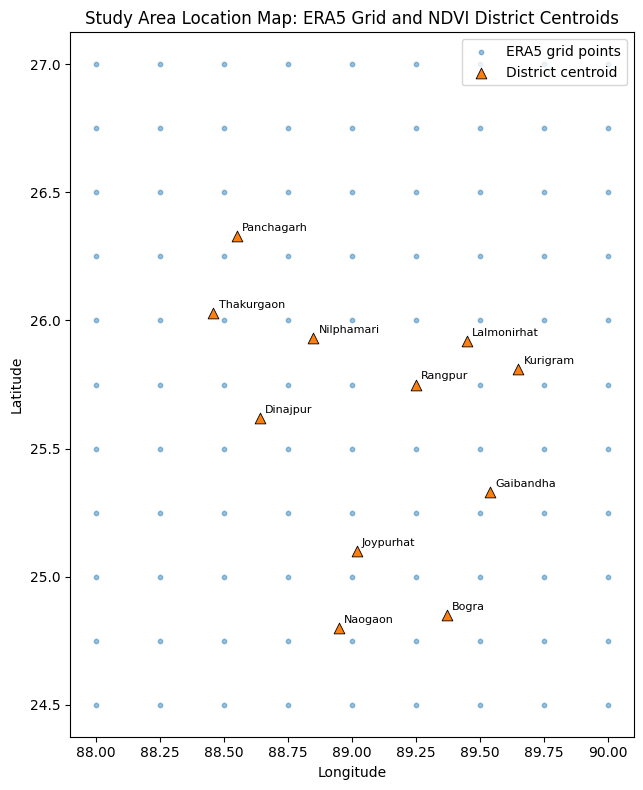

Saved figure: outputs_ndvi_era5_stress/figures/01a_location_map_era5_grid_districts.png at 500 dpi


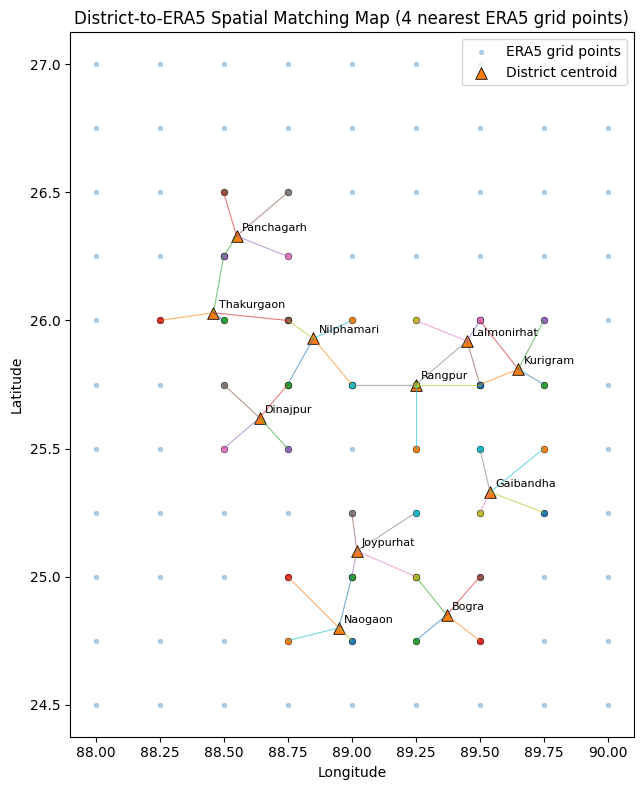

Saved figure: outputs_ndvi_era5_stress/figures/01b_location_map_idw_links.png at 500 dpi
Saved interactive location map: outputs_ndvi_era5_stress/figures/01c_interactive_location_map_era5_grid_districts.html
District-daily ERA5 table: (12573, 14)
ERA5 rolling feature table: (12573, 150)
Added 12 SPI/SPEI/ZSI-style drought features.
Climate match rate: 1.0
Fused table before targets: (759, 188)
Final modelling dataset: (759, 194)
Three-level stress distribution:
stress_level_label
normal_good        479
high_stress        166
moderate_stress    114
Name: count, dtype: int64


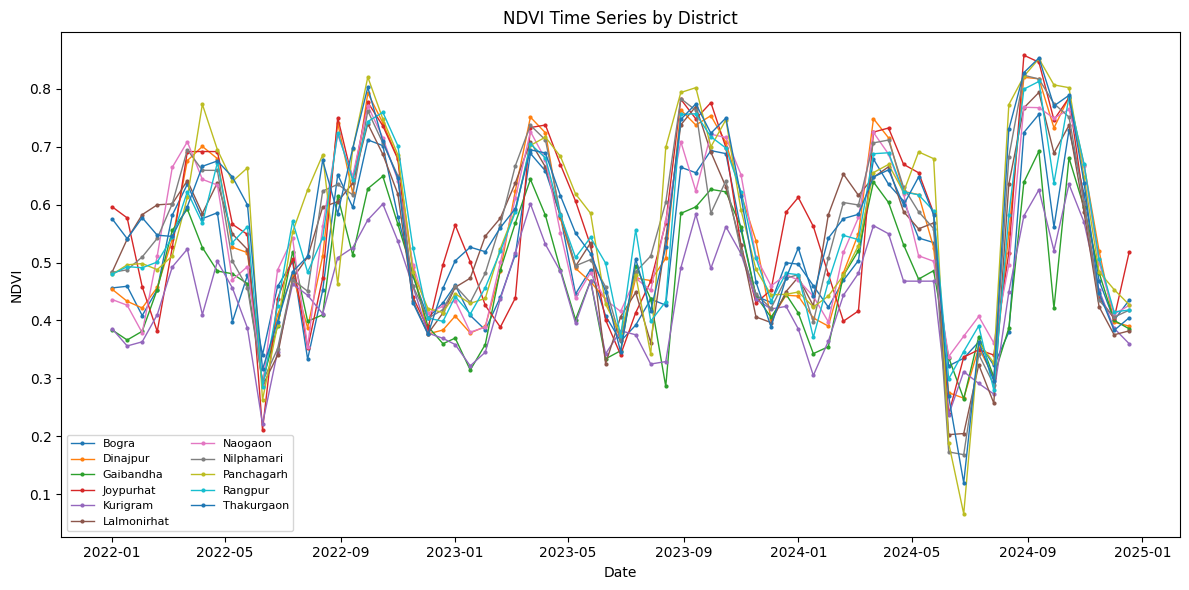

Saved figure: outputs_ndvi_era5_stress/figures/01_ndvi_time_series_by_district.png at 500 dpi


<Figure size 1000x500 with 0 Axes>

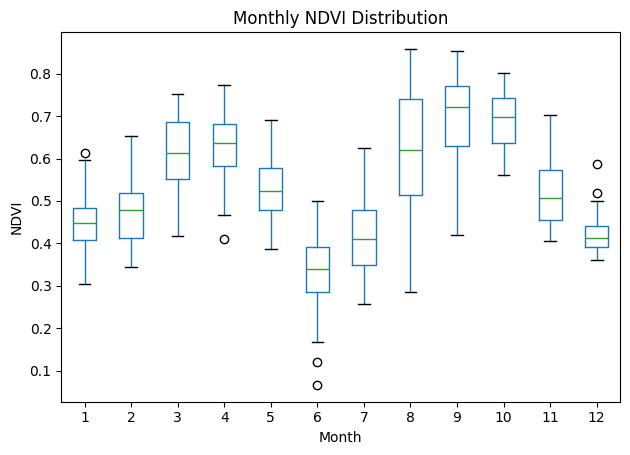

Saved figure: outputs_ndvi_era5_stress/figures/02_monthly_ndvi_distribution.png at 500 dpi


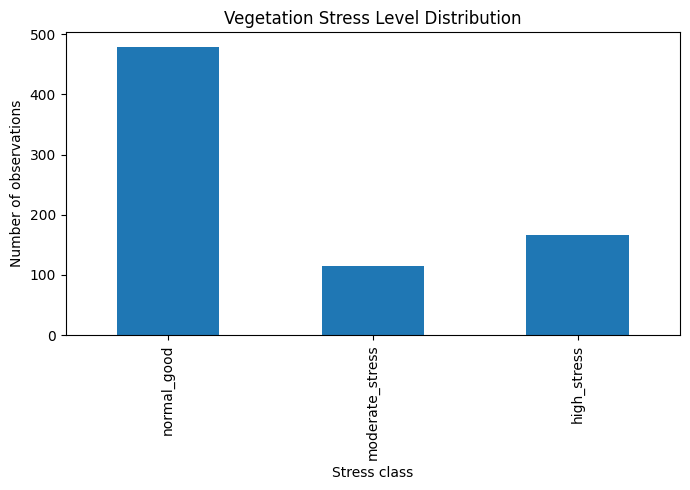

Saved figure: outputs_ndvi_era5_stress/figures/03_stress_level_distribution.png at 500 dpi


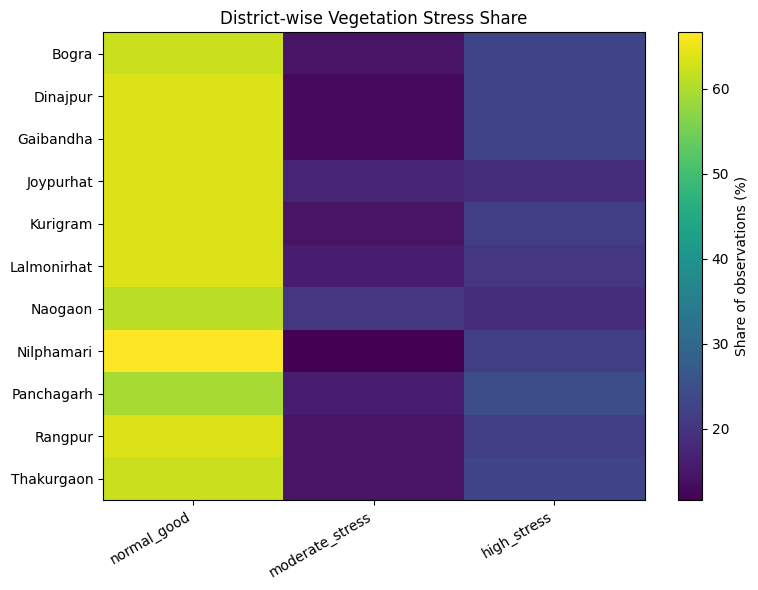

Saved figure: outputs_ndvi_era5_stress/figures/04_district_stress_share.png at 500 dpi


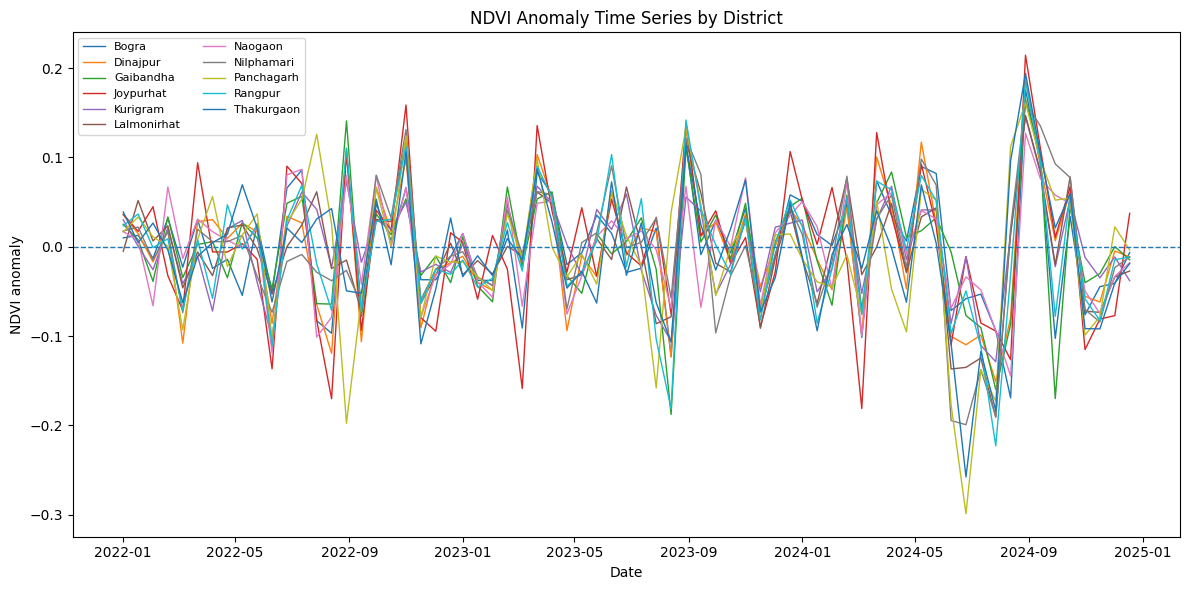

Saved figure: outputs_ndvi_era5_stress/figures/05_ndvi_anomaly_time_series.png at 500 dpi


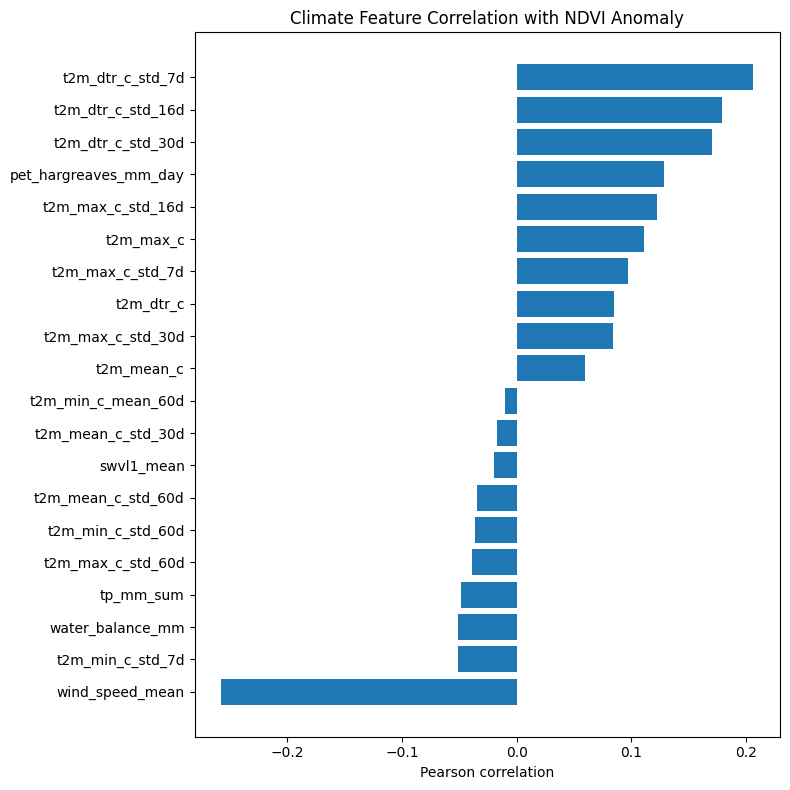

Saved figure: outputs_ndvi_era5_stress/figures/06_climate_feature_correlation_with_ndvi_anomaly.png at 500 dpi


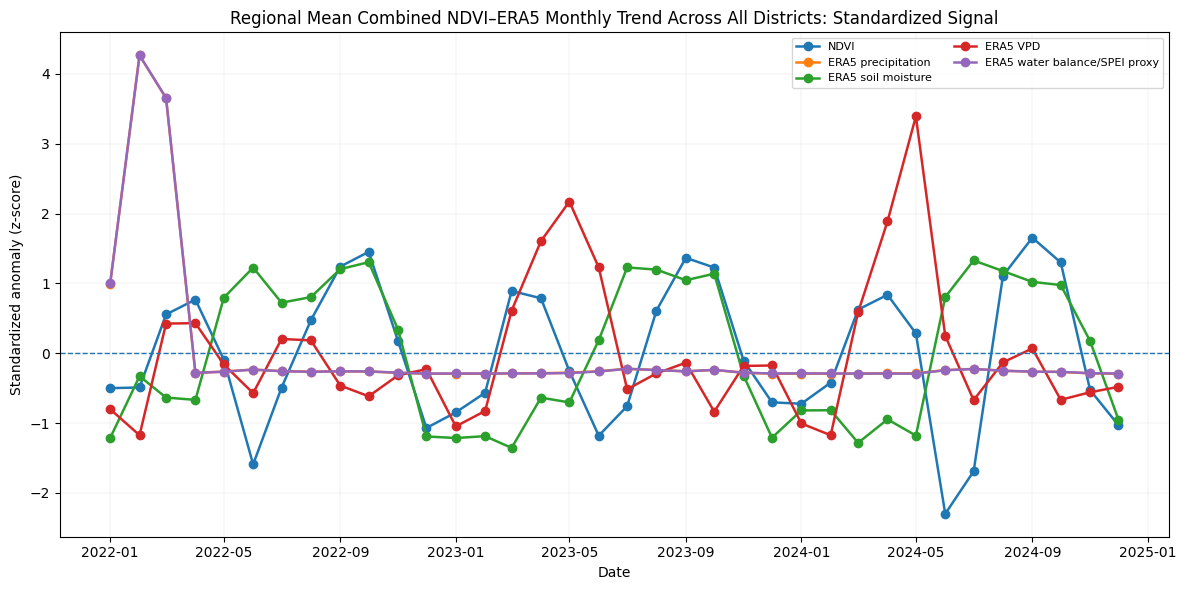

Saved figure: outputs_ndvi_era5_stress/figures/08_combined_ndvi_era5_standardized_trend.png at 500 dpi


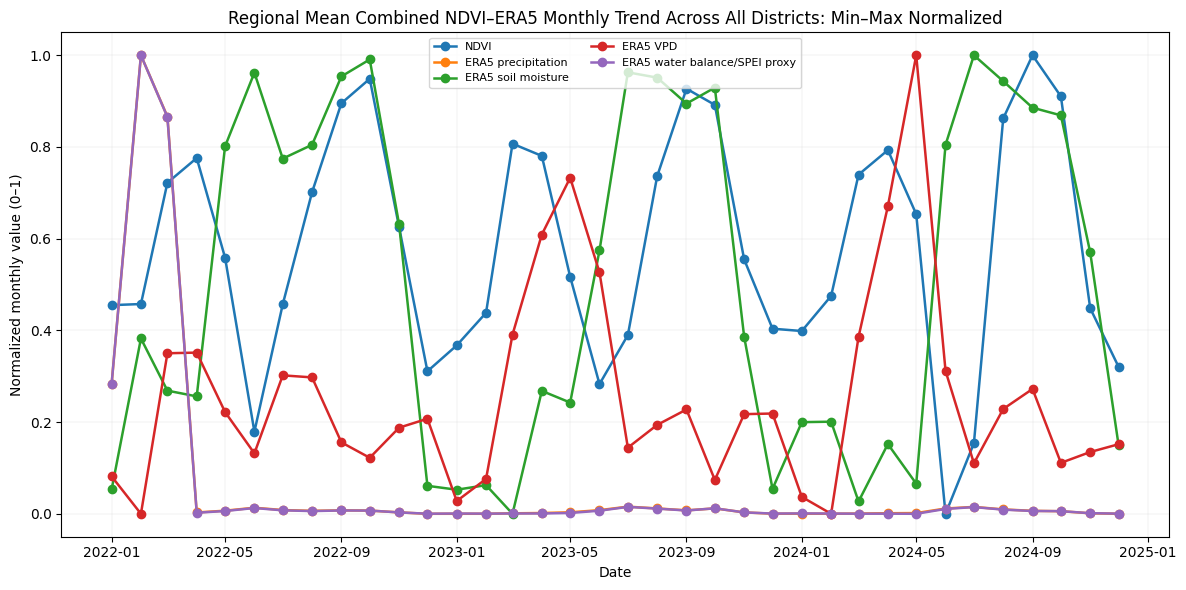

Saved figure: outputs_ndvi_era5_stress/figures/08b_combined_ndvi_era5_minmax_normalized_trend.png at 500 dpi


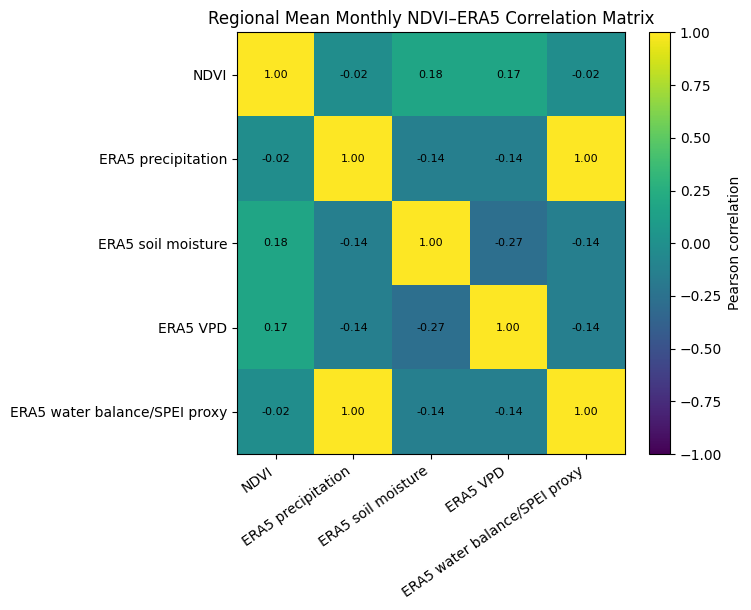

Saved figure: outputs_ndvi_era5_stress/figures/08c_combined_ndvi_era5_correlation_matrix.png at 500 dpi


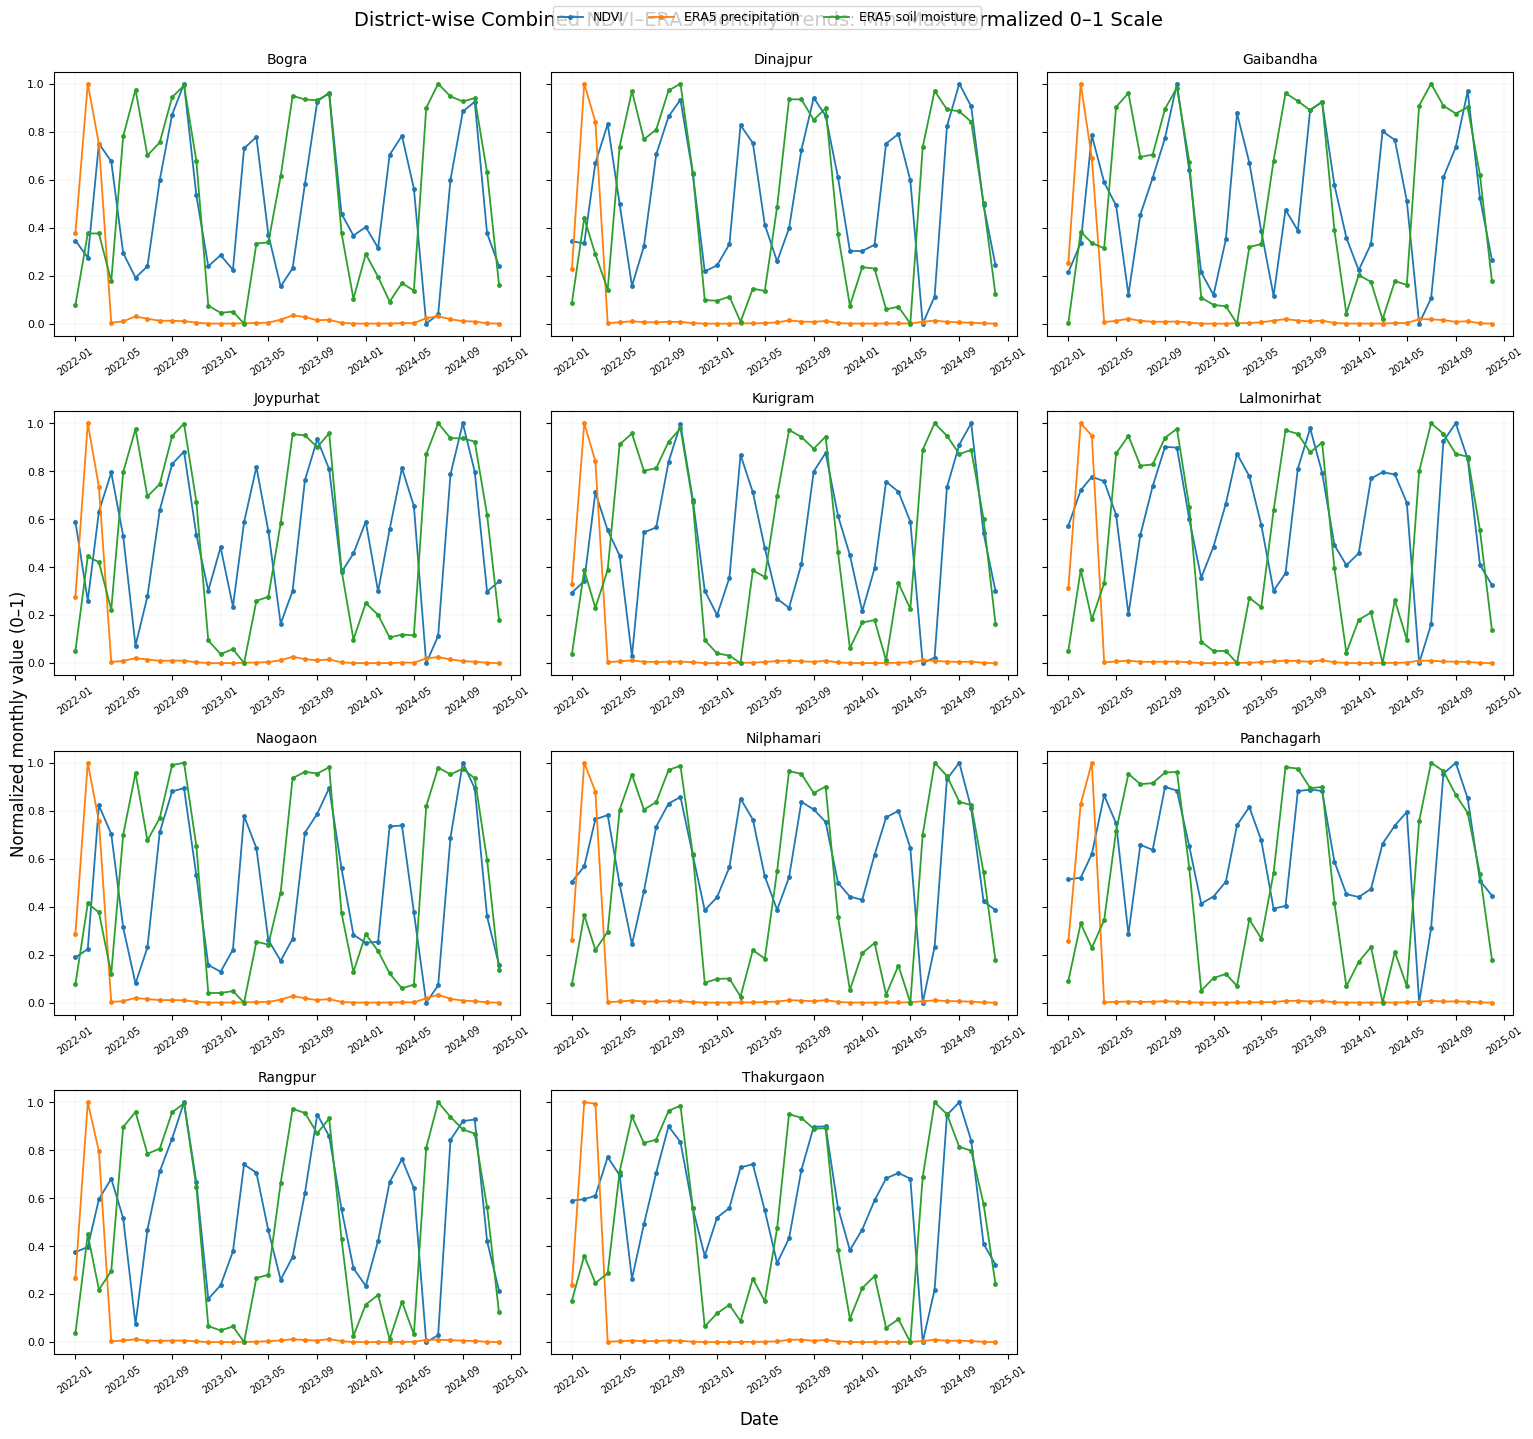

Saved figure: outputs_ndvi_era5_stress/figures/08d_districtwise_combined_ndvi_era5_minmax_small_multiples.png at 500 dpi


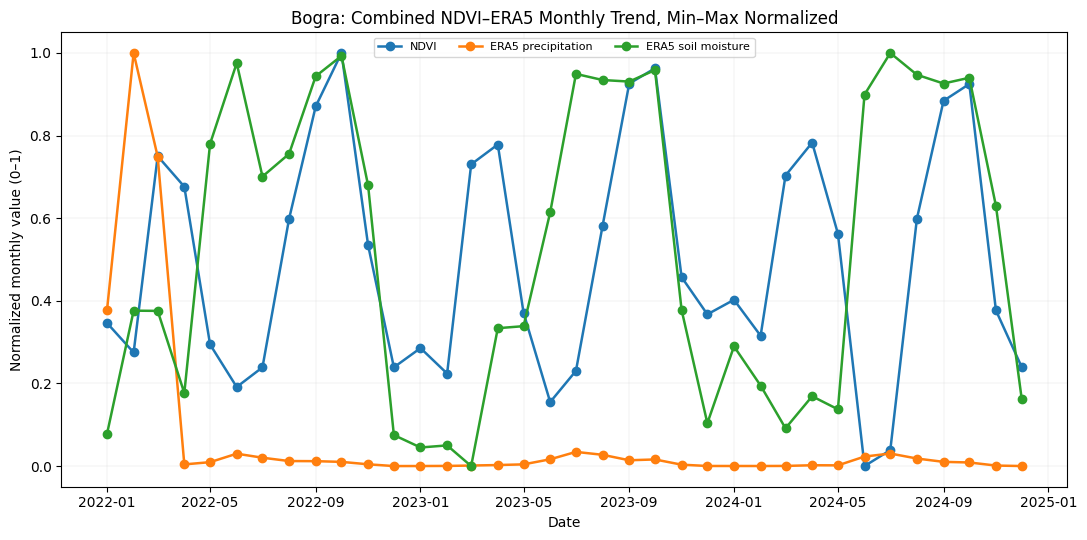

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_bogra_combined_ndvi_era5_minmax.png at 500 dpi


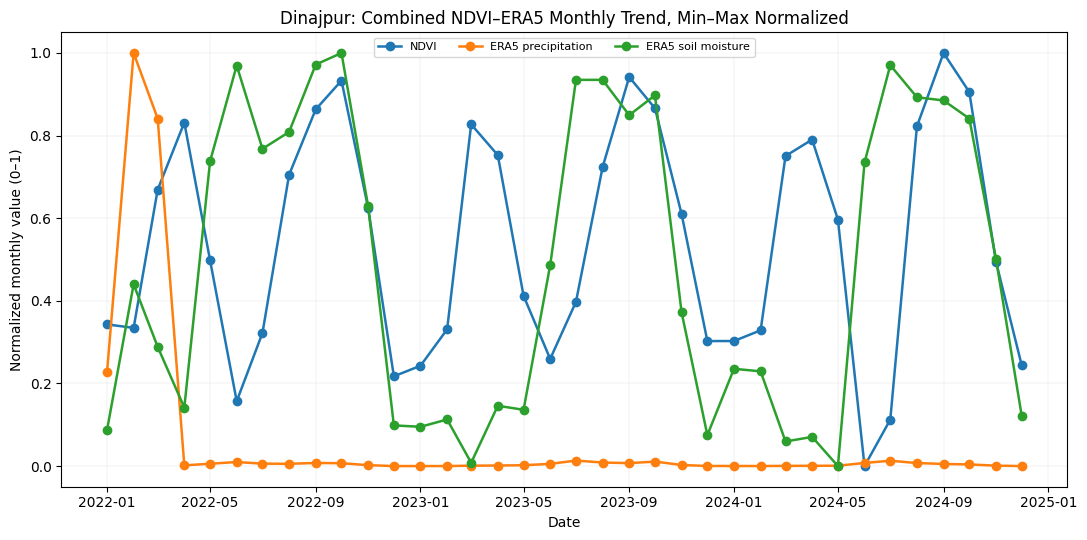

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_dinajpur_combined_ndvi_era5_minmax.png at 500 dpi


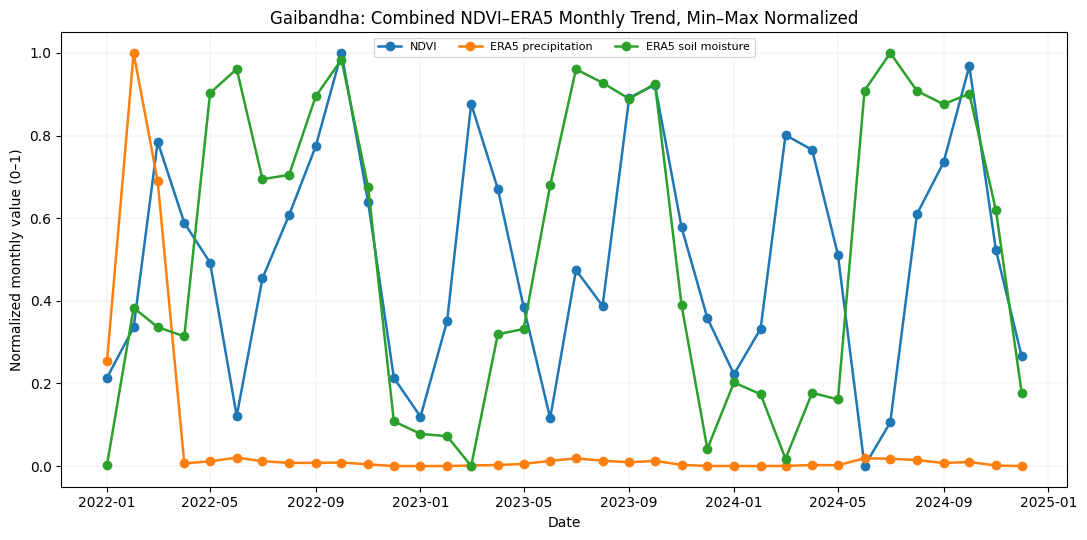

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_gaibandha_combined_ndvi_era5_minmax.png at 500 dpi


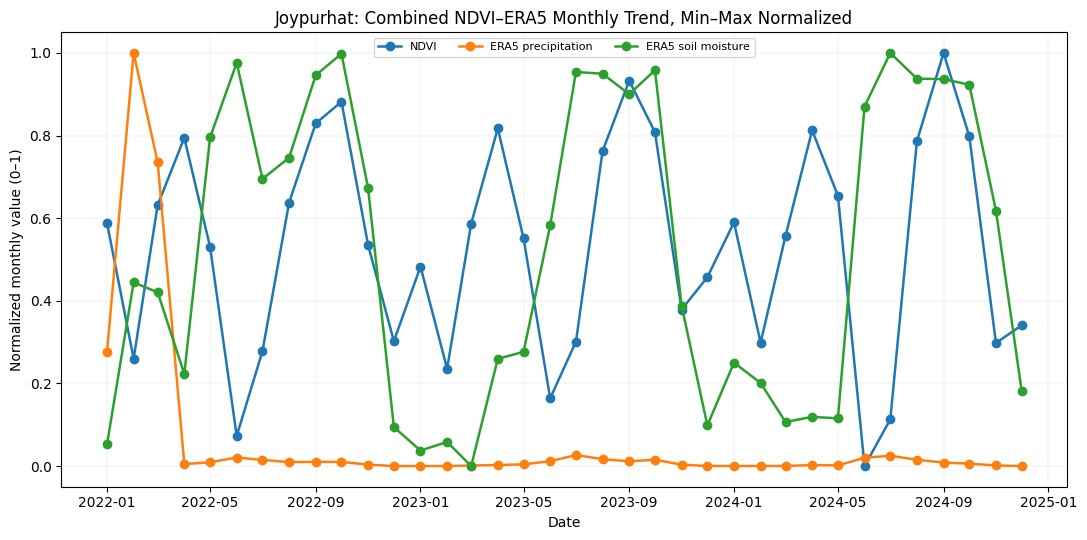

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_joypurhat_combined_ndvi_era5_minmax.png at 500 dpi


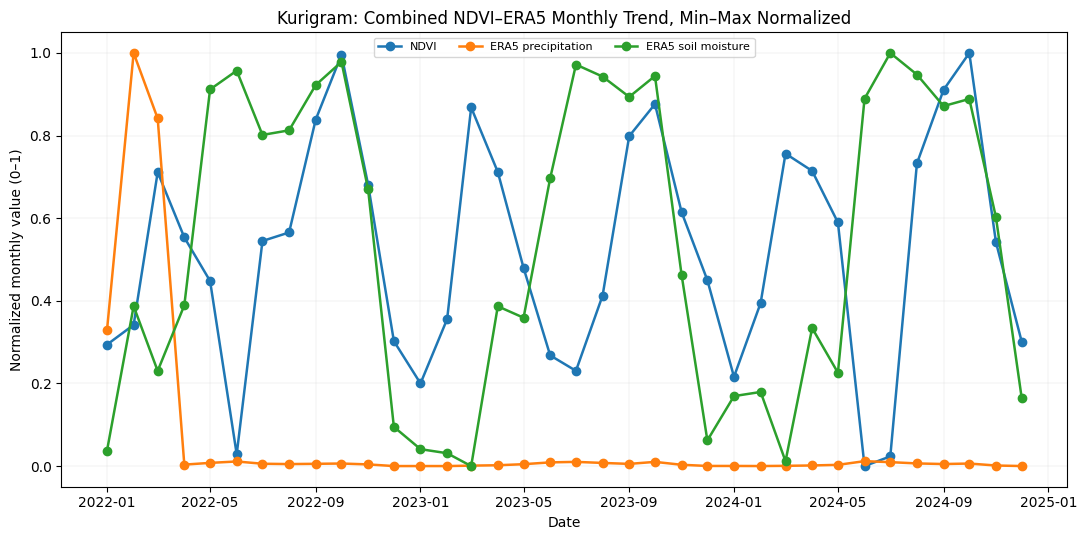

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_kurigram_combined_ndvi_era5_minmax.png at 500 dpi


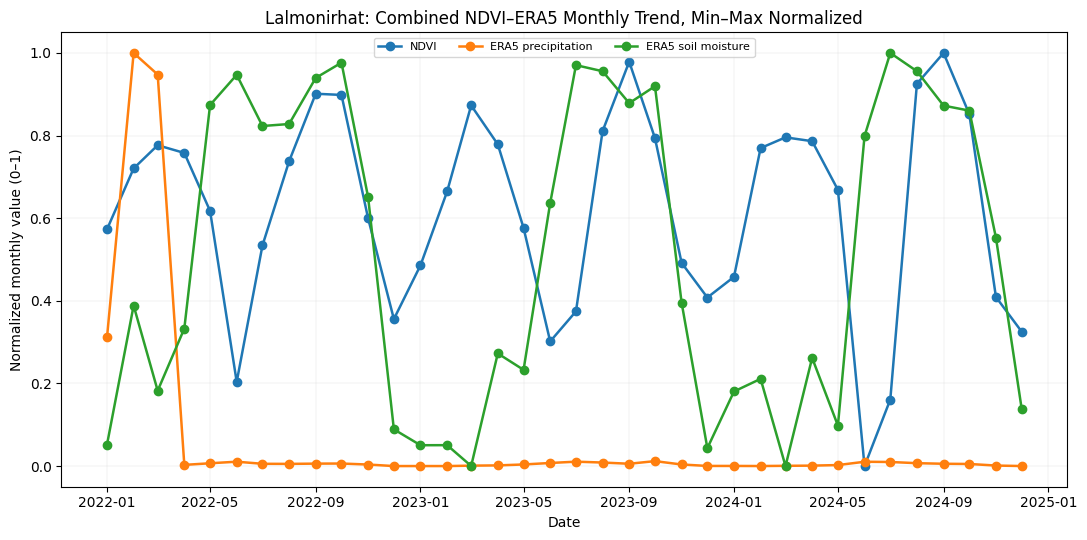

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_lalmonirhat_combined_ndvi_era5_minmax.png at 500 dpi


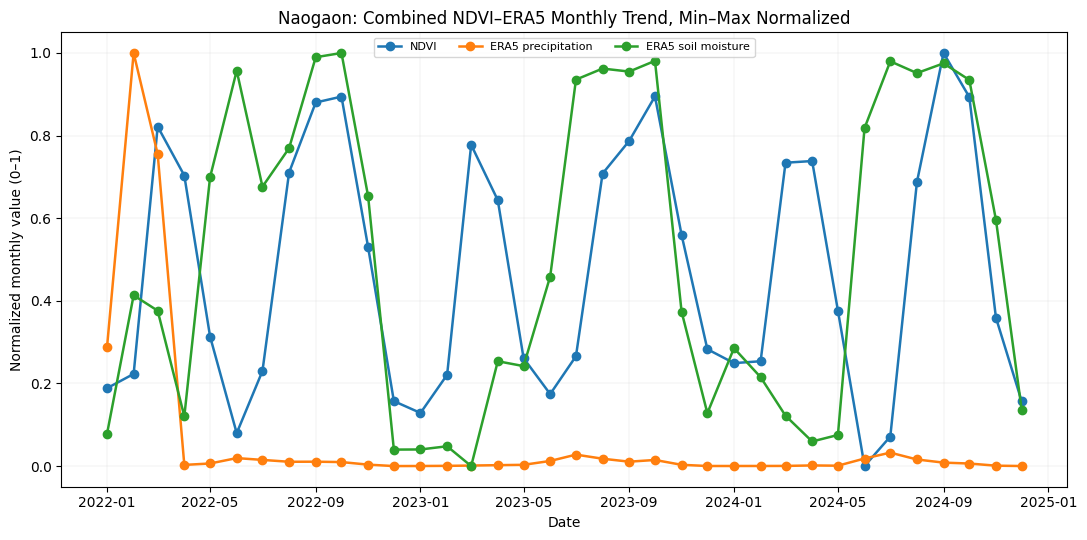

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_naogaon_combined_ndvi_era5_minmax.png at 500 dpi


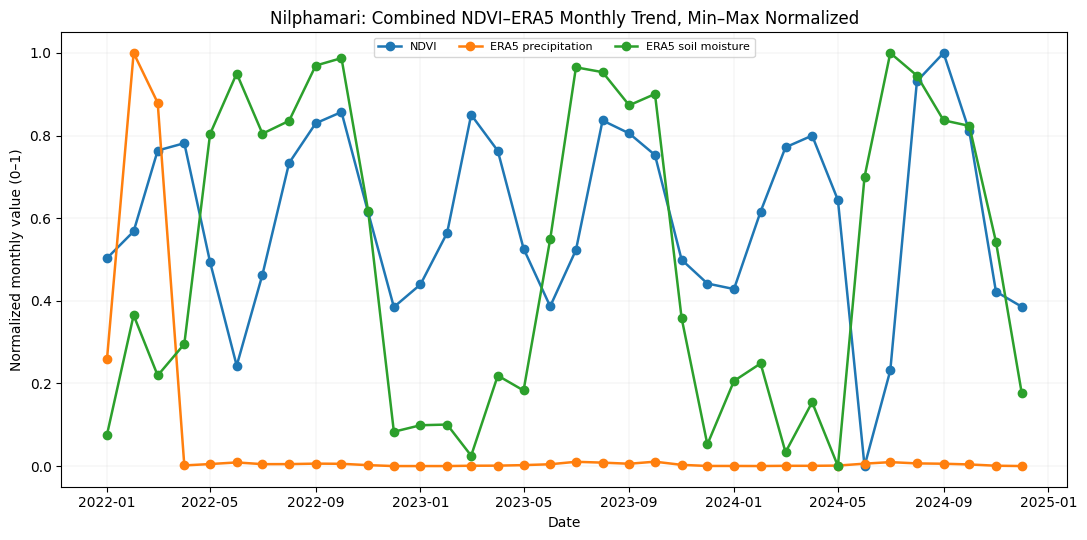

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_nilphamari_combined_ndvi_era5_minmax.png at 500 dpi


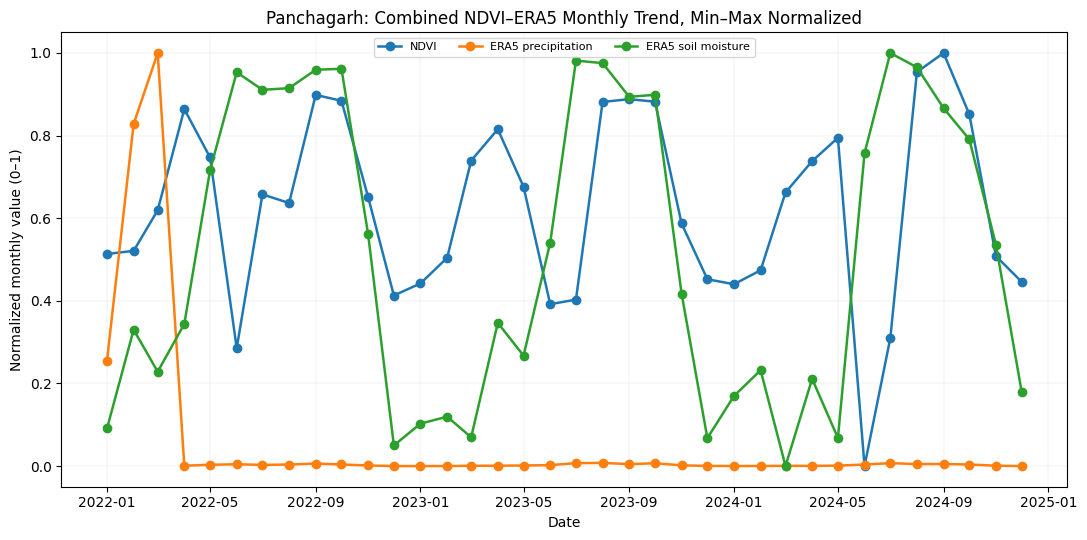

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_panchagarh_combined_ndvi_era5_minmax.png at 500 dpi


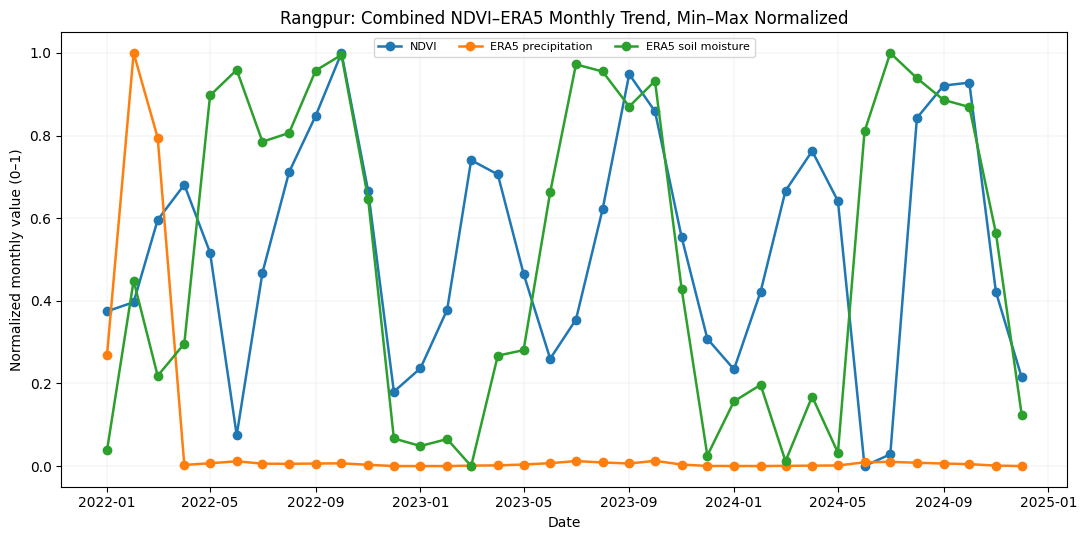

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_rangpur_combined_ndvi_era5_minmax.png at 500 dpi


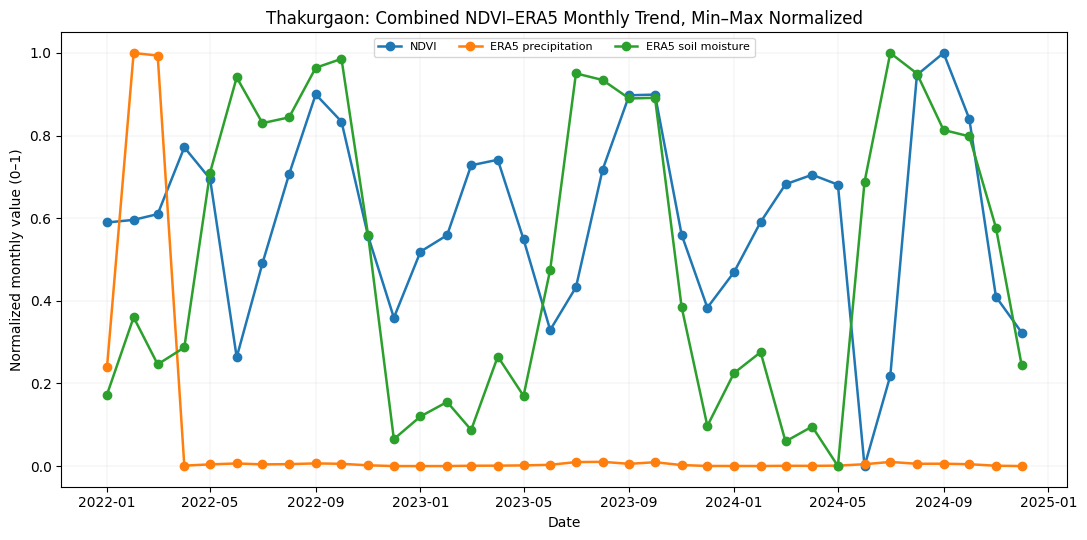

Saved figure: outputs_ndvi_era5_stress/figures/districtwise_combined_ndvi_era5/08e_thakurgaon_combined_ndvi_era5_minmax.png at 500 dpi


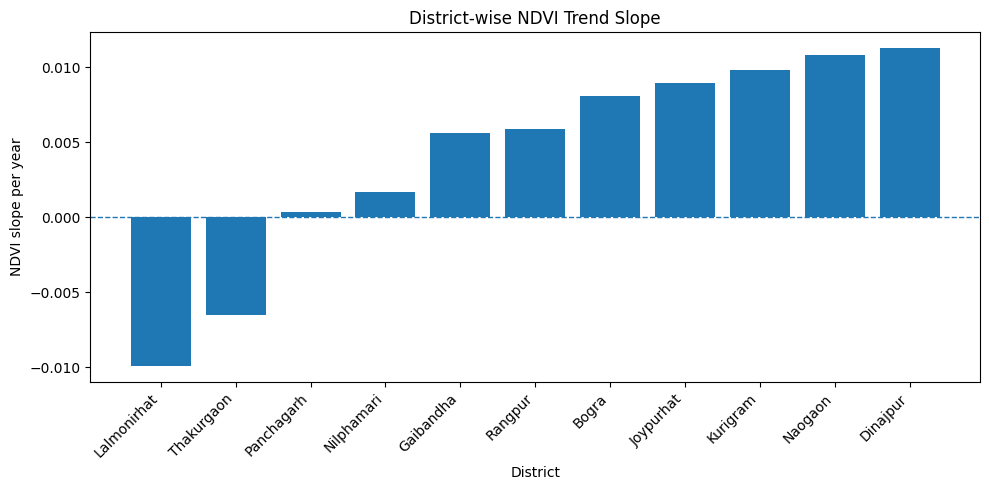

Saved figure: outputs_ndvi_era5_stress/figures/07_district_ndvi_trend_slope.png at 500 dpi


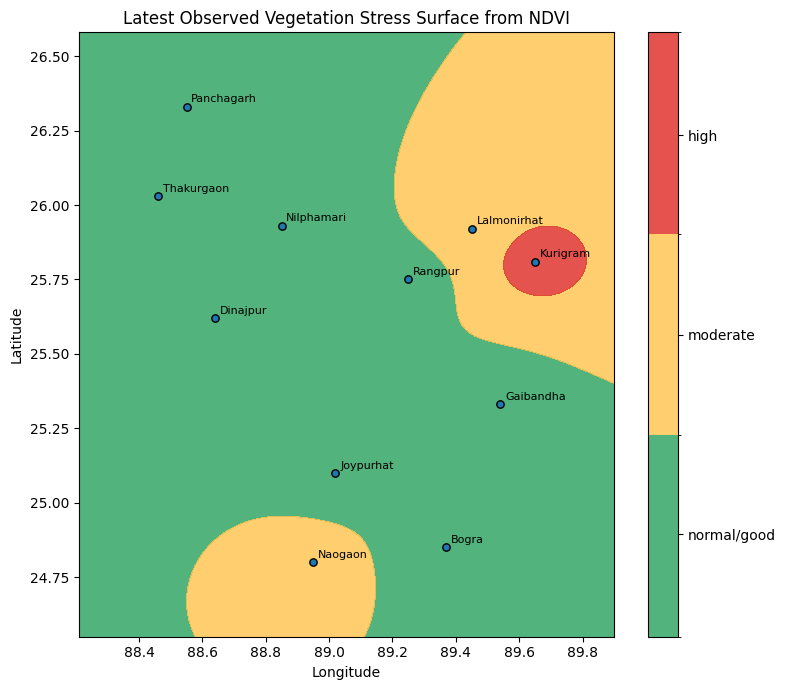

Saved figure: outputs_ndvi_era5_stress/figures/14_latest_observed_stress_surface.png at 500 dpi


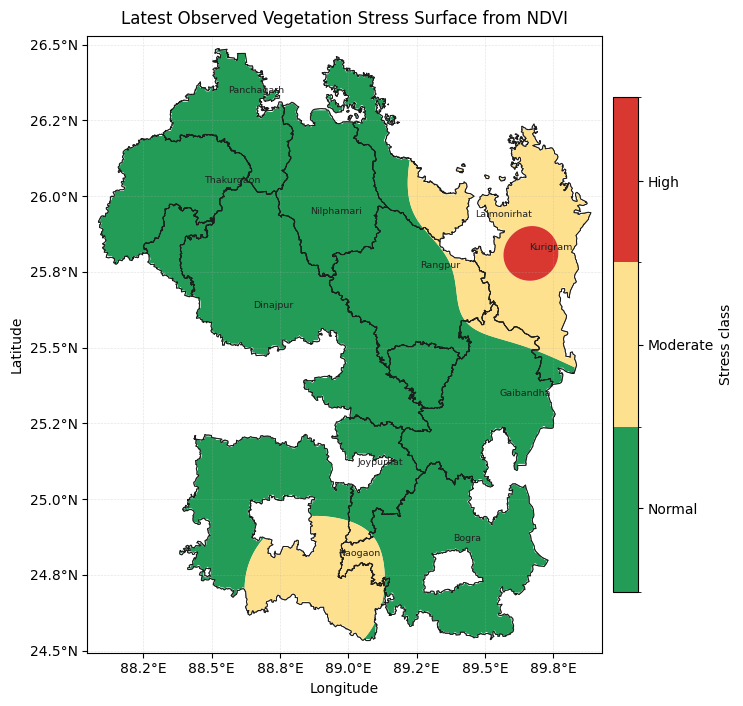

Saved figure: outputs_ndvi_era5_stress/figures/14b_latest_observed_stress_geojson_clipped_surface.png at 500 dpi


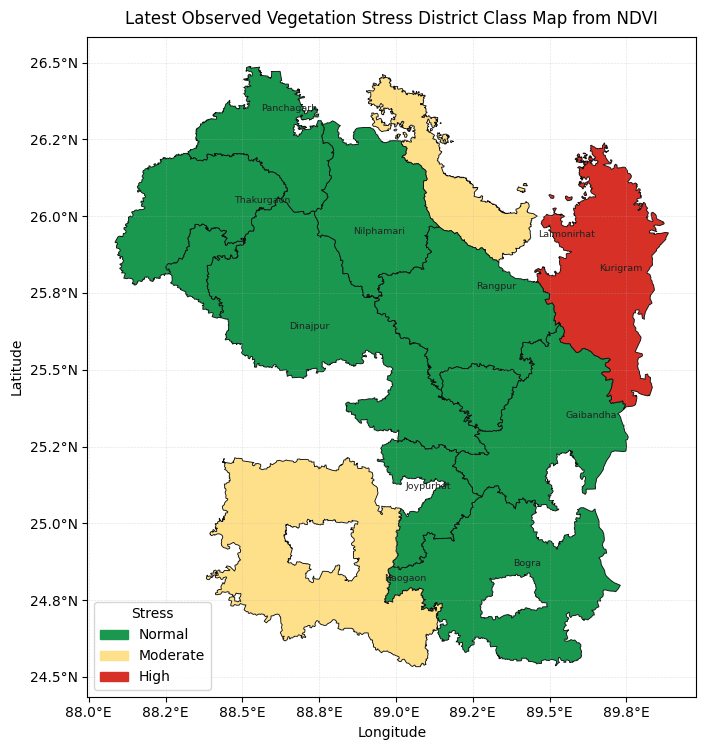

Saved figure: outputs_ndvi_era5_stress/figures/14b_latest_observed_stress_geojson_district_polygons.png at 500 dpi


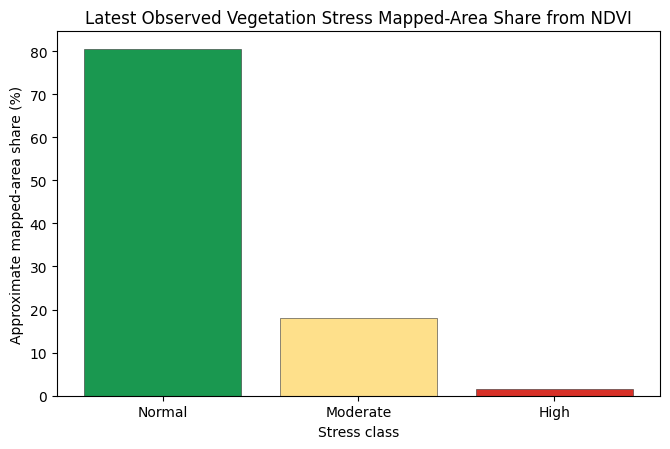

Saved figure: outputs_ndvi_era5_stress/figures/14b_latest_observed_stress_geojson_area_share.png at 500 dpi


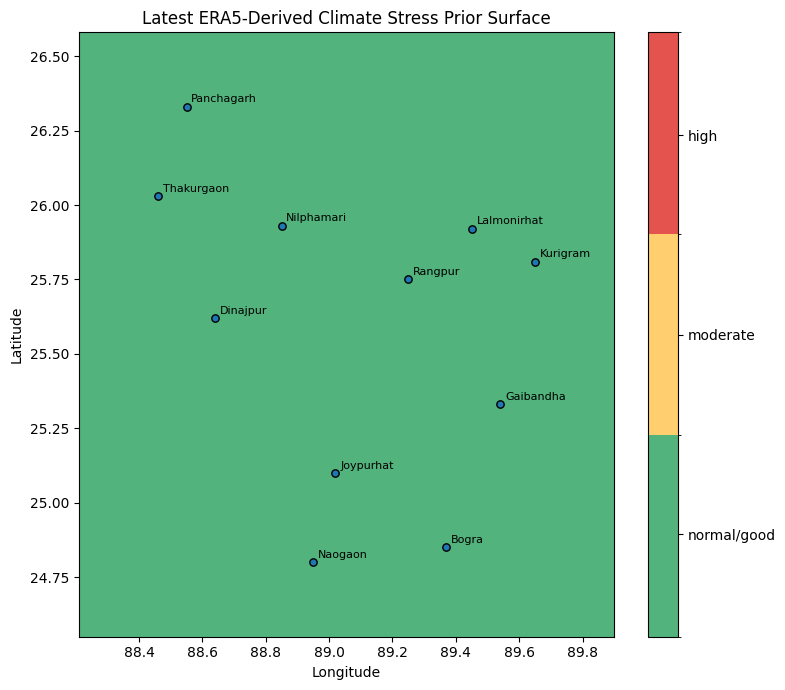

Saved figure: outputs_ndvi_era5_stress/figures/15_latest_era5_climate_stress_prior_surface.png at 500 dpi


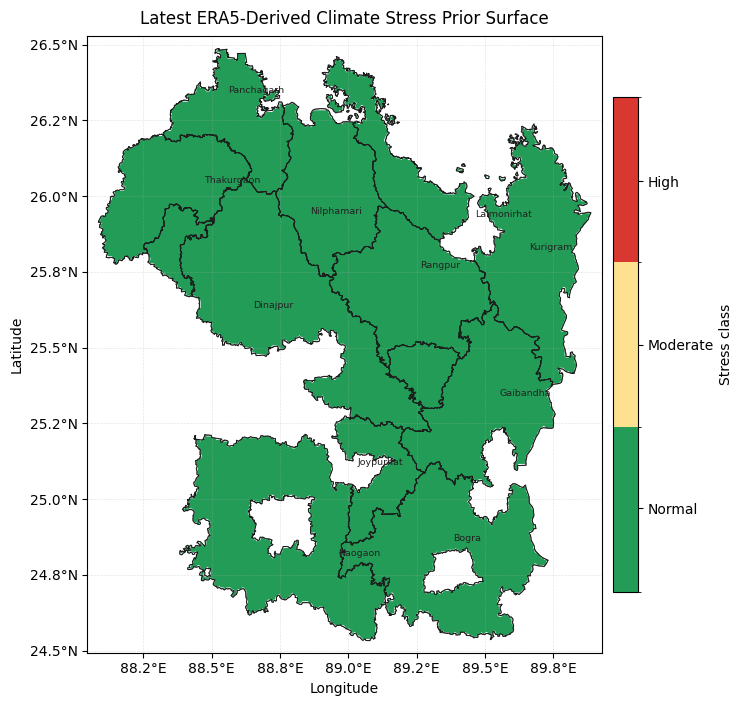

Saved figure: outputs_ndvi_era5_stress/figures/15b_latest_era5_climate_stress_prior_geojson_clipped_surface.png at 500 dpi


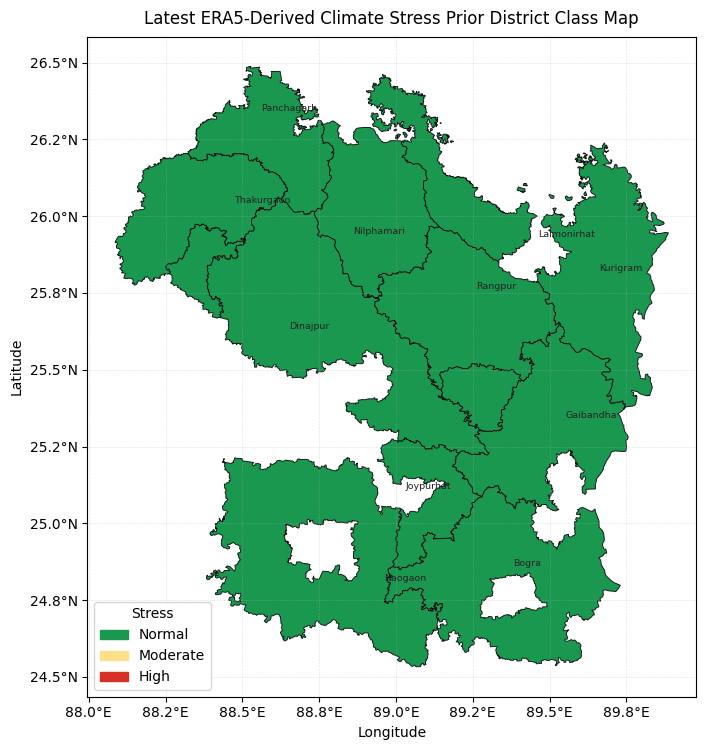

Saved figure: outputs_ndvi_era5_stress/figures/15b_latest_era5_climate_stress_prior_geojson_district_polygons.png at 500 dpi


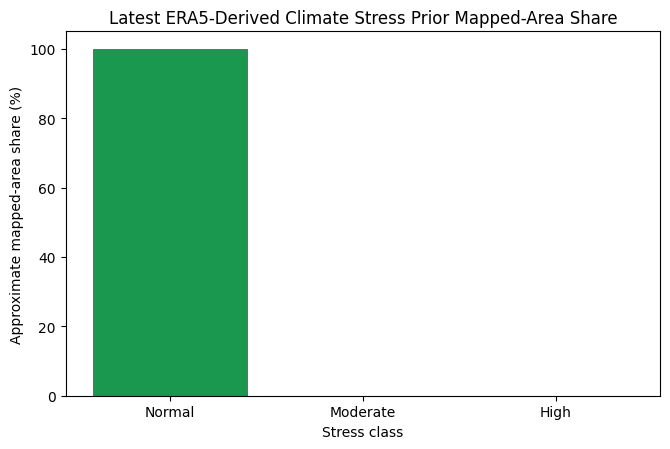

Saved figure: outputs_ndvi_era5_stress/figures/15b_latest_era5_climate_stress_prior_geojson_area_share.png at 500 dpi


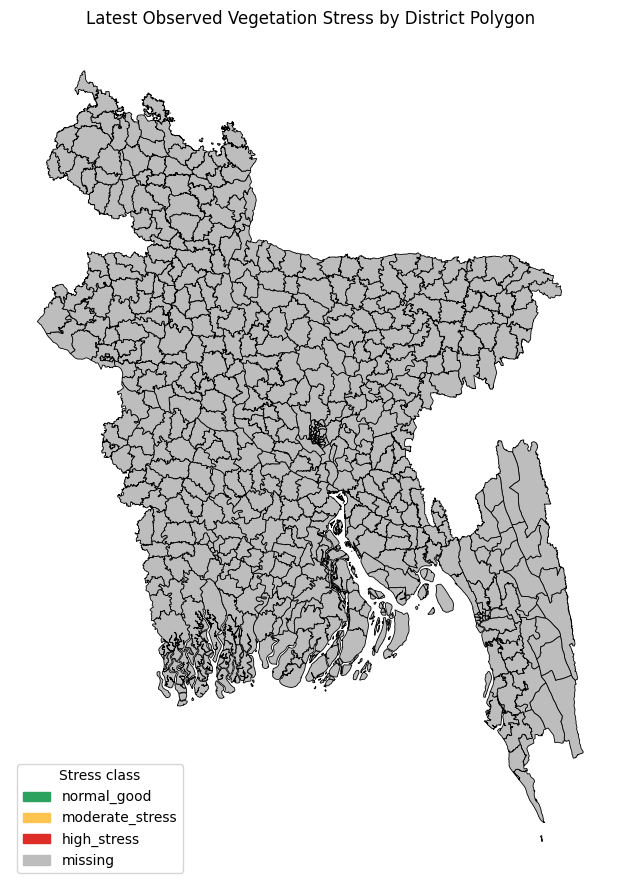

Saved figure: outputs_ndvi_era5_stress/figures/19_polygon_latest_observed_stress_map.png at 500 dpi


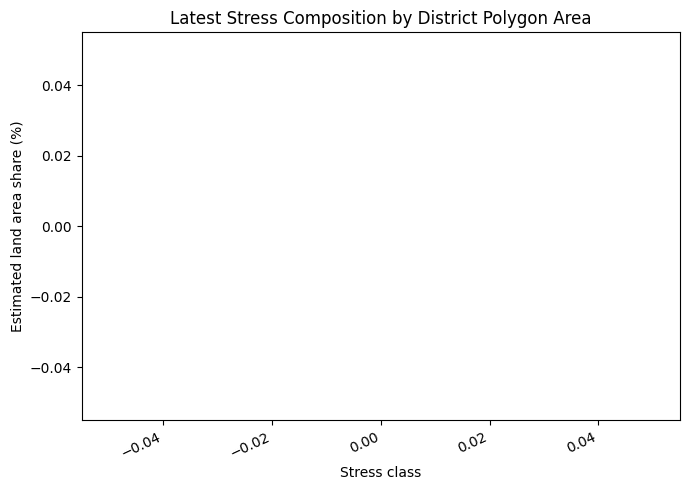

Saved figure: outputs_ndvi_era5_stress/figures/20_land_area_stress_share_latest_observed.png at 500 dpi


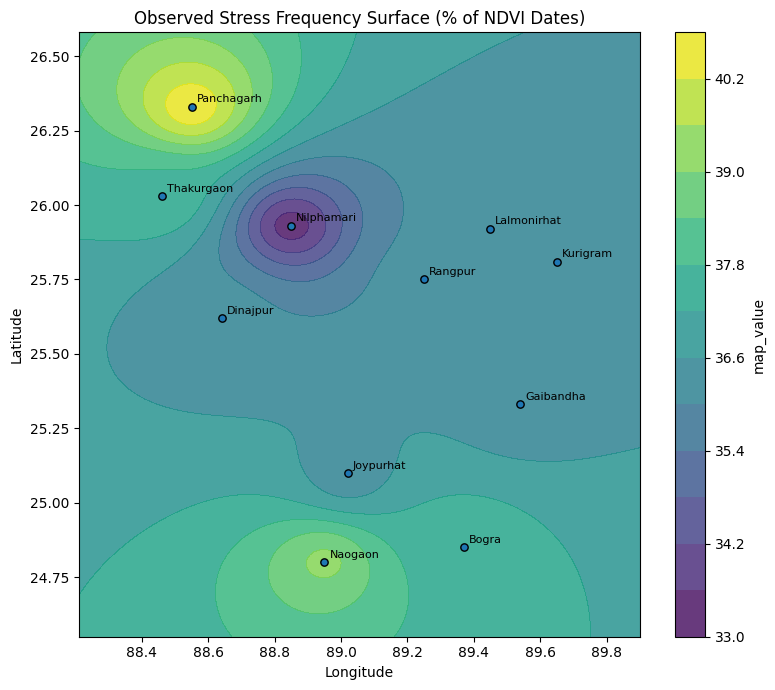

Saved figure: outputs_ndvi_era5_stress/figures/16_observed_stress_frequency_surface.png at 500 dpi


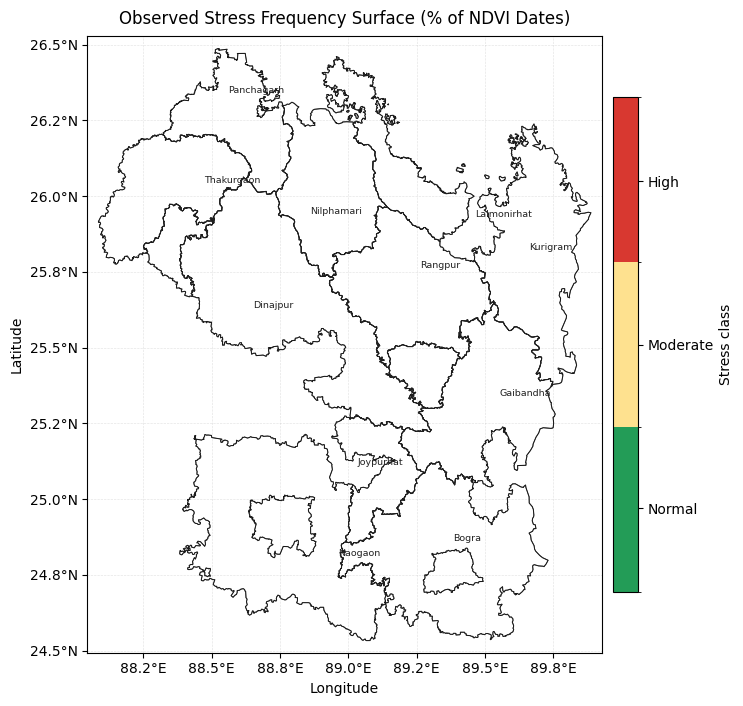

Saved figure: outputs_ndvi_era5_stress/figures/16b_observed_stress_frequency_geojson_clipped_surface.png at 500 dpi


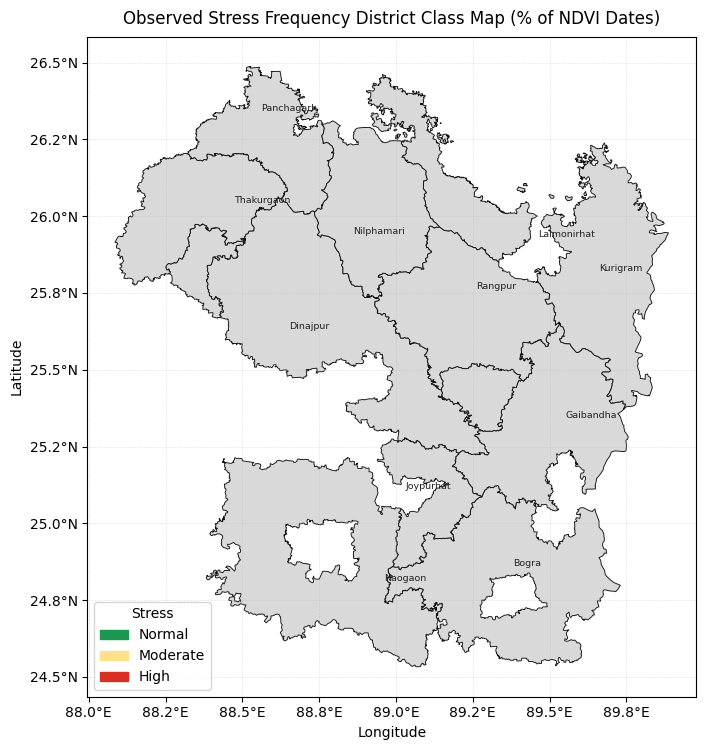

Saved figure: outputs_ndvi_era5_stress/figures/16b_observed_stress_frequency_geojson_district_polygons.png at 500 dpi


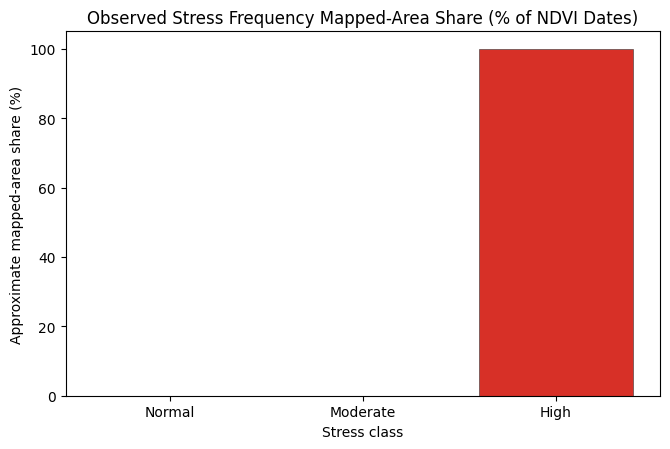

Saved figure: outputs_ndvi_era5_stress/figures/16b_observed_stress_frequency_geojson_area_share.png at 500 dpi


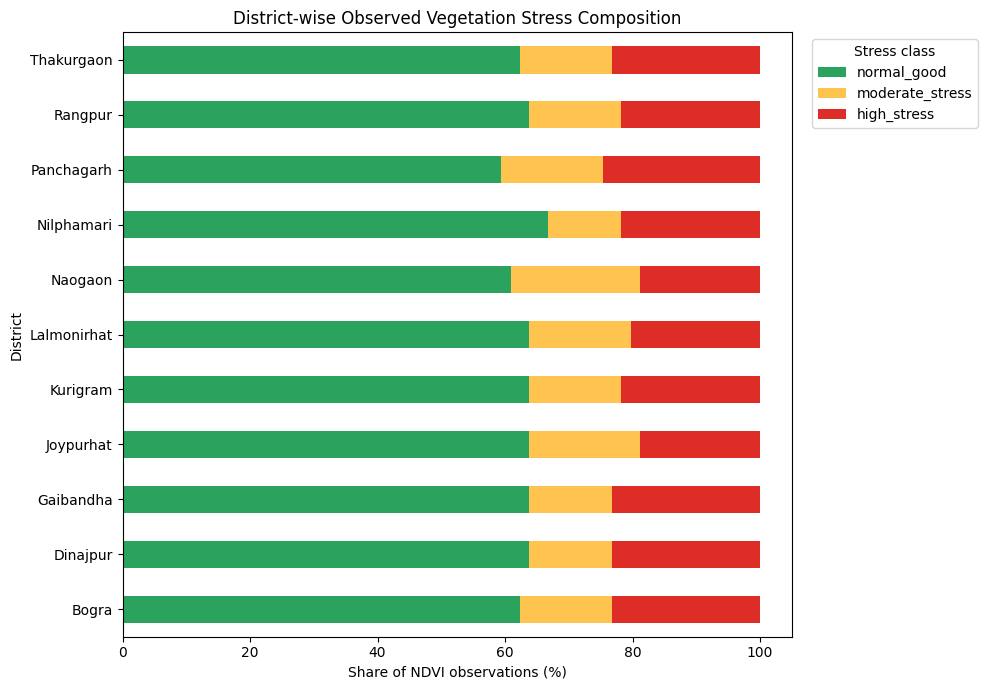

Saved figure: outputs_ndvi_era5_stress/figures/17_district_stress_composition_stacked_bar.png at 500 dpi

District trends:
       district  ndvi_slope_per_year  mean_ndvi  mean_ndvi_anomaly  \
5   Lalmonirhat            -0.009911   0.535965          -0.006046   
10   Thakurgaon            -0.006536   0.560925          -0.007219   
8    Panchagarh             0.000345   0.562677          -0.009030   
7    Nilphamari             0.001669   0.544822          -0.003705   
2     Gaibandha             0.005645   0.471855          -0.003000   
9       Rangpur             0.005861   0.549164          -0.003747   
0         Bogra             0.008081   0.509541          -0.001655   
3     Joypurhat             0.008936   0.553914          -0.001209   
4      Kurigram             0.009781   0.441206          -0.000495   
6       Naogaon             0.010802   0.540792          -0.001234   
1      Dinajpur             0.011264   0.539014          -0.002539   

    stress_rate_percent  
5         

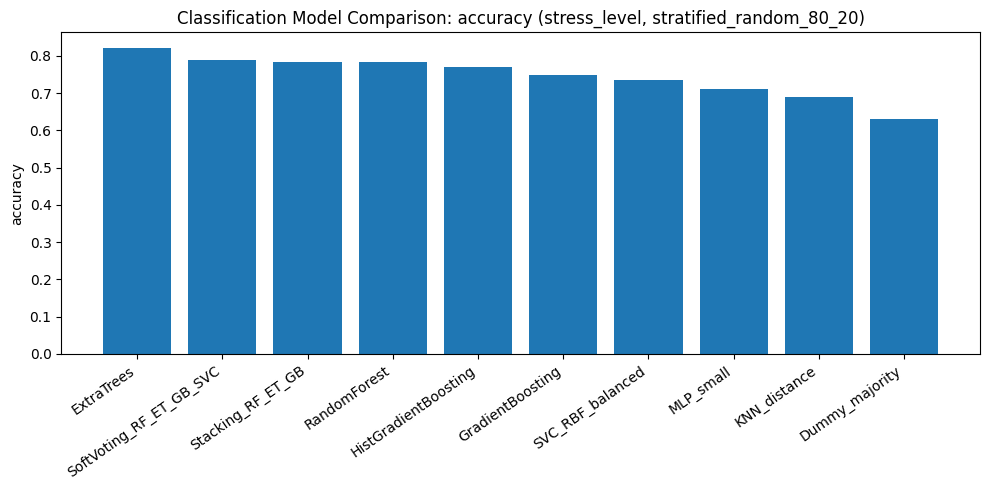

Saved figure: outputs_ndvi_era5_stress/figures/08_model_comparison_accuracy_stress_level_stratified_random_80_20_oversample.png at 500 dpi


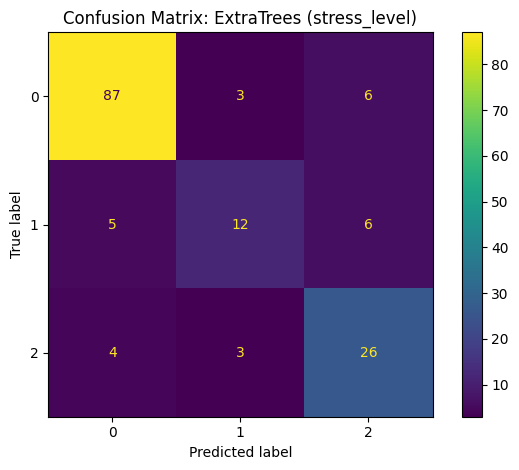

Saved figure: outputs_ndvi_era5_stress/figures/09_confusion_matrix_stress_level_stratified_random_80_20_oversample.png at 500 dpi


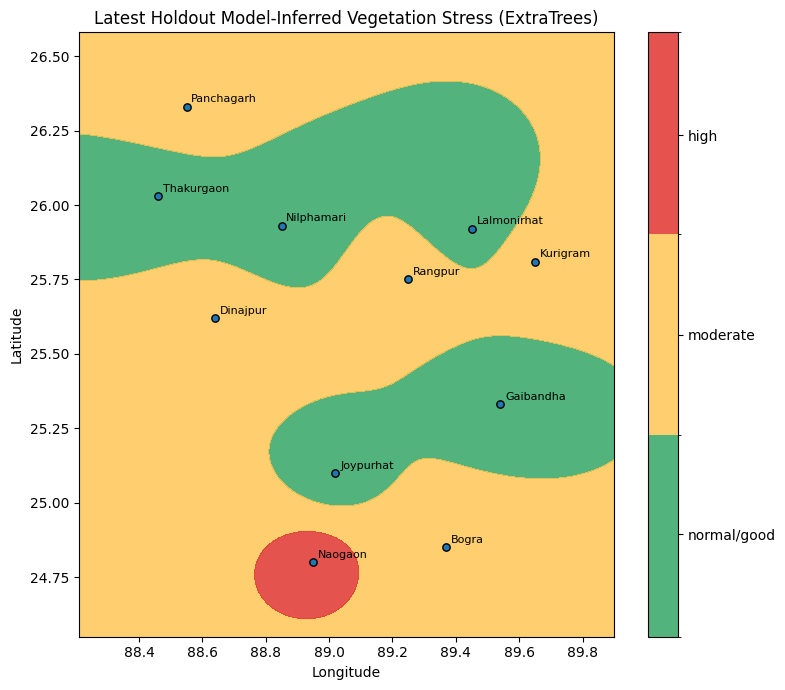

Saved figure: outputs_ndvi_era5_stress/figures/18_latest_predicted_stress_surface_stratified_random_80_20_oversample.png at 500 dpi


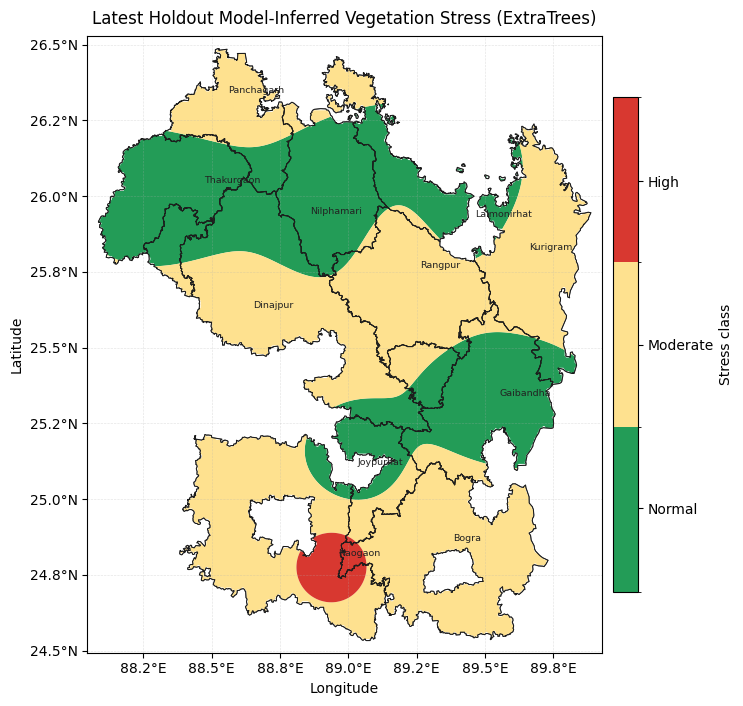

Saved figure: outputs_ndvi_era5_stress/figures/18b_latest_predicted_stress_stratified_random_80_20_oversample_geojson_clipped_surface.png at 500 dpi


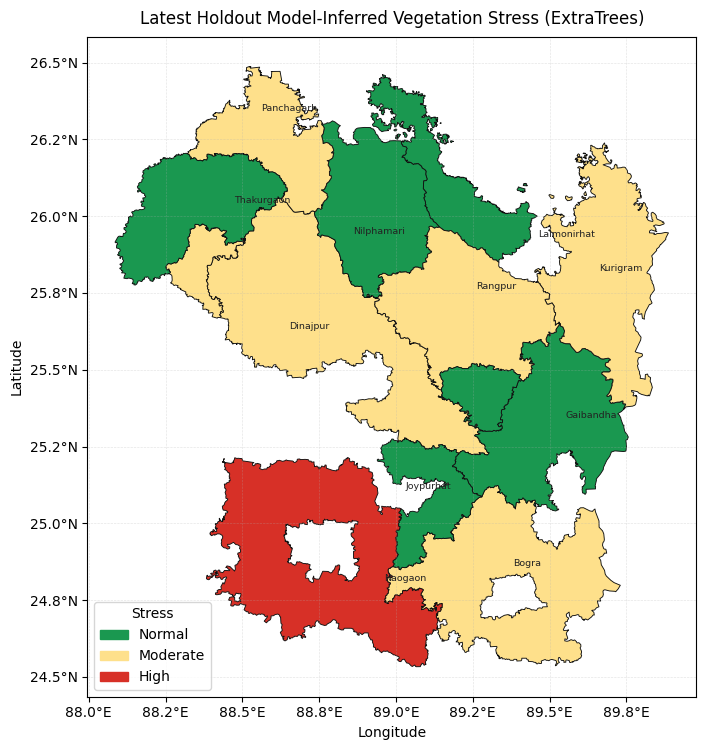

Saved figure: outputs_ndvi_era5_stress/figures/18b_latest_predicted_stress_stratified_random_80_20_oversample_geojson_district_polygons.png at 500 dpi


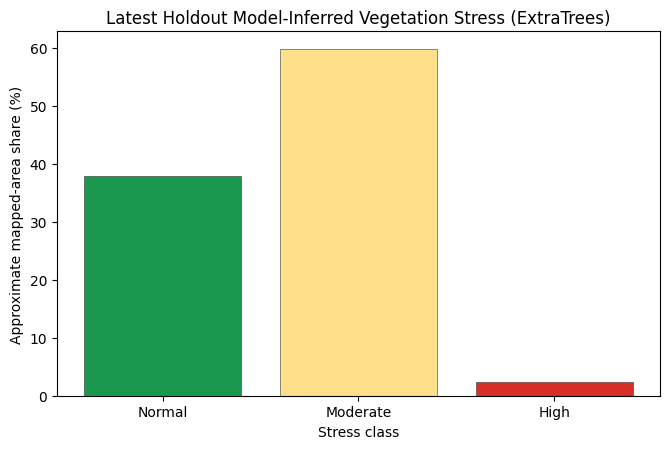

Saved figure: outputs_ndvi_era5_stress/figures/18b_latest_predicted_stress_stratified_random_80_20_oversample_geojson_area_share.png at 500 dpi


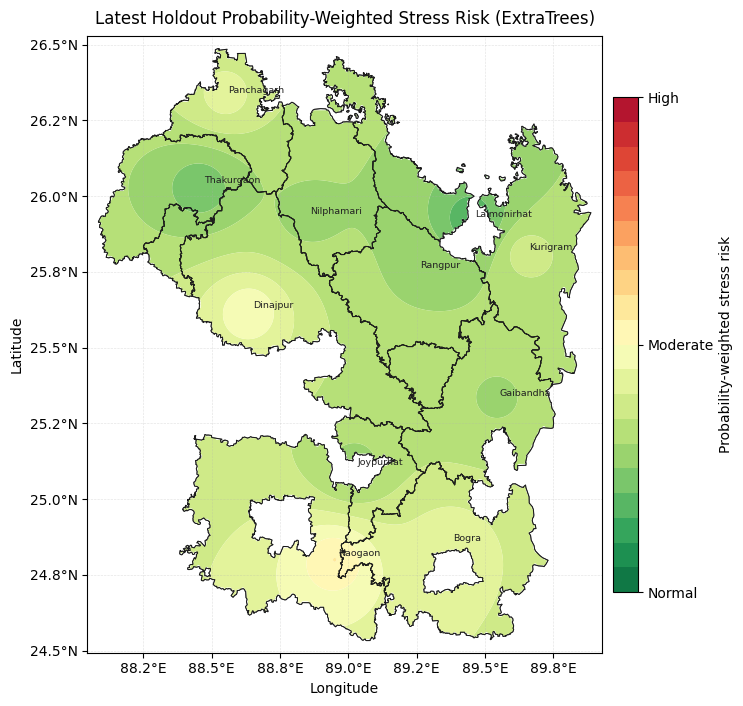

Saved figure: outputs_ndvi_era5_stress/figures/18c_latest_predicted_probability_risk_stratified_random_80_20_oversample_continuous_risk_surface.png at 500 dpi


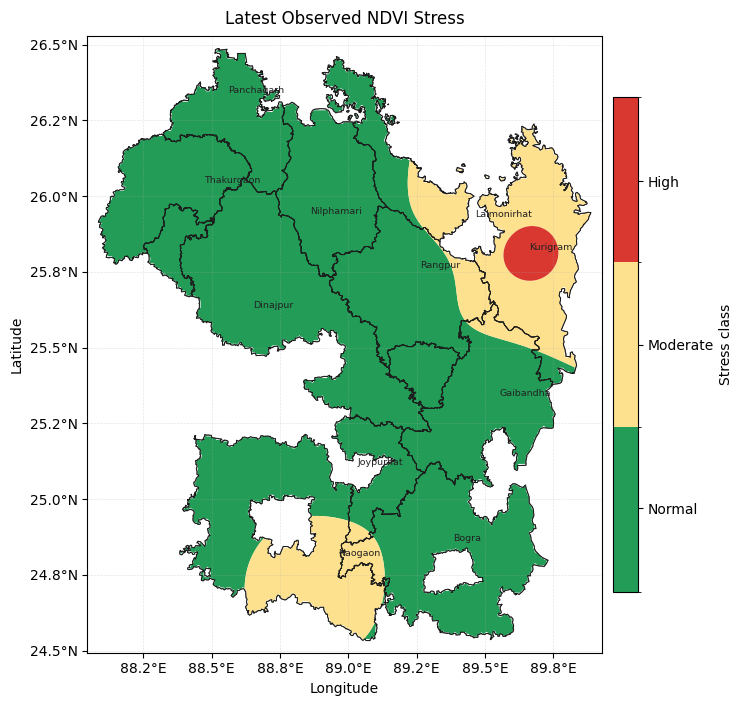

Saved figure: outputs_ndvi_era5_stress/figures/21a_paper_latest_observed_same_records_stratified_random_80_20_oversample_geojson_clipped_surface.png at 500 dpi


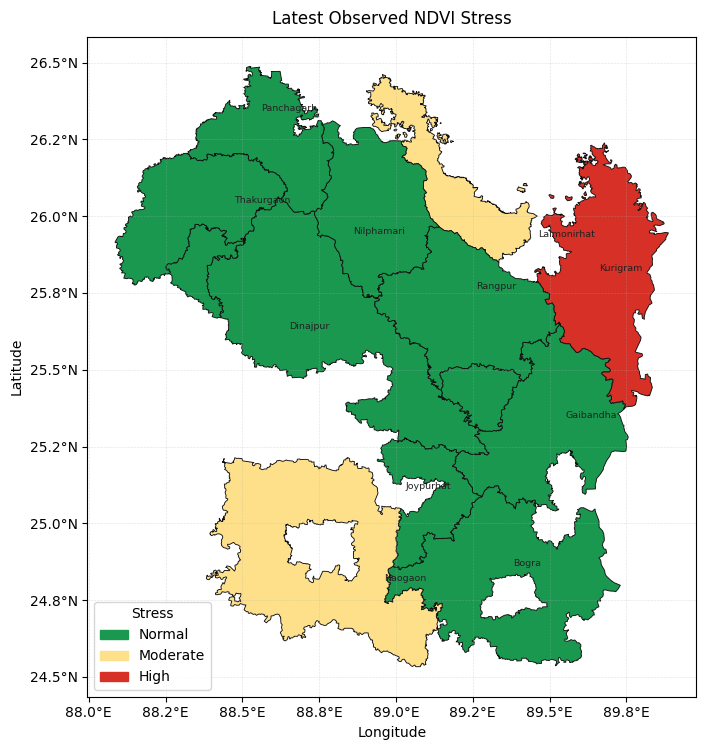

Saved figure: outputs_ndvi_era5_stress/figures/21a_paper_latest_observed_same_records_stratified_random_80_20_oversample_geojson_district_polygons.png at 500 dpi


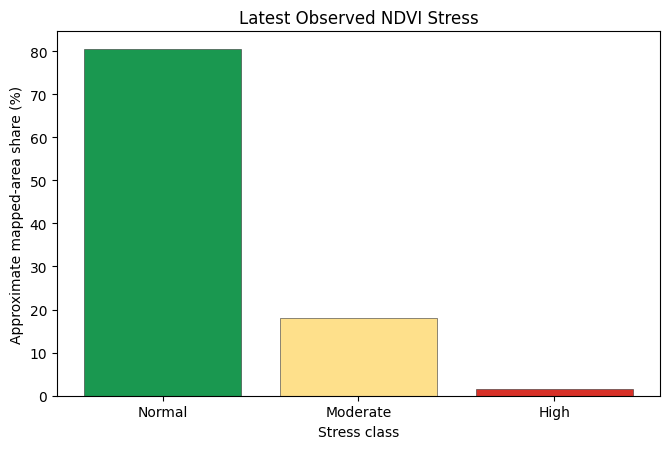

Saved figure: outputs_ndvi_era5_stress/figures/21a_paper_latest_observed_same_records_stratified_random_80_20_oversample_geojson_area_share.png at 500 dpi


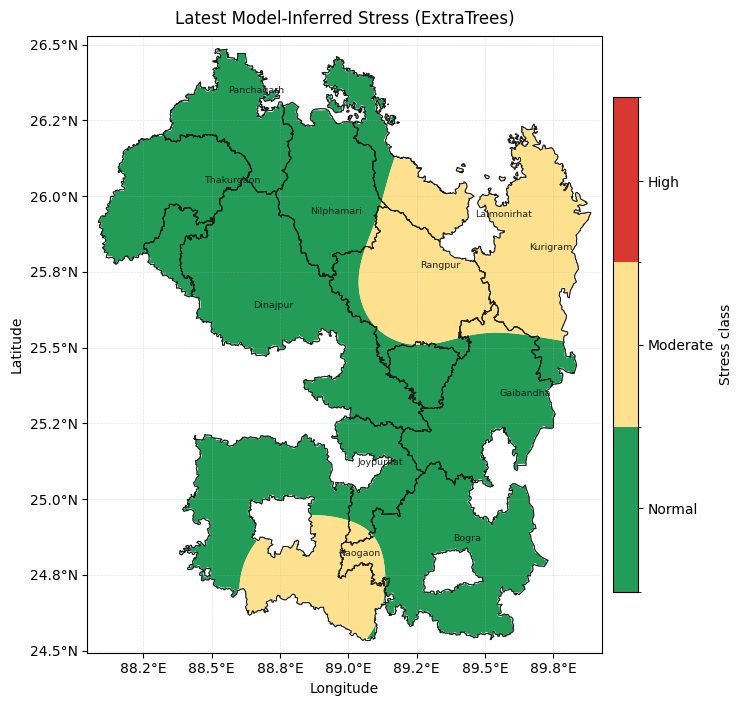

Saved figure: outputs_ndvi_era5_stress/figures/21b_paper_latest_model_inferred_same_records_stratified_random_80_20_oversample_geojson_clipped_surface.png at 500 dpi


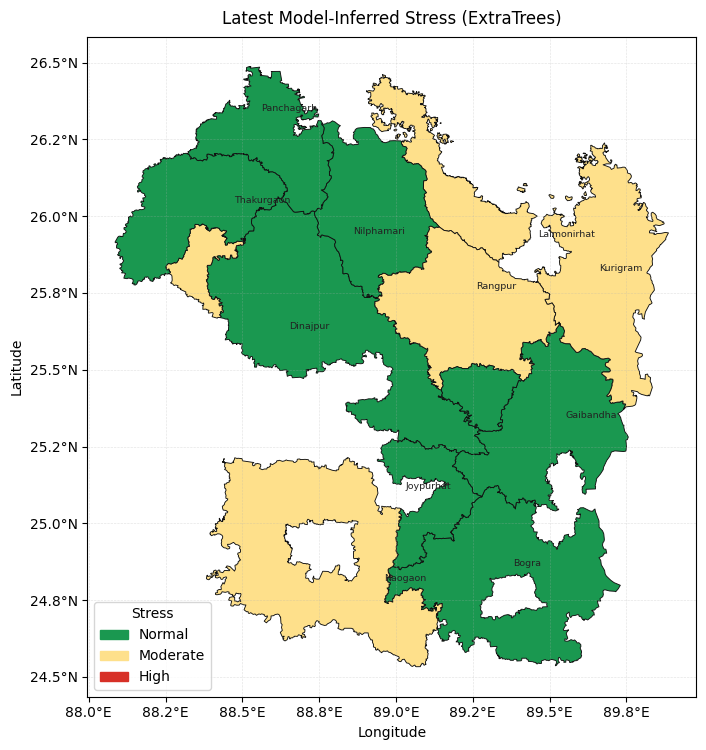

Saved figure: outputs_ndvi_era5_stress/figures/21b_paper_latest_model_inferred_same_records_stratified_random_80_20_oversample_geojson_district_polygons.png at 500 dpi


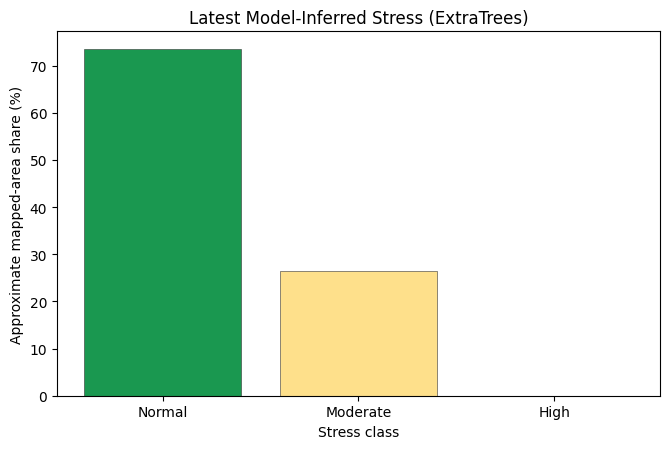

Saved figure: outputs_ndvi_era5_stress/figures/21b_paper_latest_model_inferred_same_records_stratified_random_80_20_oversample_geojson_area_share.png at 500 dpi


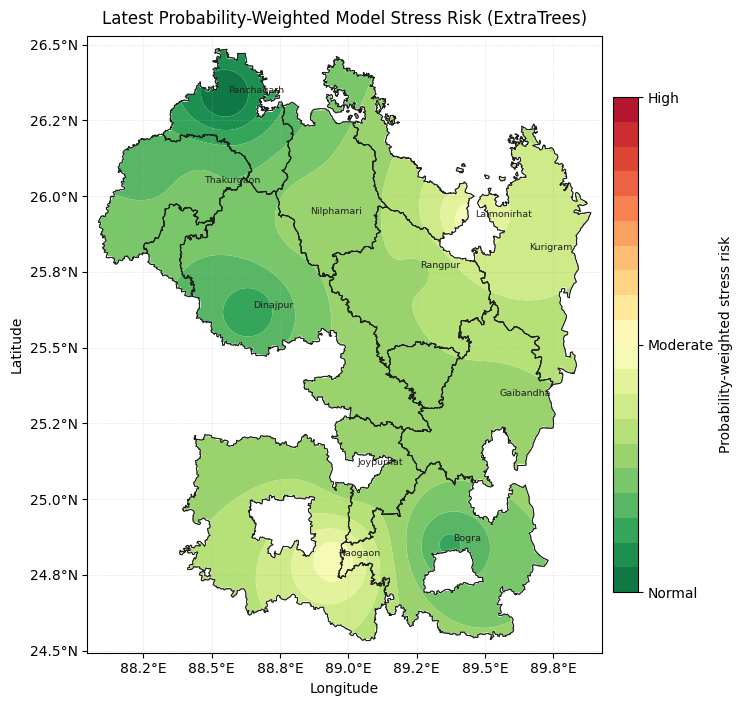

Saved figure: outputs_ndvi_era5_stress/figures/21c_paper_latest_probability_weighted_risk_stratified_random_80_20_oversample_continuous_risk_surface.png at 500 dpi


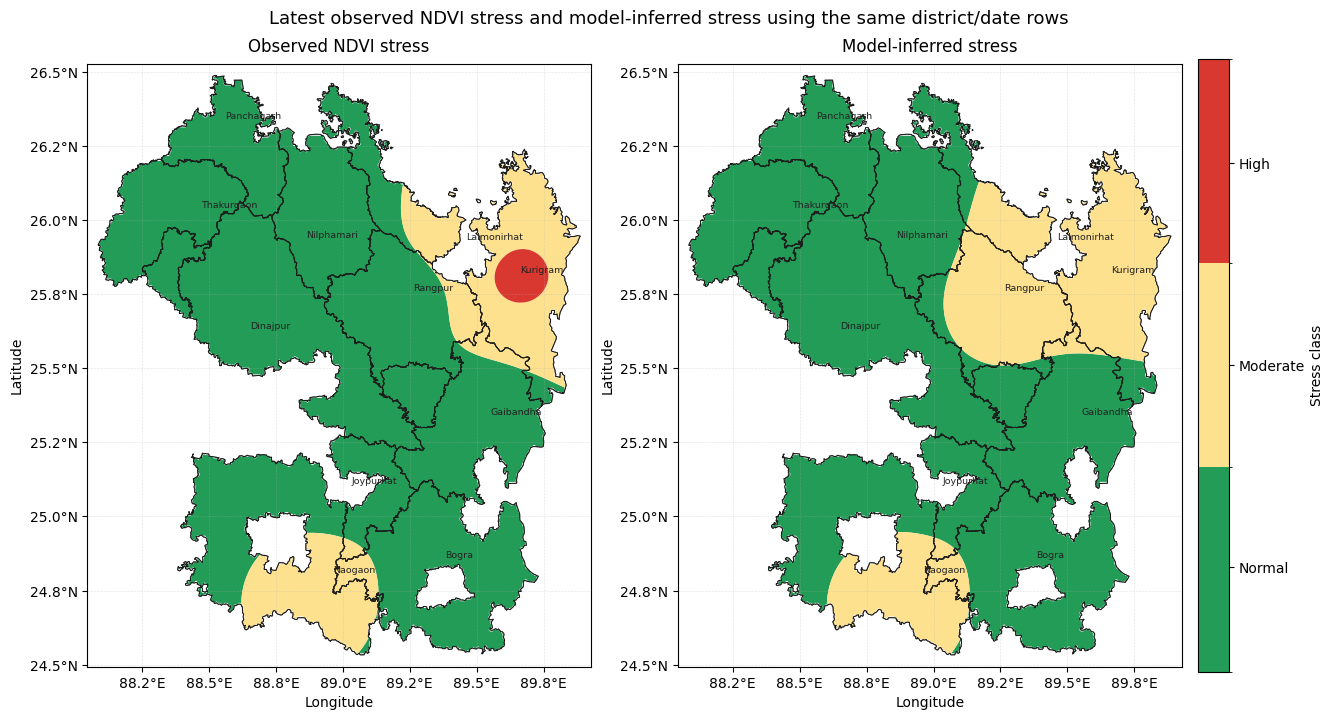

Saved figure: outputs_ndvi_era5_stress/figures/paper_ready/21d_paper_same_records_stratified_random_80_20_oversample_observed_vs_model_side_by_side.png


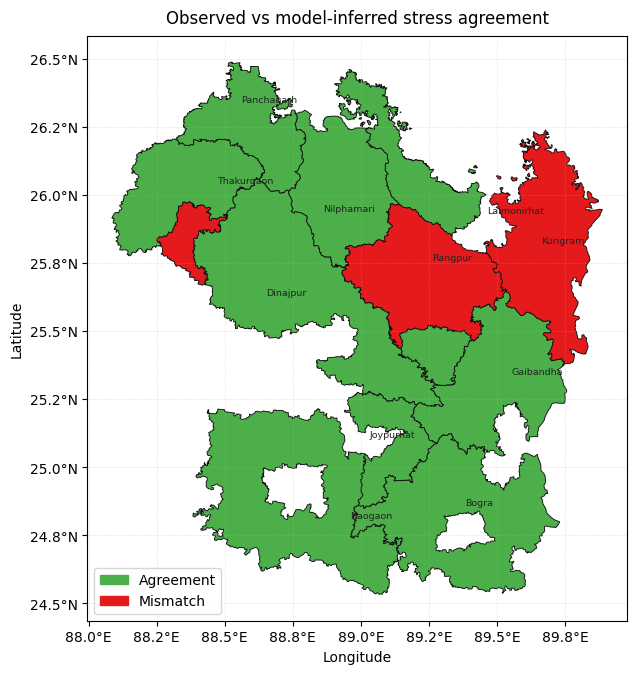

Saved figure: outputs_ndvi_era5_stress/figures/paper_ready/22_paper_same_records_stratified_random_80_20_oversample_agreement_map.png


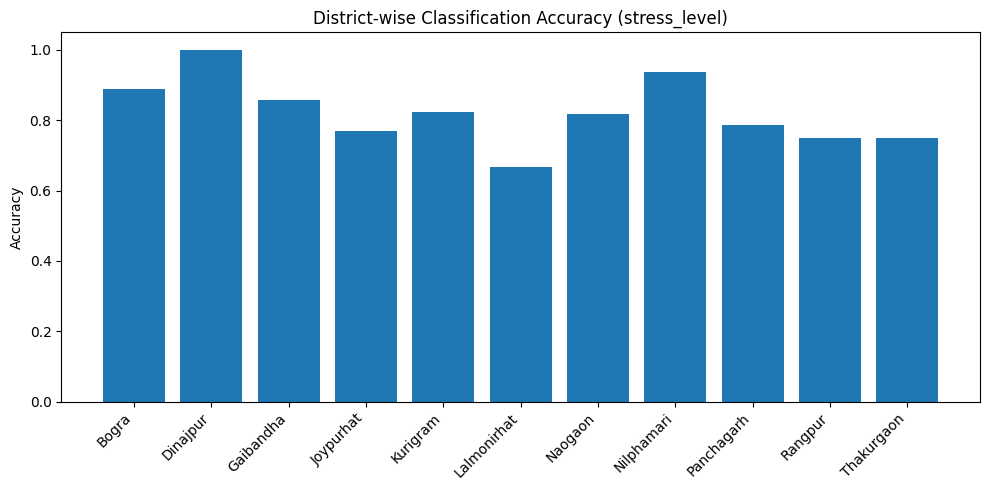

Saved figure: outputs_ndvi_era5_stress/figures/10_district_accuracy_stress_level_stratified_random_80_20_oversample.png at 500 dpi

Running permutation importance...


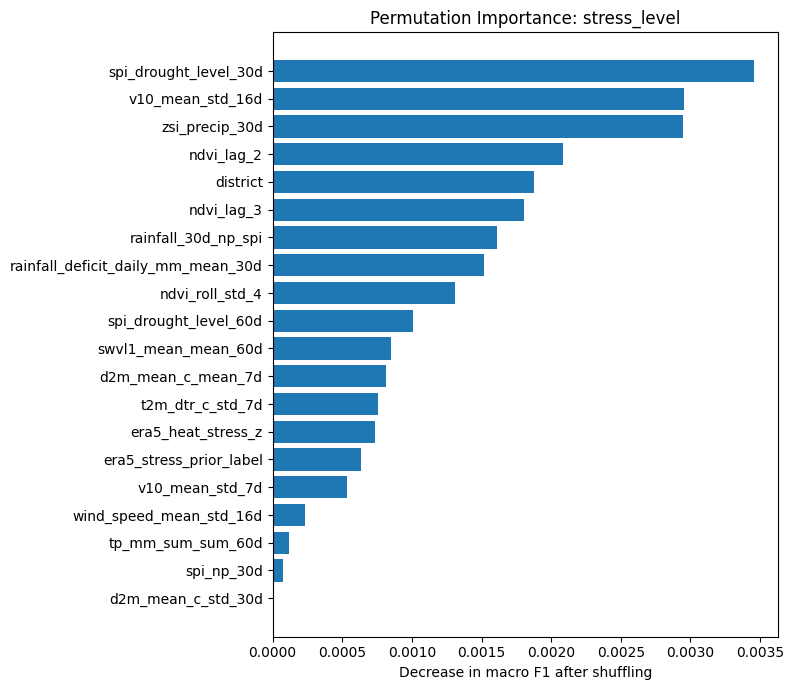

Saved figure: outputs_ndvi_era5_stress/figures/11_permutation_importance_stress_level_stratified_random_80_20.png at 500 dpi

Running SHAP TreeExplainer...


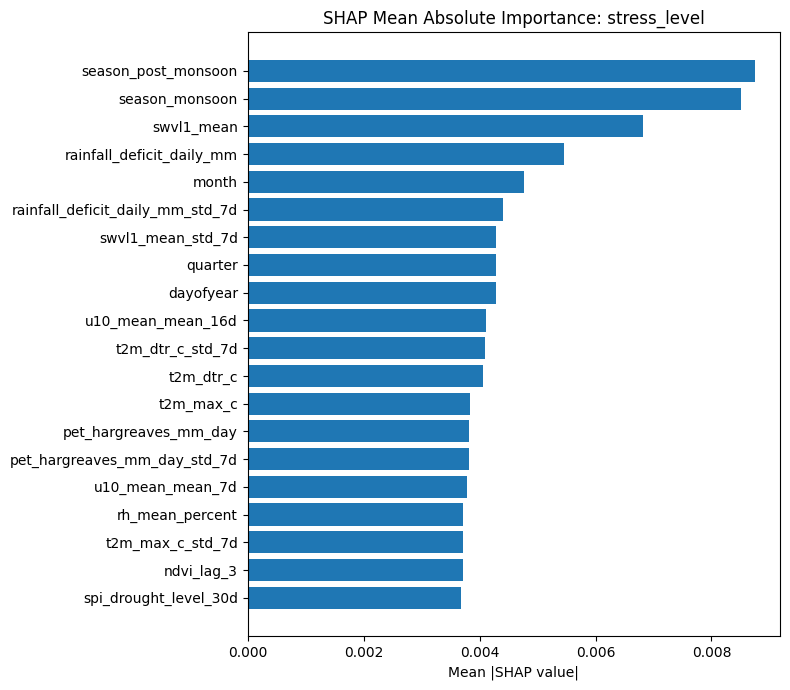

Saved figure: outputs_ndvi_era5_stress/figures/12_shap_bar_stress_level_stratified_random_80_20.png at 500 dpi


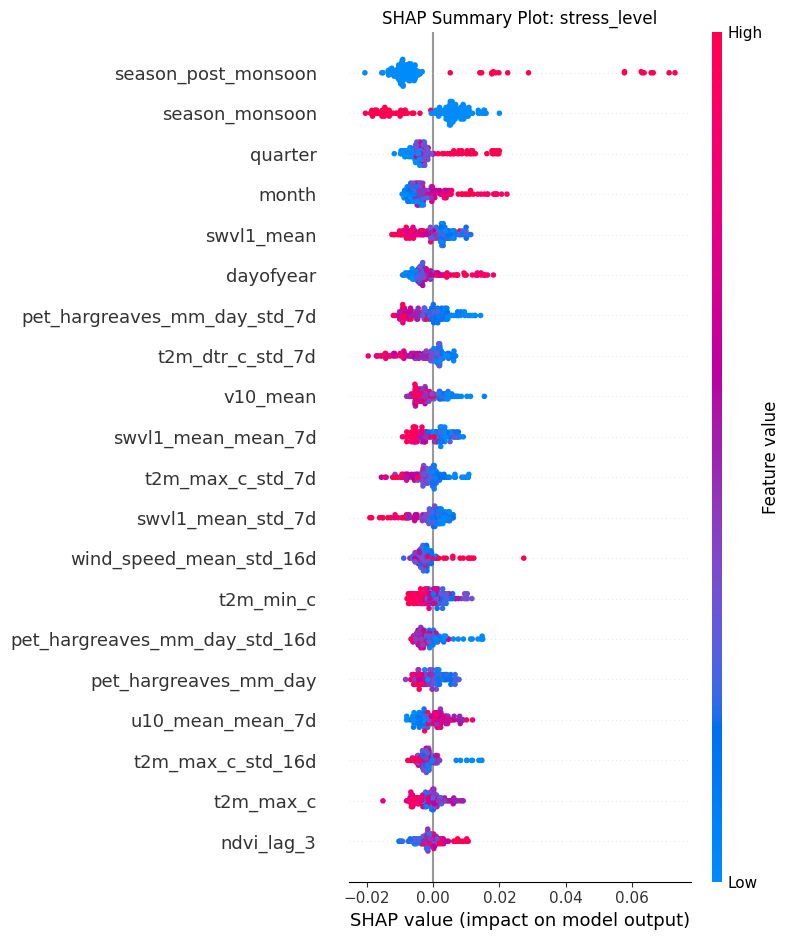

Saved figure: outputs_ndvi_era5_stress/figures/13_shap_summary_stress_level_stratified_random_80_20.png at 500 dpi

Pipeline finished.
Processed data saved in: outputs_ndvi_era5_stress/processed_data
Figures saved in: outputs_ndvi_era5_stress/figures
Models saved in: outputs_ndvi_era5_stress/models

Key outputs for your paper:
- processed_data/latest_actual_stress_by_district.csv
- processed_data/district_observed_stress_frequency.csv
- processed_data/latest_predicted_stress_level_stratified_random_80_20_oversample.csv
- figures/01a_location_map_era5_grid_districts.png
- figures/01b_location_map_idw_links.png
- figures/01c_interactive_location_map_era5_grid_districts.html  # if folium is installed
- figures/14_latest_observed_stress_surface.png
- figures/paper_ready/21d_paper_same_records_*_observed_vs_model_side_by_side.png
- figures/15_latest_era5_climate_stress_prior_surface.png
- figures/16_observed_stress_frequency_surface.png
- figures/17_district_stress_composition_stacked_bar.p

In [31]:
# =========================

def main():
    print("Starting NDVI + ERA5 V4 multiclass SPI/SPEI/ZSI ensemble vegetation stress pipeline...")

    ndvi = load_clean_ndvi(NDVI_PATH)
    ndvi_min, ndvi_max = ndvi["date"].min(), ndvi["date"].max()

    # Step A: Null filling. If the output already exists, reuse it only when it looks complete.
    if FILL_ERA5_NULLS_WITH_ZERO:
        reuse_filled = False
        if ERA5_FILLED_PATH.exists():
            raw_size = ERA5_RAW_PATH.stat().st_size
            filled_size = ERA5_FILLED_PATH.stat().st_size
            reuse_filled = filled_size >= raw_size * 0.95
            if not reuse_filled:
                print("Existing null-filled ERA5 file looks incomplete; regenerating it...")
                ERA5_FILLED_PATH.unlink(missing_ok=True)
        if not reuse_filled:
            fill_nulls_in_large_csv(ERA5_RAW_PATH, ERA5_FILLED_PATH, chunksize=CHUNKSIZE)
        ERA5_FOR_PROCESSING = ERA5_FILLED_PATH
    else:
        ERA5_FOR_PROCESSING = ERA5_RAW_PATH

    # Step B: Process ERA5 to daily grid/district table.
    daily = process_era5_to_daily(ERA5_FOR_PROCESSING, ndvi_min, ndvi_max)

    # Step B2: Better-looking location maps using actual ERA5 grid coordinates plus NDVI district centroids.
    make_location_maps_from_era5_and_districts(daily)

    # Step C: Convert grid-level climate to district-level climate with IDW if needed.
    district_daily = spatial_match_to_districts(daily)

    # Step C2: Add calculative ERA5 drought features before rolling windows.
    district_daily = add_daily_pet_water_balance(district_daily)

    # Step D: Build rolling climate features, add SPI/SPEI/ZSI-style drought indices, and merge to NDVI dates.
    climate_features = add_rolling_climate_features(district_daily, ROLLING_WINDOWS)
    climate_features = add_spi_spei_zsi_features(climate_features, test_year=TEST_YEAR)
    fused = merge_ndvi_era5(ndvi, climate_features)

    # Step E: Target construction from training-year NDVI climatology.
    final_df = add_targets_train_climatology(fused, test_year=TEST_YEAR)

    # Step E2: Valid ERA5-derived stress-prior feature. This is NOT a fake label column.
    # It is computed from heat, VPD, rainfall deficit, soil-moisture deficit, and wind.
    final_df = add_era5_derived_stress_features(final_df, test_year=TEST_YEAR)

    # Step F: Visual analysis, trend analysis, and where-stress maps/tables.
    trend_df = make_basic_visualizations(final_df)
    make_spatial_stress_visualizations(final_df)
    print("\nDistrict trends:")
    print(trend_df)

    # Step G: Multiclass model only.
    # Default is an accuracy-oriented stratified 80/20 split to be comparable with many ML papers.
    # The strict temporal check is run separately if RUN_SECONDARY_TEMPORAL_CHECK=True.
    best_level, level_results = fit_classification_models(
        final_df,
        target_col="stress_level",
        label_names=["normal_good", "moderate_stress", "high_stress"],
        balance_strategy="oversample",
        validation_mode=VALIDATION_MODE,
        selection_metric=MODEL_SELECTION_METRIC,
    )
    explain_model_xai(final_df, target_col="stress_level", best_pipe=best_level, validation_mode=VALIDATION_MODE)

    if RUN_SECONDARY_TEMPORAL_CHECK and VALIDATION_MODE != "temporal_2024":
        print("\nRunning secondary strict 2024 temporal check for transparency...")
        best_temporal, temporal_results = fit_classification_models(
            final_df,
            target_col="stress_level",
            label_names=["normal_good", "moderate_stress", "high_stress"],
            balance_strategy="oversample",
            validation_mode="temporal_2024",
            selection_metric="macro_f1",
        )
        # XAI is done for the main selected model only to keep runtime manageable.
        temporal_results.to_csv(DATA_DIR / "secondary_temporal_check_results.csv", index=False)

    print("\nPipeline finished.")
    print(f"Processed data saved in: {DATA_DIR}")
    print(f"Figures saved in: {FIG_DIR}")
    print(f"Models saved in: {MODEL_DIR}")
    print("\nKey outputs for your paper:")
    print("- processed_data/latest_actual_stress_by_district.csv")
    print("- processed_data/district_observed_stress_frequency.csv")
    print(f"- processed_data/latest_predicted_stress_level_{VALIDATION_MODE}_oversample.csv")
    print("- figures/01a_location_map_era5_grid_districts.png")
    print("- figures/01b_location_map_idw_links.png")
    print("- figures/01c_interactive_location_map_era5_grid_districts.html  # if folium is installed")
    print("- figures/14_latest_observed_stress_surface.png")
    print("- figures/paper_ready/21d_paper_same_records_*_observed_vs_model_side_by_side.png")
    print("- figures/15_latest_era5_climate_stress_prior_surface.png")
    print("- figures/16_observed_stress_frequency_surface.png")
    print("- figures/17_district_stress_composition_stacked_bar.png")
    print("- figures/08_combined_ndvi_era5_standardized_trend.png  # regional mean across districts")
    print("- figures/08b_combined_ndvi_era5_minmax_normalized_trend.png  # regional mean across districts")
    print("- figures/08c_combined_ndvi_era5_correlation_matrix.png")
    print("- figures/08d_districtwise_combined_ndvi_era5_minmax_small_multiples.png")
    print("- figures/districtwise_combined_ndvi_era5/08e_*_combined_ndvi_era5_minmax.png")
    print("- processed_data/08d_districtwise_ndvi_era5_monthly_series.csv")
    print(f"- figures/18_latest_predicted_stress_surface_{VALIDATION_MODE}_oversample.png")
    print("- figures/19_polygon_latest_observed_stress_map.png  # only if GeoJSON is provided")
    print("- figures/20_land_area_stress_share_latest_observed.png  # only if GeoJSON is provided")
    print(f"- figures/11_permutation_importance_stress_level_{VALIDATION_MODE}.png")
    print(f"- figures/12_shap_bar_stress_level_{VALIDATION_MODE}.png")
    print(f"- figures/13_shap_summary_stress_level_{VALIDATION_MODE}.png")
    print("- processed_data/05b_created_spi_spei_zsi_features.csv")
    print(f"- processed_data/model_results_stress_level_{VALIDATION_MODE}_oversample.csv")
    print("- processed_data/secondary_temporal_check_results.csv  # if secondary temporal check is enabled")


if __name__ == "__main__":
    main()